# Steps 1-2 · Underwater drones (client: Fincantieri)

Combined notebook: **Part A = Step 1 (general description of the sector)**, **Part B = Step 2 (competitive landscape)**.

Both parts read the clean tables written by `02_clean` and need no PATSTAT query. Each part keeps its own setup cell
(imports, configuration, data loading, plotting style), so Part B re-initialises its settings on purpose (e.g. `OUT`, `TOP_N`, colours):
run the notebook top to bottom. Every cell of the two original notebooks is preserved, in the original order.


# Step 1 · General description of the sector: Underwater drones (client: Fincantieri)

This notebook answers the four questions of Step 1 of the deck and writes every figure and table of the technical appendix.

| Kick-off question | Section |
|---|---|
| How big is the field, and is it growing, flat or declining? | 2 Volume · 3 Growth vs all patents and vs ships/marine (B63) |
| Where is the field on its technological trajectory? | 4 Life cycle (S-curve, product vs process) |
| Which technologies make up the field, and how is the mix shifting? | 5 CPC subclasses · WIPO fields · recombination |
| Where is it happening? | 6 Filing offices (IP5) · origin · applicant and inventor countries |
| Is the field patent-heavy, or does it rely on secrecy? | 7 Evidence from the data + argued paragraph (literature to add) |

**Inputs.** Nothing is queried from PATSTAT: everything is computed with pandas from the CSVs written by `02_clean`
(`outputs/<env>/step1/`). The numbers are **provisional until Step 0 is closed** (label adjudication, final sector); afterwards
re-run `01_extract`, `02_clean` and this notebook, nothing else changes.

**Three samples.** Besides the whole sector ("all"), the main results are repeated on *without block-6-only* (the weakest
block of the query, precision about 48%) and on *international* (families filed at more than one office: the part of the
sector that is protected beyond its first market). If a conclusion changes with the sample, say so in the deck.

**Counting rules** (state them in the appendix, see section 9): DOCDB family dated by earliest priority year; the last 3
years are incomplete (shaded, never read as a decline, excluded from every growth figure); fractional counting for classes
and countries; every figure says whether it counts families or applications.



## 1. Setup and data

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import MaxNLocator, PercentFormatter
from scipy.optimize import curve_fit

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)


def find_config():
    """Folder with config.py: this folder, its parent, or the step_0 folder next to it."""
    here = Path.cwd().resolve()
    for d in (here, here.parent, here.parent / "step_0_HL", here / "step_0_HL"):
        if (d / "config.py").exists():
            return d
    raise FileNotFoundError("config.py not found: run from the folder with config.py or from a folder next to step_0_HL")


BASE = find_config()
sys.path.insert(0, str(BASE))
import config as C                       # the same configuration as Step 0 (env, years, sector name)
from pw_utils import wilson              # the same Wilson interval as Step 0

IN = BASE / C.OUT_STEP1                  # written by 02_clean
OUT = Path("outputs") / C.ENV.lower() / "step2_description"
FIG_DIR, TAB_DIR = OUT / "figures", OUT / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

SECTOR = C.SECTOR_NAME
Y0, Y1, LAST = C.YEAR_MIN, C.YEAR_MAX, C.LAST_COMPLETE_YEAR          # LAST = last complete year
BASE_YEAR = LAST - 10                    # growth base: the last decade (2000 has a few dozen families, growth from it is unstable)
PAST, RECENT = (LAST - 9, LAST - 5), (LAST - 4, LAST)                 # two complete 5-year windows
GRANT_MAX_YEAR = LAST - 3                # families old enough to have been examined
TOP_N = 8                                # categories shown in figures; the rest is "Other"
IP5 = ("CN", "US", "KR", "JP", "EP")
LEVELS = ("family", "application")
UNIT = {"family": "families", "application": "applications"}

NAVY, BLUE, ORANGE, GREY, GREEN, RED = "#1F3A5F", "#2E7DB5", "#E8833A", "#8A8F98", "#3E8E5A", "#C0392B"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "axes.prop_cycle": plt.cycler(color=[NAVY, ORANGE, BLUE, GREEN, RED, GREY])})


def read(name, cols=None, **kw):
    path = IN / name
    if not path.exists():
        raise FileNotFoundError(f"{path} not found: run 02_clean first (check config.ENV / PW_IPR_TYPE)")
    return pd.read_csv(path, usecols=(lambda c: c in cols) if cols else None, **kw)


def to_bool(s):
    return s.astype(str).str.lower().eq("true")


def shade(ax):
    ax.axvspan(LAST + 0.5, Y1 + 0.5, color="grey", alpha=0.15, lw=0, label="incomplete years")


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")


def save_table(df, name, **kw):
    df.to_csv(TAB_DIR / f"{name}.csv", **kw)


def two_panels(title, **kw):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), **kw)
    fig.suptitle(title, fontweight="bold")
    return fig, axes


def cagr(s, a, b):
    """Compound annual growth rate (%) between years a and b."""
    return ((s.loc[b] / s.loc[a]) ** (1 / (b - a)) - 1) * 100 if s.loc[a] > 0 else np.nan


KEY = {}                                 # headline numbers, written to key_numbers.json (section 8)

# ---------------------------------------------------------------- families (one row per DOCDB family)
FAM_COLS = {"docdb_family_id", "family_year", "is_truncated", "first_office", "offices", "via_pct", "is_international",
            "n_offices", "has_ep", "granted_any", "block_combo", "n_subclasses", "title_en", "title"}
families = read("families.csv", cols=FAM_COLS, low_memory=False)
for c in ("is_truncated", "via_pct", "is_international", "has_ep", "granted_any"):
    families[c] = to_bool(families[c])
families = families[families["family_year"].between(Y0, Y1)].copy()
fo = families["first_office"].astype(str).str.strip()
families["origin_group"] = np.select([fo == "CN", fo == "US", fo.isin(["KR", "JP"]), fo.isin(["EP", "WO"])],
                                     ["China", "United States", "Korea & Japan", "EP / PCT first"],
                                     default="Europe & rest of world")
families["b6_only"] = families["block_combo"].astype(str).eq("b6")

# ---------------------------------------------------------------- applications (one row per appln_id)
applications = read("applications.csv", cols={"appln_id", "docdb_family_id", "appln_auth", "appln_kind", "appln_filing_year",
                                              "earliest_publn_year", "earliest_filing_year", "family_year", "is_pct",
                                              "in_appln_window", "is_granted"}, low_memory=False)
for c in ("is_pct", "in_appln_window", "is_granted"):
    applications[c] = to_bool(applications[c])
apps = applications[applications["in_appln_window"]].copy()          # application level: filing year inside the window
fam_year_map = families.set_index("docdb_family_id")["family_year"]
app_year_map = apps.set_index("appln_id")["appln_filing_year"]

# ---------------------------------------------------------------- the three samples
SAMPLES = {"all": set(families["docdb_family_id"]),
           "without block-6-only": set(families.loc[~families["b6_only"], "docdb_family_id"]),
           "international": set(families.loc[families["is_international"], "docdb_family_id"])}

print(f"{SECTOR} | env {C.ENV} | years {Y0}-{Y1} | complete up to {LAST} | growth base year {BASE_YEAR}")
print(f"families: {len(families):,} (incomplete years {LAST + 1}-{Y1}: {(families['family_year'] > LAST).sum():,}, "
      f"{(families['family_year'] > LAST).mean():.1%}) | applications in window: {len(apps):,}")
display(pd.DataFrame({"families": {k: len(v) for k, v in SAMPLES.items()},
                      "% of the sector": {k: round(len(v) / len(families) * 100, 1) for k, v in SAMPLES.items()}}))

Underwater drones | env PROD | years 2000-2025 | complete up to 2022 | growth base year 2012
families: 15,755 (incomplete years 2023-2025: 5,764, 36.6%) | applications in window: 20,406


,families,% of the sector
all,15755,100.0
without block-6-only,11968,76.0
international,1329,8.4


## 2. Volume
Family level = inventions (earliest priority year). Application level = filings at each office (filing year of each
application). The grey area marks the years still incomplete because of the 18-month publication lag: they are **not** a
decline of the sector. The gap between the two curves is the average number of filings per invention.

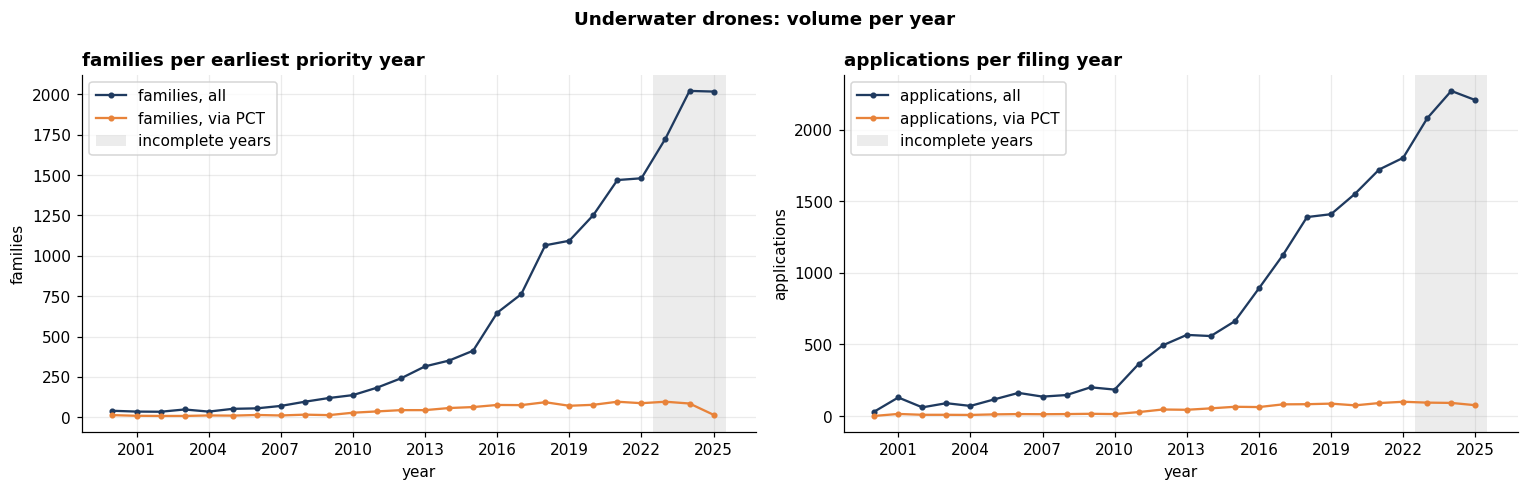

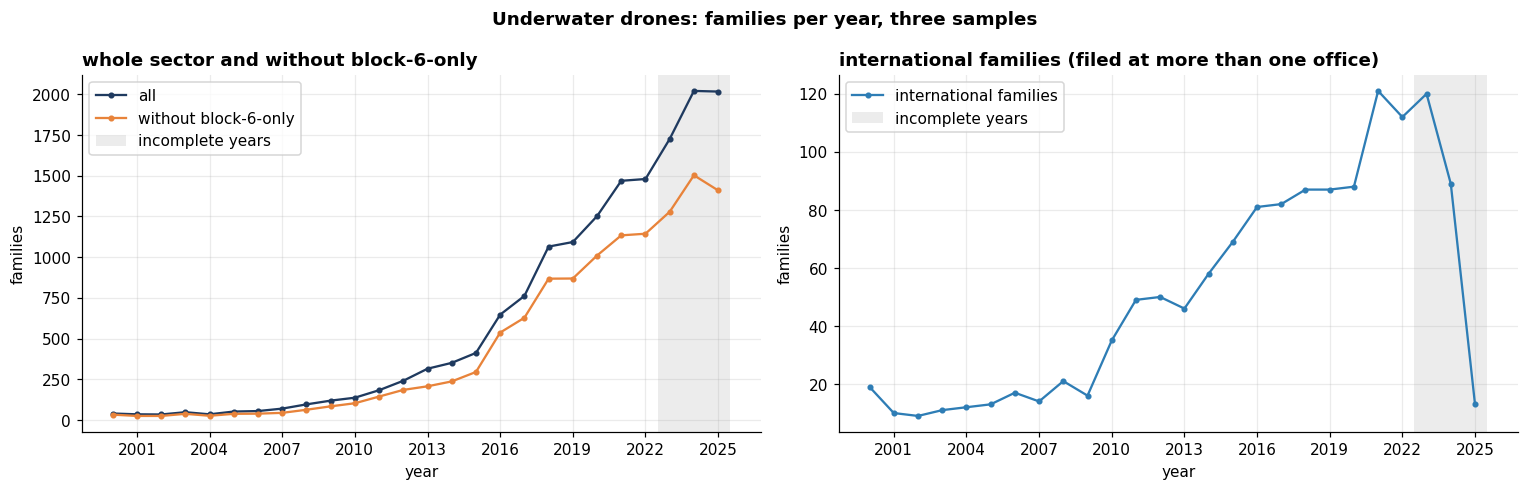

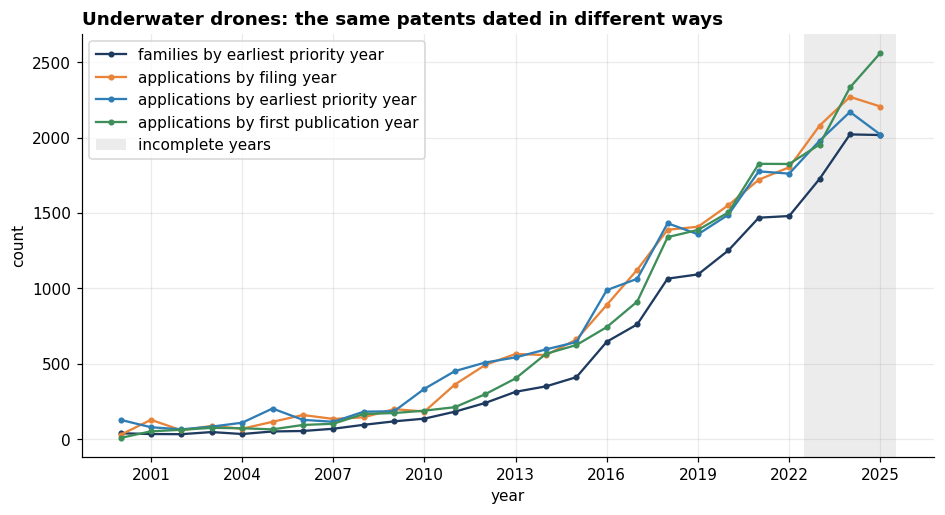

complete years 2000-2022: 9,991 families | incomplete years: 5,764 families (36.6% of the sector)


In [2]:
years = range(Y0, Y1 + 1)


def per_year(df, col):
    return df.groupby(col).size().reindex(years, fill_value=0)


fam_year = per_year(families, "family_year")
fam_pct = per_year(families[families["via_pct"]], "family_year")
app_year = per_year(apps, "appln_filing_year")
app_pct = per_year(apps[apps["is_pct"]], "appln_filing_year")
vol_samples = pd.DataFrame({name: per_year(families[families["docdb_family_id"].isin(ids)], "family_year")
                            for name, ids in SAMPLES.items()})

# (appendix) both levels side by side
fig, axes = two_panels(f"{SECTOR}: volume per year", sharex=True)
for ax, level, total, pct in zip(axes, LEVELS, (fam_year, app_year), (fam_pct, app_pct)):
    ax.plot(total.index, total.values, marker="o", ms=3, label=f"{UNIT[level]}, all")
    ax.plot(pct.index, pct.values, marker="o", ms=3, label=f"{UNIT[level]}, via PCT")
    shade(ax)
    ax.set(title=f"{UNIT[level]} per " + ("earliest priority year" if level == "family" else "filing year"),
           xlabel="year", ylabel=UNIT[level])
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend()
plt.tight_layout()
save(fig, "fig_volume")
plt.show()

volume = pd.DataFrame({"families": fam_year, "families_via_pct": fam_pct, "applications": app_year,
                       "applications_via_pct": app_pct}).join(vol_samples.add_prefix("families_"))
volume["incomplete_year"] = volume.index > LAST
save_table(volume, "tab_volume_per_year")

# (appendix) the three samples. The "international" flag needs the second filing to be already in PATSTAT,
# so its last 2 years are certainly incomplete: read that panel up to LAST only.
fig, axes = two_panels(f"{SECTOR}: families per year, three samples")
ax = axes[0]
for name, color in zip(("all", "without block-6-only"), (NAVY, ORANGE)):
    ax.plot(vol_samples.index, vol_samples[name], marker="o", ms=3, color=color, label=name)
shade(ax)
ax.set(title="whole sector and without block-6-only", xlabel="year", ylabel="families")
ax.legend()
ax = axes[1]
ax.plot(vol_samples.index, vol_samples["international"], marker="o", ms=3, color=BLUE, label="international families")
shade(ax)
ax.set(title="international families (filed at more than one office)", xlabel="year", ylabel="families")
ax.legend()
for ax in axes:
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout()
save(fig, "fig_volume_samples")
plt.show()

# (appendix) the same patents dated in different ways
prio_col = "earliest_filing_year" if "earliest_filing_year" in apps else "family_year"
dating = {"families by earliest priority year": fam_year,
          "applications by filing year": app_year,
          "applications by earliest priority year": per_year(apps[apps[prio_col].between(Y0, Y1)], prio_col),
          "applications by first publication year": per_year(apps[apps["earliest_publn_year"].between(Y0, Y1)], "earliest_publn_year")}
fig, ax = plt.subplots(figsize=(10, 5))
for label, s in dating.items():
    ax.plot(s.index, s.values, marker="o", ms=3, label=label)
shade(ax)
ax.set(title=f"{SECTOR}: the same patents dated in different ways", xlabel="year", ylabel="count")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend()
save(fig, "fig_dating")
plt.show()

print(f"complete years {Y0}-{LAST}: {int(fam_year.loc[:LAST].sum()):,} families | incomplete years: "
      f"{int(fam_year.loc[LAST + 1:].sum()):,} families ({fam_year.loc[LAST + 1:].sum() / fam_year.sum():.1%} of the sector)")

**How to read it.** Dating by publication shifts the curve about 18 months to the right and makes recent years look complete;
dating by priority places each invention at its origin; the family curve is lower because every invention counts once.

## 3. Growth: is the sector growing faster than patenting as a whole?
Benchmarks: **all patents** and the neighbouring field **B63** (ships and marine technology), with the same counting rules
(`benchmark_*_per_year.csv` from `02_clean`). The sector series is recomputed from `families.csv`, so it always matches the
current sector. Incomplete years are excluded from every growth figure.

The sector had only a few dozen families in 2000, so growth between the two end years is huge and unstable. We therefore
also report the growth between 3-year averages, the annual growth rate (CAGR) over the last decade, and the **share of the
sector in all patents**, the most robust measure of "gaining weight".

In [3]:
bench = {"family": read("benchmark_families_per_year.csv", index_col="year"),
         "application": read("benchmark_applications_per_year.csv", index_col="year")}
NEIGH = [c for c in bench["family"].columns if str(c).startswith("neighbour")]
BENCH_NAMES = ["all patents"] + NEIGH
for level, s in zip(LEVELS, (fam_year, app_year)):
    bench[level][SECTOR] = s                                 # follow the current sector, not the file's old column

S = {("family", SECTOR): fam_year,
     ("family", f"{SECTOR}, without block-6-only"): vol_samples["without block-6-only"],
     ("family", f"{SECTOR}, international only"): vol_samples["international"],
     ("application", SECTOR): app_year}
for level in LEVELS:
    for name in BENCH_NAMES:
        S[(level, name)] = bench[level][name]
S = dict(sorted(S.items(), key=lambda kv: (LEVELS.index(kv[0][0]))))

rows = []
for (level, name), s in S.items():
    s = s.astype(float).reindex(years)
    a3, b3 = s.loc[Y0:Y0 + 2].mean(), s.loc[LAST - 2:LAST].mean()
    rows.append({"level": level, "series": name, f"count {Y0}": s.loc[Y0], f"count {LAST}": s.loc[LAST],
                 f"growth {Y0}-{LAST} (%)": (s.loc[LAST] / s.loc[Y0] - 1) * 100 if s.loc[Y0] else np.nan,
                 "growth of 3-year averages (%)": (b3 / a3 - 1) * 100 if a3 else np.nan,
                 f"CAGR {Y0}-{LAST} (%)": cagr(s, Y0, LAST),
                 f"CAGR {BASE_YEAR}-{LAST} (%)": cagr(s, BASE_YEAR, LAST)})
growth = pd.DataFrame(rows).set_index(["level", "series"])
save_table(growth.round(1), "tab_growth")
display(growth.style.format({c: ("{:,.0f}" if c.startswith("count") else "{:+.1f}%") for c in growth.columns}))

# sanity check: a benchmark year far from the median of its neighbours is suspicious (print it, then look at the series)
for level in LEVELS:
    for name in BENCH_NAMES:
        s = bench[level][name].astype(float).loc[Y0:LAST]
        around = pd.concat([s.shift(1), s.shift(-1), s.shift(2), s.shift(-2)], axis=1).median(axis=1)
        ratio = s / around
        for y, r in ratio[(ratio < 0.75) | (ratio > 1.25)].dropna().items():
            print(f"CHECK {level} / {name}: {y} is {s.loc[y]:,.0f}, {r:.2f}x the median of the surrounding years")

CHECK family / neighbour B63: 2015 is 3,567, 0.54x the median of the surrounding years


Underwater drones: families grow +19.9% a year over 2012-2022, all patents +5.5%; the sector's share of all patents goes from 0.17 to 0.62 per mille.


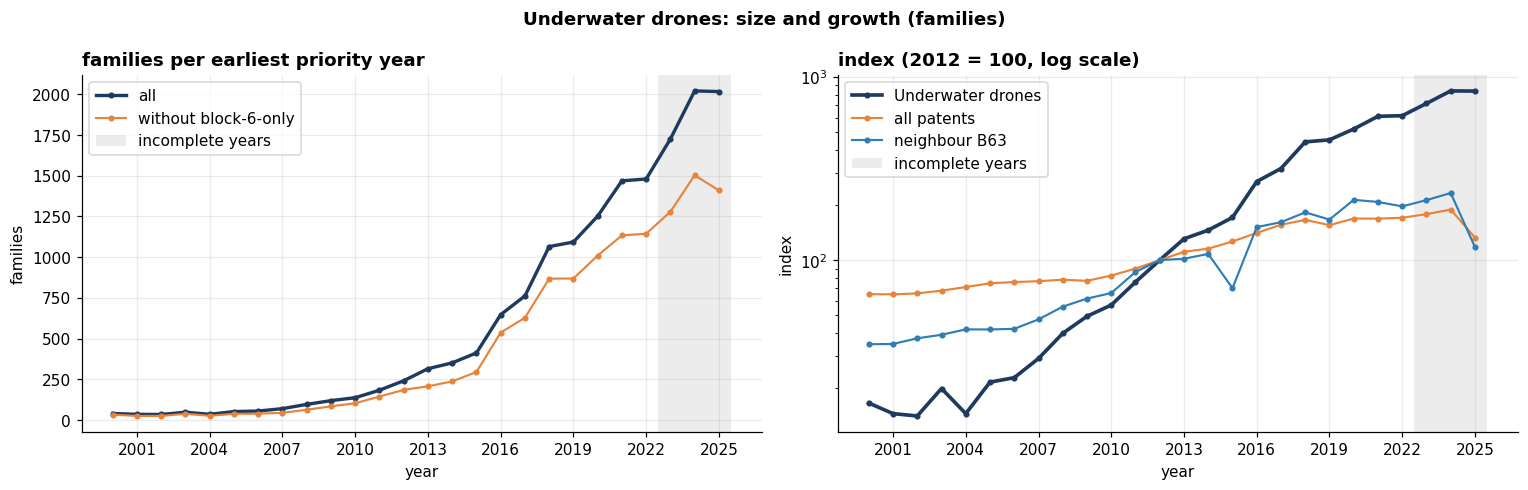

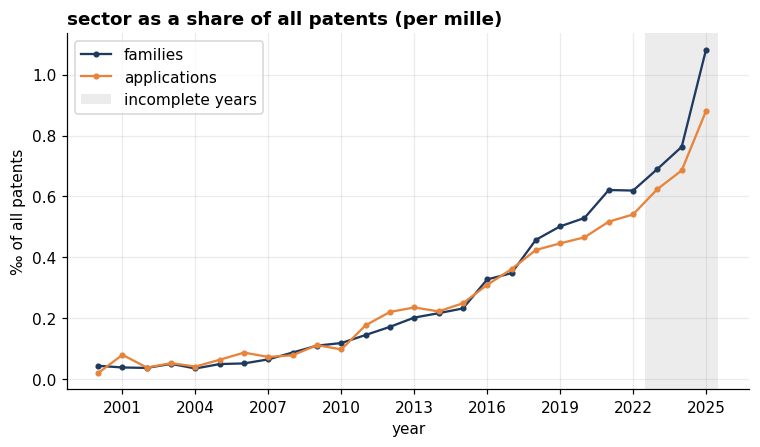

In [4]:
share = pd.DataFrame({lvl: bench[lvl][SECTOR].astype(float) / bench[lvl]["all patents"].astype(float) * 1000
                      for lvl in LEVELS}).loc[Y0:Y1]                                  # per mille of all patents
save_table(share.round(4), "tab_share_of_all_patents_permille")

fg = growth.loc[("family", SECTOR)]
g_sec, g_all = fg[f"CAGR {BASE_YEAR}-{LAST} (%)"], growth.loc[("family", "all patents"), f"CAGR {BASE_YEAR}-{LAST} (%)"]
KEY.update({f"sector CAGR {BASE_YEAR}-{LAST} (%)": round(g_sec, 1), f"all patents CAGR {BASE_YEAR}-{LAST} (%)": round(g_all, 1),
            f"sector share of all patents, {BASE_YEAR} (per mille)": round(share.loc[BASE_YEAR, "family"], 3),
            f"sector share of all patents, {LAST} (per mille)": round(share.loc[LAST, "family"], 3)})
for n in NEIGH:
    KEY[f"{n} CAGR {BASE_YEAR}-{LAST} (%)"] = round(growth.loc[("family", n), f"CAGR {BASE_YEAR}-{LAST} (%)"], 1)
print(f"{SECTOR}: families grow {g_sec:+.1f}% a year over {BASE_YEAR}-{LAST}, all patents {g_all:+.1f}%; the sector's share of all "
      f"patents goes from {share.loc[BASE_YEAR, 'family']:.2f} to {share.loc[LAST, 'family']:.2f} per mille.")

# DECK FIGURE: volume (left) and growth against the benchmarks (right)
fig, axes = two_panels(f"{SECTOR}: size and growth (families)")
ax = axes[0]
for name, color in zip(("all", "without block-6-only"), (NAVY, ORANGE)):
    ax.plot(vol_samples.index, vol_samples[name], marker="o", ms=3, color=color, lw=2.2 if name == "all" else 1.4, label=name)
shade(ax)
ax.set(title="families per earliest priority year", xlabel="year", ylabel="families")
ax.legend()
ax = axes[1]
for name in [SECTOR] + BENCH_NAMES:
    s = bench["family"][name].astype(float).loc[Y0:Y1]
    ax.plot(s.index, s / s.loc[BASE_YEAR] * 100, marker="o", ms=3, lw=2.4 if name == SECTOR else 1.4, label=name)
shade(ax)
ax.set_yscale("log")
ax.set(title=f"index ({BASE_YEAR} = 100, log scale)", xlabel="year", ylabel="index")
ax.legend()
for ax in axes:
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout()
save(fig, "fig_deck_volume_growth")
plt.show()

# (appendix) share of all patents, both levels
fig, ax = plt.subplots(figsize=(8, 4.2))
for lvl in LEVELS:
    ax.plot(share.index, share[lvl], marker="o", ms=3, label=UNIT[lvl])
shade(ax)
ax.set(title="sector as a share of all patents (per mille)", xlabel="year", ylabel="‰ of all patents")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend()
save(fig, "fig_share_of_all")
plt.show()

**Read the share, not only the growth rates.** If the sector grows faster than all patents its share rises: it is gaining weight in
technology; if it grows slower it is growing, but less than patenting overall. Incomplete years are shaded because the
sector and the benchmark are not truncated in the same way (the sector, dominated by Chinese filings, appears earlier in PATSTAT),
so the share in those years is inflated: never quote it.

## 4. Life cycle: where is the sector on its trajectory?
*Course link: technological trajectories (S-curves), dominant designs, product and process innovation (Utterback & Abernathy, 1975).*

A logistic curve is fitted to the **cumulative** number of families up to the last complete year. Three cautions: (i) read the
inflection year `t0` and the share of `K` reached, not `K`, which is poorly identified while the curve is still rising;
(ii) the fit quality is measured on the **annual** counts (R² on a cumulative series is always close to 1);
(iii) an inflection after the last complete year means that the bend is **not observed**. The last row adds the first
incomplete year, as a sensitivity.

,"K (saturation, families)",r (growth rate),t0 (inflection year),R2 on annual counts,share of K reached,inflection inside the data
all,"28,234",0.26,2024.3,0.99,35%,False
without block-6-only,"19,642",0.28,2023.5,0.99,40%,False
international,"2,003",0.21,2021.1,0.96,55%,True
"all, up to 2023 (sensitivity)","27,256",0.26,2024.1,0.99,43%,False


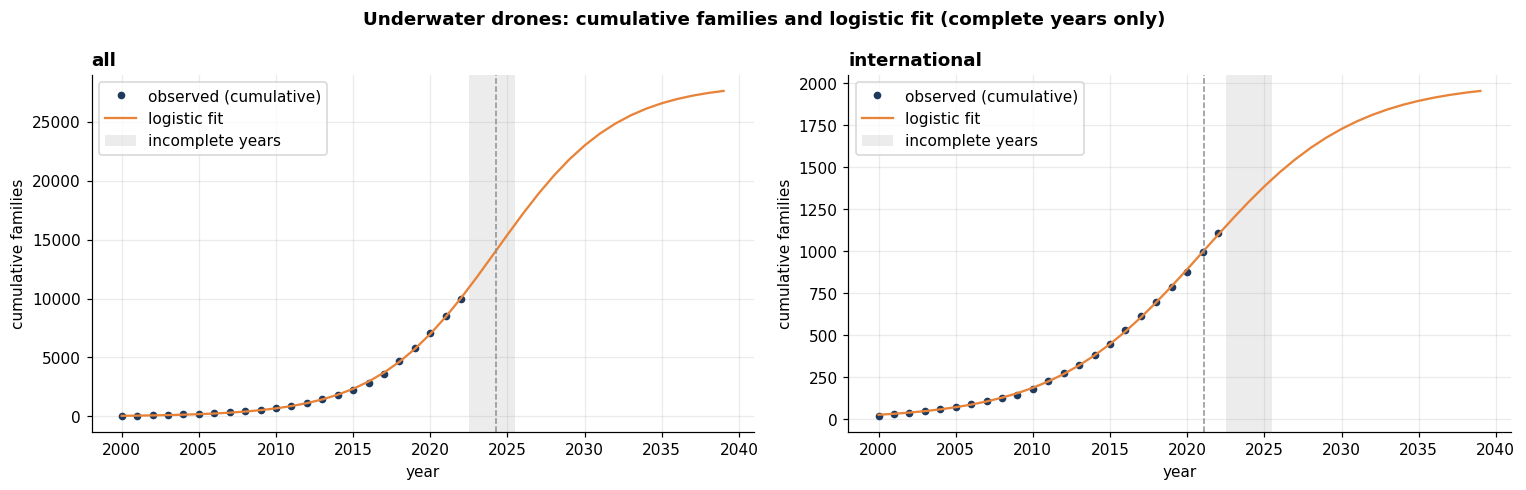

In [5]:
def logistic(t, K, r, t0):
    return K / (1 + np.exp(-r * (t - t0)))


def fit_s_curve(yearly, last=LAST):
    s = yearly.loc[:last].cumsum()
    t, y = s.index.values.astype(float), s.values.astype(float)
    empty = {"K (saturation, families)": np.nan, "r (growth rate)": np.nan, "t0 (inflection year)": np.nan,
             "R2 on annual counts": np.nan, "share of K reached": np.nan, "inflection inside the data": False}
    try:
        p, _ = curve_fit(logistic, t, y, p0=[y[-1] * 2, 0.3, t[-1]],
                         bounds=([y[-1], 0.01, t[0]], [y[-1] * 50, 2.0, t[-1] + 30]), maxfev=20000)
    except Exception:
        return empty
    obs = yearly.loc[:last].values.astype(float)
    fit = logistic(t, *p) - logistic(t - 1, *p)
    r2 = 1 - ((obs - fit) ** 2).sum() / ((obs - obs.mean()) ** 2).sum()
    return {"K (saturation, families)": p[0], "r (growth rate)": p[1], "t0 (inflection year)": p[2], "R2 on annual counts": r2,
            "share of K reached": y[-1] / p[0], "inflection inside the data": bool(p[2] <= last)}


life = {name: fit_s_curve(vol_samples[name]) for name in SAMPLES}
life[f"all, up to {LAST + 1} (sensitivity)"] = fit_s_curve(vol_samples["all"], last=LAST + 1)
life = pd.DataFrame(life).T
save_table(life.round(3), "tab_s_curve")
display(life.style.format({"K (saturation, families)": "{:,.0f}", "r (growth rate)": "{:.2f}", "t0 (inflection year)": "{:.1f}",
                           "R2 on annual counts": "{:.2f}", "share of K reached": "{:.0%}"}, na_rep="-"))

fig, axes = two_panels(f"{SECTOR}: cumulative families and logistic fit (complete years only)")
for ax, name in zip(axes, ("all", "international")):
    cum = vol_samples[name].loc[:LAST].cumsum()
    ax.plot(cum.index, cum.values, "o", ms=4, color=NAVY, label="observed (cumulative)")
    p = life.loc[name]
    if not p.isna().any():
        tt = np.arange(Y0, Y1 + 15)
        ax.plot(tt, logistic(tt, p["K (saturation, families)"], p["r (growth rate)"], p["t0 (inflection year)"]),
                color=ORANGE, label="logistic fit")
        ax.axvline(p["t0 (inflection year)"], color=GREY, ls="--", lw=1)
    shade(ax)
    ax.set(title=f"{name}", xlabel="year", ylabel="cumulative families")
    ax.legend()
plt.tight_layout()
save(fig, "fig_s_curve")
plt.show()

### 4.1 Product or process? (dominant-design proxy)
Three shares of families: title mentions a *method / process*; title names a *device, apparatus, system, equipment or vehicle*
(a title can have both: "method and device"); title mentions *control, navigation, path planning, positioning or tracking*, a
proxy of the move from hardware towards software and autonomy. It is a rough proxy: look at the trend, and read a sample of titles
before writing it in the deck. A rising method share points to innovation moving from the product towards control, software and
process; a stable one, to a product phase (Utterback & Abernathy, 1975).

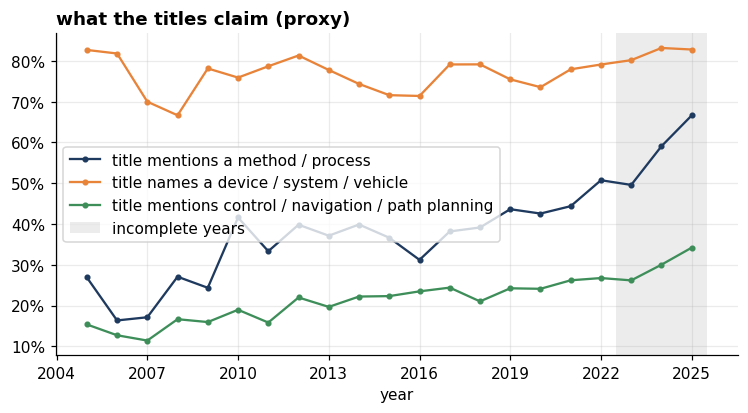

[22.4, 44.1] [14.4, 24.5]


In [6]:
title = families["title_en"].fillna(families["title"]).fillna("").astype(str).str.lower()
families["is_method_title"] = title.str.contains(r"\b(?:method|process)\b", regex=True)
families["is_product_title"] = title.str.contains(r"\b(?:device|apparatus|system|equipment|vehicle|robot|machine)\b", regex=True)
families["is_control_title"] = title.str.contains(
    r"\b(?:control|controlling|controller|navigation|navigating|path[\s-]*planning|route[\s-]*planning|trajectory|obstacle|positioning|localization|localisation|tracking)\b", regex=True)
PROC_COLS = ["is_method_title", "is_product_title", "is_control_title"]
proc = families[families["family_year"].between(2005, Y1)].groupby("family_year")[PROC_COLS].mean() * 100
proc_c = proc.loc[:LAST]
KEY["share of method/process titles, first 5 / last 5 complete years (%)"] = [round(float(proc_c["is_method_title"].iloc[:5].mean()), 1),
                                                                               round(float(proc_c["is_method_title"].iloc[-5:].mean()), 1)]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(proc.index, proc["is_method_title"], marker="o", ms=3, color=NAVY, label="title mentions a method / process")
ax.plot(proc.index, proc["is_product_title"], marker="o", ms=3, color=ORANGE, label="title names a device / system / vehicle")
ax.plot(proc.index, proc["is_control_title"], marker="o", ms=3, color=GREEN, label="title mentions control / navigation / path planning")
shade(ax)
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.set(title="what the titles claim (proxy)", xlabel="year")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend()
save(fig, "fig_process_proxy")
plt.show()
save_table(proc.round(2), "tab_process_proxy")
KEY["share of control/navigation titles, first 5 / last 5 complete years (%)"] = [round(float(proc_c["is_control_title"].iloc[:5].mean()), 1),
                                                                                  round(float(proc_c["is_control_title"].iloc[-5:].mean()), 1)]
print(KEY["share of method/process titles, first 5 / last 5 complete years (%)"], KEY["share of control/navigation titles, first 5 / last 5 complete years (%)"])

## 5. Technology mix

### 5.1 CPC subclasses
Fractional counting: a family (or application) is split equally among its CPC subclasses, so shares sum to 100%.
The **Y** tagging section (Y02/Y10) marks cross-cutting themes (climate, transport), not technologies: the mix leaves it out
(`weight_tech` of `02_clean`), otherwise a tag would appear as the fastest-growing "technology". The titles below are the official CPC
titles as we recall them: **verify them on the CPC scheme before the deck** (https://www.cooperativepatentclassification.org).
"Role" is our own short reading, not an official definition.

,family,application,"CPC title (official, verify)",role in the sector (our reading)
subclass,,,,
B63G,17.0%,19.0%,Offensive or defensive arrangements on vessels; mine-laying; mine-sweeping; submarines; aircraft carriers,submarines and unmanned underwater vehicles
B63C,14.9%,13.0%,"Launching, hauling-out or dry-docking of vessels; life-saving in water; equipment for dwelling or working underwater; means for searching for or salvaging underwater objects","underwater work, launch and recovery"
G05D,8.2%,6.8%,Systems for controlling or regulating non-electric variables,"navigation, path and depth control"
B63B,6.9%,8.3%,Ships or other waterborne vessels; equipment for shipping,hulls and ship equipment
B63H,4.4%,4.0%,Marine propulsion or steering,propulsion and steering
G01S,4.4%,4.2%,Radio direction-finding; radio navigation; determining distance or velocity by use of radio waves; locating or presence-detecting by use of the reflection or reradiation of radio waves; analogous arrangements using other waves,sonar and positioning
G01C,4.1%,3.4%,"Measuring distances, levels or bearings; surveying; navigation; gyroscopic instruments; photogrammetry or videogrammetry",navigation and surveying
B25J,3.7%,3.4%,Manipulators; chambers provided with manipulation devices,manipulator arms
G05B,2.9%,2.2%,Control or regulating systems in general; functional elements of such systems; monitoring or testing arrangements for such systems or elements,


share of the family-subclass weight that is in the Y tagging section (left out of the mix): 7.2%


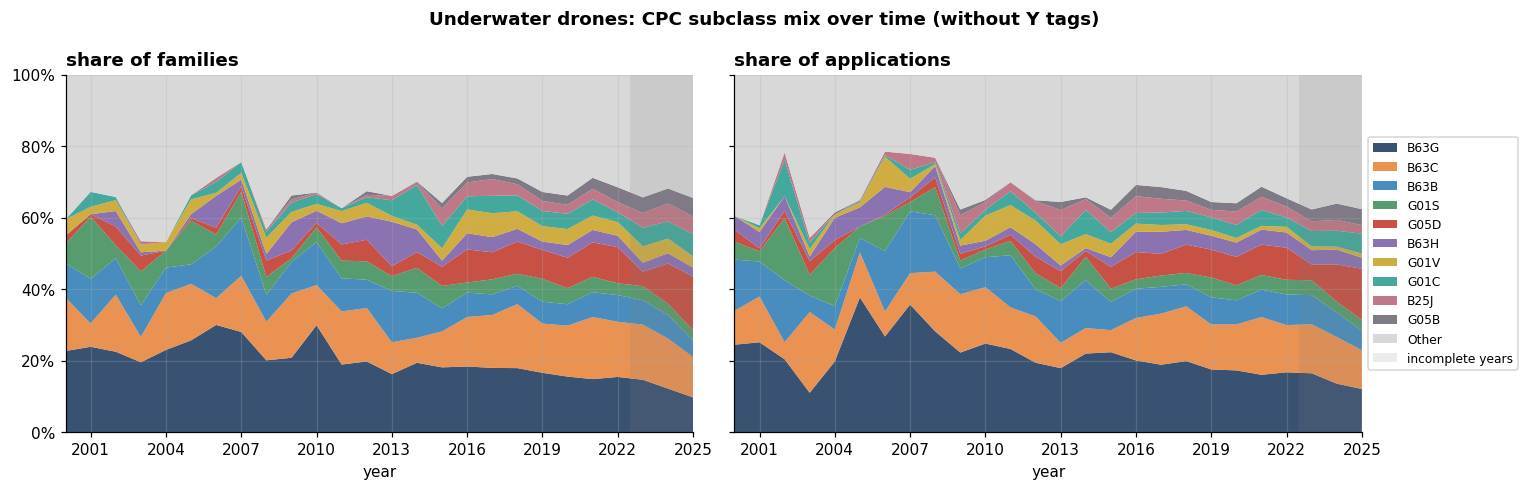

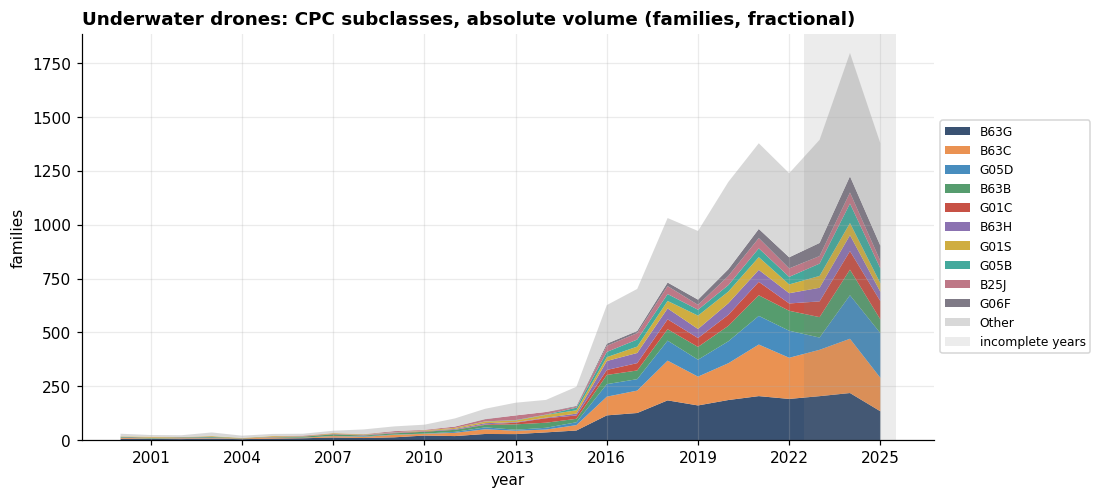

In [7]:
CPC_TITLE = {   # official titles, to be verified on the CPC scheme
    "B63G": "Offensive or defensive arrangements on vessels; mine-laying; mine-sweeping; submarines; aircraft carriers",
    "B63C": "Launching, hauling-out or dry-docking of vessels; life-saving in water; equipment for dwelling or working underwater; means for searching for or salvaging underwater objects",
    "B63B": "Ships or other waterborne vessels; equipment for shipping",
    "B63H": "Marine propulsion or steering",
    "B63J": "Auxiliaries on vessels",
    "G05D": "Systems for controlling or regulating non-electric variables",
    "G05B": "Control or regulating systems in general; functional elements of such systems; monitoring or testing arrangements for such systems or elements",
    "G01S": "Radio direction-finding; radio navigation; determining distance or velocity by use of radio waves; locating or presence-detecting by use of the reflection or reradiation of radio waves; analogous arrangements using other waves",
    "G01C": "Measuring distances, levels or bearings; surveying; navigation; gyroscopic instruments; photogrammetry or videogrammetry",
    "G01N": "Investigating or analysing materials by determining their chemical or physical properties",
    "G01V": "Geophysics; gravitational measurements; detecting masses or objects; tags",
    "B25J": "Manipulators; chambers provided with manipulation devices",
    "B08B": "Cleaning in general; prevention of fouling in general",
    "G06F": "Electric digital data processing",
    "G06N": "Computing arrangements based on specific computational models",
    "G06T": "Image data processing or generation, in general",
    "G06V": "Image or video recognition or understanding",
    "H04B": "Transmission",
    "H04N": "Pictorial communication, e.g. television",
    "H02J": "Circuit arrangements or systems for supplying or distributing electric power; systems for storing electric energy",
    "H01M": "Processes or means, e.g. batteries, for the direct conversion of chemical energy into electrical energy",
    "F16L": "Pipes; joints or fittings for pipes; supports for pipes, cables or protective tubing; means for thermal insulation in general",
    "E21B": "Earth or rock drilling; obtaining oil, gas, water, soluble or meltable materials or a slurry of minerals from wells",
    "B64U": "Unmanned aerial vehicles [UAV]; equipment therefor",
}
CPC_ROLE = {
    "B63G": "submarines and unmanned underwater vehicles", "B63C": "underwater work, launch and recovery",
    "B63B": "hulls and ship equipment", "B63H": "propulsion and steering", "G05D": "navigation, path and depth control",
    "G01S": "sonar and positioning", "G01C": "navigation and surveying", "B25J": "manipulator arms",
    "G06N": "AI / machine learning", "G06T": "underwater image processing", "H04B": "underwater communication",
    "H02J": "charging and power supply", "B08B": "hull and net cleaning", "H01M": "batteries and fuel cells",
}

fs = read("family_subclass.csv")
fs = fs[fs["docdb_family_id"].isin(fam_year_map.index)].copy()
fs["year"] = fs["docdb_family_id"].map(fam_year_map)
fsw = fs.dropna(subset=["weight_tech"]).copy()                                    # families with at least one non-Y subclass
asub = read("application_subclass.csv")
asub = asub[asub["appln_id"].isin(app_year_map.index)].copy()
asub["year"] = asub["appln_id"].map(app_year_map)
asub = asub[~asub["subclass"].str.startswith("Y")].copy()                         # same rule as weight_tech
asub["weight_tech"] = 1 / asub.groupby("appln_id")["subclass"].transform("size")


def complete(df):
    return df[df["year"] <= LAST]


def pool_other(df, cat, value, n=TOP_N):
    top = complete(df).groupby(cat)[value].sum().nlargest(n).index
    out = df.assign(**{cat: df[cat].where(df[cat].isin(top), "Other")})
    return out.groupby([cat, "year"], as_index=False)[value].sum()


def share_table(counts):
    """Counts -> percentages that sum to 100 in each column, 'Other' last, and a 'Total' row."""
    shares = counts / counts.sum() * 100
    order = [c for c in shares.sort_values(shares.columns[0], ascending=False).index if c != "Other"]
    order += ["Other"] if "Other" in shares.index else []
    shares = shares.loc[order]
    shares.loc["Total"] = shares.sum()
    return shares


def share_over_time(df, cat, value):
    wide = df.pivot_table(index="year", columns=cat, values=value, aggfunc="sum", fill_value=0)
    wide = wide.div(wide.sum(axis=1), axis=0) * 100
    order = complete(wide.reset_index()).set_index("year").sum().sort_values(ascending=False).index
    return wide[[c for c in order if c != "Other"] + (["Other"] if "Other" in wide else [])]


def stack_100(ax, shares, title):
    palette = [NAVY, ORANGE, BLUE, GREEN, RED, "#7B5EA7", "#C9A227", "#2A9D8F", "#B56576", "#6D6875"]
    colors = ["lightgrey" if c == "Other" else palette[i % len(palette)] for i, c in enumerate(shares.columns)]
    ax.stackplot(shares.index, shares.T.values, labels=shares.columns, colors=colors, alpha=0.88)
    shade(ax)
    ax.set(title=title, xlabel="year", xlim=(Y0, Y1), ylim=(0, 100))
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))


top10 = complete(fsw).groupby("subclass")["weight_tech"].sum().nlargest(10).index        # same rows for both levels


def pool_to(df, keep):
    out = df.assign(subclass=df["subclass"].where(df["subclass"].isin(keep), "Other"))
    return out.groupby(["subclass", "year"], as_index=False)["weight_tech"].sum()


counts = pd.DataFrame({"family": complete(pool_to(fsw, top10)).groupby("subclass")["weight_tech"].sum(),
                       "application": complete(pool_to(asub, top10)).groupby("subclass")["weight_tech"].sum()}).fillna(0)
cpc_tab = share_table(counts)
cpc_tab["CPC title (official, verify)"] = [CPC_TITLE.get(s, "(fill in from the CPC scheme)") if s not in ("Other", "Total") else ""
                                           for s in cpc_tab.index]
cpc_tab["role in the sector (our reading)"] = [CPC_ROLE.get(s, "") for s in cpc_tab.index]
save_table(cpc_tab.round(2), "tab_cpc_subclasses")
display(cpc_tab.style.format("{:.1f}%", subset=list(LEVELS)))

fc = complete(fs)
y_share = fc.loc[fc["subclass"].str.startswith("Y"), "weight"].sum() / fc["weight"].sum()
print(f"share of the family-subclass weight that is in the Y tagging section (left out of the mix): {y_share:.1%}")
KEY["top-3 CPC subclasses (families, % of weight)"] = {s: round(float(cpc_tab.loc[s, "family"]), 1) for s in cpc_tab.index[:3]}

# DECK FIGURE: CPC mix over time
fig, axes = two_panels(f"{SECTOR}: CPC subclass mix over time (without Y tags)", sharey=True)
for ax, level in zip(axes, LEVELS):
    data = fsw if level == "family" else asub
    stack_100(ax, share_over_time(pool_other(data, "subclass", "weight_tech", n=10), "subclass", "weight_tech"), f"share of {UNIT[level]}")
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
plt.tight_layout()
save(fig, "fig_cpc_mix")
plt.show()

# (appendix) absolute volumes: shares can hide growth
fig, ax = plt.subplots(figsize=(10, 4.8))
wide = pool_other(fsw, "subclass", "weight_tech", n=10).pivot_table(index="year", columns="subclass", values="weight_tech",
                                                              aggfunc="sum", fill_value=0)
order = [c for c in wide.sum().sort_values(ascending=False).index if c != "Other"] + (["Other"] if "Other" in wide else [])
palette = [NAVY, ORANGE, BLUE, GREEN, RED, "#7B5EA7", "#C9A227", "#2A9D8F", "#B56576", "#6D6875"]
colors = ["lightgrey" if c == "Other" else palette[i % len(palette)] for i, c in enumerate(order)]
ax.stackplot(wide.index, wide[order].T.values, labels=order, colors=colors, alpha=0.88)
shade(ax)
ax.set(title=f"{SECTOR}: CPC subclasses, absolute volume (families, fractional)", xlabel="year", ylabel="families")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
save(fig, "fig_cpc_absolute")
plt.show()

**Which subclasses gain and lose weight?** Share of each subclass in two complete 5-year windows (families, fractional).
The change in percentage points is the shift of the mix; a small share can still be the fastest-growing technology, so look
also at the absolute volumes above. The right-hand table repeats the mix on the three samples: a technology that is
strong in the whole sector but absent among international families is mostly a domestic (largely Chinese) phenomenon.

In [8]:
def window_share(df, period):
    d = df[df["year"].between(*period)]
    s = d.groupby("subclass")["weight_tech"].sum()
    return s / s.sum()


mix_shift = pd.DataFrame({f"share {PAST[0]}-{PAST[1]}": window_share(fsw, PAST),
                          f"share {RECENT[0]}-{RECENT[1]}": window_share(fsw, RECENT)}).fillna(0) * 100
mix_shift["change (pp)"] = mix_shift.iloc[:, 1] - mix_shift.iloc[:, 0]
mix_shift = mix_shift[mix_shift.iloc[:, 1].gt(0.5) | mix_shift.iloc[:, 0].gt(0.5)].sort_values("change (pp)")
mix_shift["CPC title (official, verify)"] = [CPC_TITLE.get(s, "") for s in mix_shift.index]
save_table(mix_shift.round(2), "tab_cpc_shift")
display(pd.concat([mix_shift.head(6), mix_shift.tail(6)]).drop_duplicates().style.format(
    {c: "{:.1f}" for c in mix_shift.columns if c != "CPC title (official, verify)"}))

by_sample = {}
for name, ids in SAMPLES.items():
    s = complete(fsw[fsw["docdb_family_id"].isin(ids)]).groupby("subclass")["weight_tech"].sum()
    by_sample[name] = (s / s.sum() * 100).reindex(top10).fillna(0)
by_sample = pd.DataFrame(by_sample)
by_sample.loc["Other"] = 100 - by_sample.sum()
save_table(by_sample.round(2), "tab_cpc_by_sample")
display(by_sample.style.format("{:.1f}%"))

,share 2013-2017,share 2018-2022,change (pp),"CPC title (official, verify)"
subclass,,,,
B63G,18.1,16.0,-2.1,Offensive or defensive arrangements on vessels; mine-laying; mine-sweeping; submarines; aircraft carriers
B25J,4.9,3.2,-1.7,Manipulators; chambers provided with manipulation devices
B63B,7.6,6.4,-1.2,Ships or other waterborne vessels; equipment for shipping
G01C,5.2,4.0,-1.2,"Measuring distances, levels or bearings; surveying; navigation; gyroscopic instruments; photogrammetry or videogrammetry"
B63H,5.3,4.3,-1.0,Marine propulsion or steering
E21B,1.6,0.6,-0.9,"Earth or rock drilling; obtaining oil, gas, water, soluble or meltable materials or a slurry of minerals from wells"
H04W,0.3,0.7,0.4,
G06T,1.0,1.5,0.5,"Image data processing or generation, in general"
G06N,0.3,1.2,1.0,Computing arrangements based on specific computational models


,all,without block-6-only,international
subclass,,,
B63G,17.0%,19.5%,25.5%
B63C,14.9%,17.6%,9.3%
G05D,8.2%,8.2%,3.8%
B63B,6.9%,7.0%,11.6%
B63H,4.4%,4.9%,3.5%
G01S,4.4%,3.6%,3.8%
G01C,4.1%,3.3%,1.8%
B25J,3.7%,3.8%,2.1%
G05B,2.9%,2.9%,0.4%


### 5.2 WIPO technology fields
Coarser than CPC and identical for every sector: 35 fields in 5 technology sectors (`tls230` + `tls901`). Shares sum to 100%.

level,family,application
techn_sector,,
Mechanical engineering,54.7%,56.8%
Instruments,27.2%,24.9%
Electrical engineering,13.5%,12.5%
Other fields,3.1%,4.2%
Chemistry,1.6%,1.6%
Total,100.0%,100.0%


level,family,application
techn_field,,
Transport,43.9%,44.7%
Measurement,14.5%,14.6%
Control,11.8%,9.5%
Handling,5.7%,6.7%
Computer technology,5.3%,4.4%
"Electrical machinery, apparatus, energy",3.9%,3.9%
Civil engineering,2.8%,3.9%
Mechanical elements,2.0%,2.0%
Other,10.1%,10.4%


,all complete years,2013-2017,2018-2022,change (pp)
techn_sector,,,,
Mechanical engineering,54.7,56.8,53.2,-3.6
Instruments,27.2,27.9,27.4,-0.5
Electrical engineering,13.5,10.8,15.2,4.4
Other fields,3.1,3.1,2.6,-0.5
Chemistry,1.6,1.4,1.6,0.2


,all complete years,2013-2017,2018-2022,change (pp)
techn_field,,,,
Transport,43.9,44.6,43.6,-1.0
Measurement,14.5,14.7,14.1,-0.6
Control,11.8,12.5,12.5,0.0
Handling,5.7,6.7,5.1,-1.6
Computer technology,5.3,3.3,6.7,3.5
"Electrical machinery, apparatus, energy",3.9,3.5,4.0,0.5
Civil engineering,2.8,2.7,2.4,-0.2
Mechanical elements,2.0,2.1,1.9,-0.2
Telecommunications,1.7,1.7,1.7,-0.0


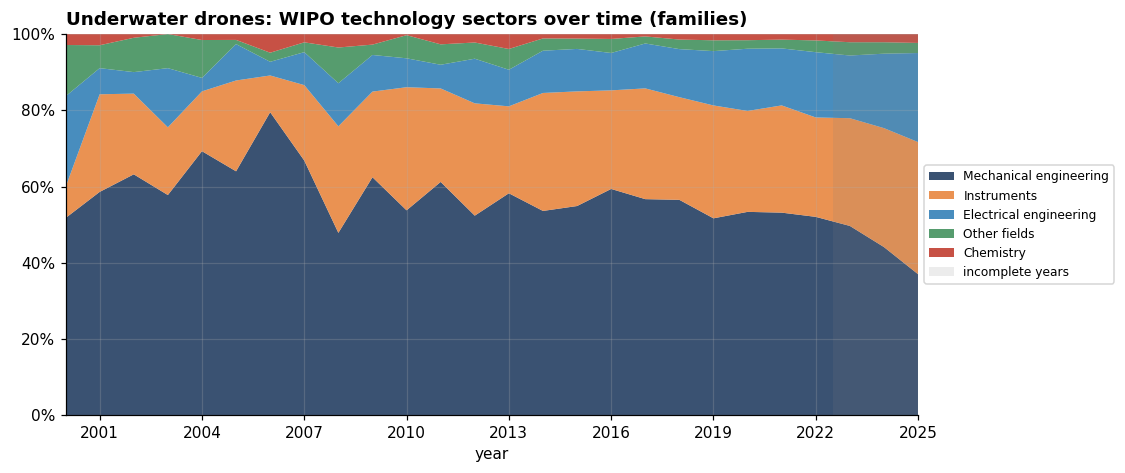

In [9]:
wf = read("family_wipo_fields.csv")
wf = wf[wf["docdb_family_id"].isin(fam_year_map.index)].copy()
wf["year"] = wf["docdb_family_id"].map(fam_year_map)
wipo = [wf.rename(columns={"weight": "n_frac"}).assign(level="family")]
names = wf[["techn_field_nr", "techn_field", "techn_sector"]].drop_duplicates("techn_field_nr")
if (IN / "application_wipo_fields.csv").exists():
    aw = read("application_wipo_fields.csv")
    aw = aw[aw["appln_id"].isin(app_year_map.index)].merge(names, on="techn_field_nr", how="left")
    aw["year"] = aw["appln_id"].map(app_year_map)
    aw["n_frac"] = aw["weight"] / aw.groupby("appln_id")["weight"].transform("sum")
    wipo.append(aw.assign(level="application"))
wipo = pd.concat(wipo, ignore_index=True)

wc = complete(wipo)


def by_level(df, index):
    t = df.pivot_table(index=index, columns="level", values="n_frac", aggfunc="sum", fill_value=0)
    return t[[l for l in LEVELS if l in t.columns]]                         # family first, then application


by_sector = share_table(by_level(wc, "techn_sector"))
by_field = by_level(wc, "techn_field")
top_fields = by_field["family"].nlargest(TOP_N).index
by_field = share_table(by_field.groupby(by_field.index.where(by_field.index.isin(top_fields), "Other")).sum())
save_table(by_sector.round(2), "tab_wipo_sectors")
save_table(by_field.round(2), "tab_wipo_fields")
display(by_sector.style.format("{:.1f}%"))
display(by_field.style.format("{:.1f}%"))

# WIPO mix in two complete windows: how is the technology mix shifting? (families, fractional)
def wipo_window(key):
    def sh(period):
        d = wc[(wc["level"] == "family") & wc["year"].between(*period)]
        t = d.groupby(key)["n_frac"].sum()
        return t / t.sum() * 100
    t = pd.DataFrame({f"all complete years": sh((Y0, LAST)), f"{PAST[0]}-{PAST[1]}": sh(PAST), f"{RECENT[0]}-{RECENT[1]}": sh(RECENT)}).fillna(0)
    t["change (pp)"] = t.iloc[:, 2] - t.iloc[:, 1]
    return t.sort_values("all complete years", ascending=False)


wipo_sec_win, wipo_fld_win = wipo_window("techn_sector"), wipo_window("techn_field").head(10)
save_table(wipo_sec_win.round(2), "tab_wipo_windows_sectors")
save_table(wipo_fld_win.round(2), "tab_wipo_windows_fields")
display(wipo_sec_win.style.format("{:.1f}"))
display(wipo_fld_win.style.format("{:.1f}"))

fig, ax = plt.subplots(figsize=(10, 4.5))
stack_100(ax, share_over_time(pool_other(wipo[wipo["level"] == "family"], "techn_sector", "n_frac", n=5), "techn_sector", "n_frac"),
          f"{SECTOR}: WIPO technology sectors over time (families)")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
save(fig, "fig_wipo_sectors")
plt.show()

### 5.3 Recombination: how many technologies does a family combine?
Number of distinct non-Y CPC subclasses per family: the raw material of the "novel CPC recombination" signal of Step 4.
Read the **trend, not the two end points**, and compare the whole sector with the international families: the mean can fall
simply because new, narrower filers (many university filings have one or two subclasses) enter the sector, not because
technologies stop combining.

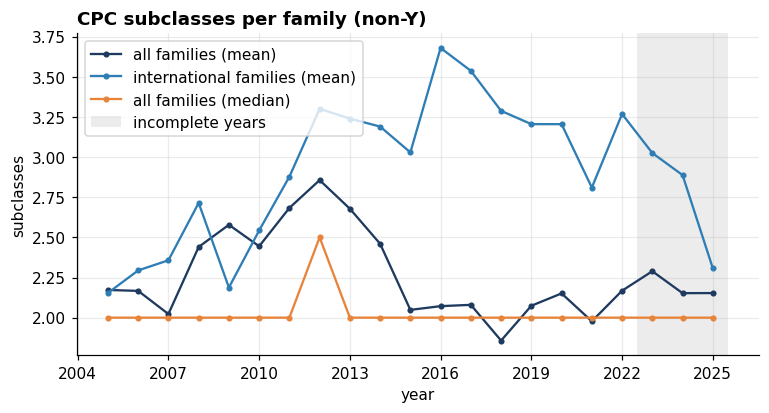

[2012, 2.86, 2.05]


In [10]:
rec_f = families[families["family_year"].between(2005, Y1)].dropna(subset=["n_subclasses"])
rec = rec_f.groupby("family_year")["n_subclasses"].agg(mean="mean", median="median")
rec["mean (international families)"] = rec_f[rec_f["docdb_family_id"].isin(SAMPLES["international"])].groupby("family_year")["n_subclasses"].mean()
rec["share with 3+ subclasses"] = rec_f.groupby("family_year")["n_subclasses"].apply(lambda s: (s >= 3).mean() * 100)
save_table(rec.round(2), "tab_recombination")
rec_c = rec["mean"].loc[:LAST]
KEY["mean CPC subclasses per family: peak year and value, last 5 complete years"] = [int(rec_c.idxmax()), round(float(rec_c.max()), 2), round(float(rec_c.iloc[-5:].mean()), 2)]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(rec.index, rec["mean"], marker="o", ms=3, color=NAVY, label="all families (mean)")
ax.plot(rec.index, rec["mean (international families)"], marker="o", ms=3, color=BLUE, label="international families (mean)")
ax.plot(rec.index, rec["median"], marker="o", ms=3, color=ORANGE, label="all families (median)")
shade(ax)
ax.set(title="CPC subclasses per family (non-Y)", xlabel="year", ylabel="subclasses")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend()
save(fig, "fig_recombination")
plt.show()
print(KEY["mean CPC subclasses per family: peak year and value, last 5 complete years"])

## 6. Geography

### 6.1 Filing offices: the IP5
Where protection is sought. **Application level**: each application is at one office, so shares sum to 100%.
**Family level**: a family usually has several offices, so the share of families "with an application at the office" does
**not** sum to 100%; the **first office** of the family (where the invention is first filed) does.

,% of families with an application at the office,"% of families, by first office",% of applications
CN,74.5%,73.1%,54.6%
US,12.1%,6.0%,10.3%
KR,7.9%,7.3%,5.7%
JP,3.2%,1.8%,2.5%
EP,5.7%,0.7%,4.6%
WO,9.6%,2.8%,6.6%
Other,11.2%,8.4%,15.6%
Total,-,100.0%,100.0%


share of applications at the IP5: 77.7%


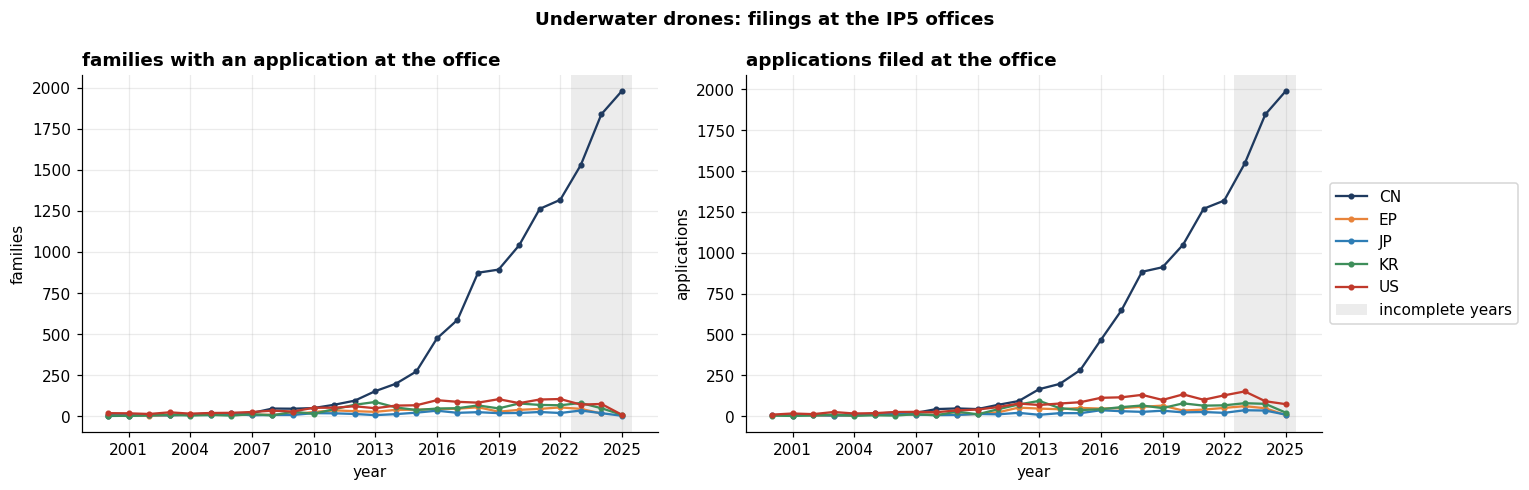

In [11]:
def pool_office(s):
    return s.where(s.isin(IP5 + ("WO",)), "Other")


fam_ok = families[families["family_year"] <= LAST]
fam_off_all = (applications[["docdb_family_id", "appln_auth"]].drop_duplicates()
               .assign(office=lambda d: pool_office(d["appln_auth"])))
fam_off_all = (fam_off_all[fam_off_all["docdb_family_id"].isin(families["docdb_family_id"])]
               .drop_duplicates(["docdb_family_id", "office"]))                              # all years: for the figure
fam_off = fam_off_all[fam_off_all["docdb_family_id"].isin(fam_ok["docdb_family_id"])]       # complete years: for the table
app_ok = apps[apps["appln_filing_year"] <= LAST].assign(office=lambda d: pool_office(d["appln_auth"]))

office_tab = pd.DataFrame({
    "% of families with an application at the office": fam_off.groupby("office").size() / len(fam_ok) * 100,
    "% of families, by first office": pool_office(fam_ok["first_office"].astype(str).str.strip()).value_counts(normalize=True) * 100,
    "% of applications": app_ok["office"].value_counts(normalize=True) * 100,
}).fillna(0)
office_tab = office_tab.loc[[o for o in IP5 + ("WO", "Other") if o in office_tab.index]]
office_tab.loc["Total"] = [np.nan, office_tab.iloc[:, 1].sum(), office_tab.iloc[:, 2].sum()]
save_table(office_tab.round(2), "tab_offices")
display(office_tab.style.format("{:.1f}%", na_rep="-"))
ip5_share = office_tab.loc[[o for o in IP5 if o in office_tab.index], "% of applications"].sum()
print(f"share of applications at the IP5: {ip5_share:.1f}%")
KEY["share of applications at the IP5 (%)"] = round(float(ip5_share), 1)
KEY["share of families first filed in China (%, complete years)"] = round(float((fam_ok["first_office"].astype(str).str.strip() == "CN").mean() * 100), 1)

fig, axes = two_panels(f"{SECTOR}: filings at the IP5 offices", sharex=True)
fam_lines = (fam_off_all.merge(families[["docdb_family_id", "family_year"]], on="docdb_family_id")
             .query("office in @IP5").groupby(["office", "family_year"]).size().unstack(0).reindex(years, fill_value=0))
app_lines = (apps.assign(office=lambda d: pool_office(d["appln_auth"])).query("office in @IP5")
             .groupby(["office", "appln_filing_year"]).size().unstack(0).reindex(years, fill_value=0))
for ax, level, data in zip(axes, LEVELS, (fam_lines, app_lines)):
    for office in data.columns:
        ax.plot(data.index, data[office], marker="o", ms=3, label=office)
    shade(ax)
    ax.set(title=("families with an application at the office" if level == "family" else "applications filed at the office"),
           xlabel="year", ylabel=UNIT[level])
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
save(fig, "fig_ip5_offices")
plt.show()

### 6.2 Origin: where is the invention first filed, and who protects it abroad?
The first office is a good proxy of the origin of the invention. The *international* share is the share of families filed at
more than one office: how often an invention is protected beyond its first market. Read the origin shares up to the last
complete year only: in the incomplete years the Chinese share is inflated because Chinese filings reach PATSTAT first.

,families,international,via_pct,mean_offices,share of the sector (%)
origin_group,,,,,
China,"7,304",2.5%,1.6%,1.03,73.1%
United States,596,33.9%,26.3%,1.97,6.0%
Korea & Japan,904,7.9%,5.3%,1.19,9.0%
EP / PCT first,346,74.0%,90.8%,3.33,3.5%
Europe & rest of world,841,47.0%,38.4%,2.74,8.4%


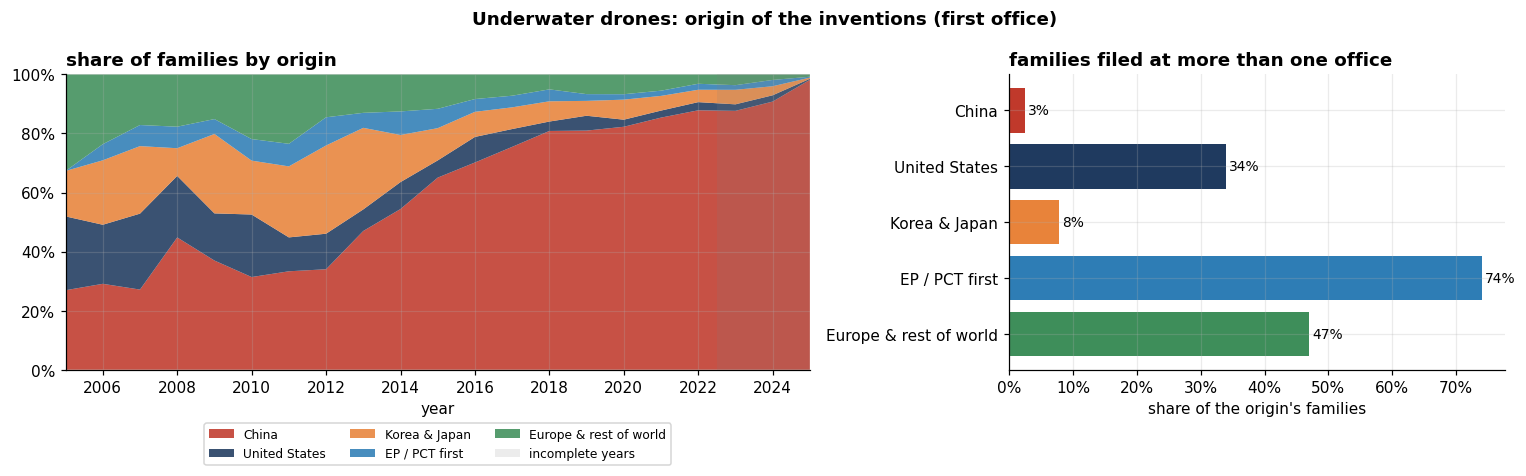

office,CN,US,EP,KR,JP,WO
origin_group,,,,,,
China,100%,1%,0%,0%,0%,2%
United States,7%,100%,20%,3%,5%,26%
Korea & Japan,1%,6%,2%,81%,20%,5%
EP / PCT first,14%,64%,53%,6%,16%,91%
Europe & rest of world,4%,29%,30%,3%,4%,38%


In [12]:
ORIGINS = ["China", "United States", "Korea & Japan", "EP / PCT first", "Europe & rest of world"]
ORIGIN_COLORS = [RED, NAVY, ORANGE, BLUE, GREEN]

orig_t = families[families["family_year"].between(2005, Y1)].groupby(["family_year", "origin_group"]).size().unstack(fill_value=0)
orig_t = orig_t.reindex(columns=ORIGINS, fill_value=0)
orig_t = orig_t.div(orig_t.sum(axis=1), axis=0) * 100

intl = (fam_ok.groupby("origin_group").agg(families=("docdb_family_id", "size"), international=("is_international", "mean"),
                                           via_pct=("via_pct", "mean"), mean_offices=("n_offices", "mean"))
        .reindex(ORIGINS).dropna(how="all"))
intl["share of the sector (%)"] = intl["families"] / intl["families"].sum() * 100
intl[["international", "via_pct"]] *= 100
save_table(intl.round(2), "tab_origin_international")
display(intl.style.format({"families": "{:,.0f}", "international": "{:.1f}%", "via_pct": "{:.1f}%", "mean_offices": "{:.2f}",
                           "share of the sector (%)": "{:.1f}%"}))

fig, axes = two_panels(f"{SECTOR}: origin of the inventions (first office)", gridspec_kw={"width_ratios": [3, 2]})
ax = axes[0]
ax.stackplot(orig_t.index, orig_t.T.values, labels=orig_t.columns, colors=ORIGIN_COLORS, alpha=0.88)
shade(ax)
ax.set(title="share of families by origin", xlabel="year", xlim=(2005, Y1), ylim=(0, 100))
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, fontsize=8)
ax = axes[1]
ax.barh(intl.index, intl["international"], color=ORIGIN_COLORS[:len(intl)])
for y, v in enumerate(intl["international"]):
    ax.text(v + 0.5, y, f"{v:.0f}%", va="center", fontsize=9)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.set(title="families filed at more than one office", xlabel="share of the origin's families")
plt.tight_layout()
save(fig, "fig_origin")
plt.show()

# where do the inventions of each origin go? (share of the origin's families with at least one application at each office)
DEST = [o for o in ("CN", "US", "EP", "KR", "JP", "WO")]
flows = fam_ok[["docdb_family_id", "origin_group", "offices"]].assign(office=lambda d: d["offices"].fillna("").astype(str).str.split()).explode("office")
od = flows[flows["office"].isin(DEST)].drop_duplicates(["docdb_family_id", "office"]).pivot_table(
    index="origin_group", columns="office", values="docdb_family_id", aggfunc="count", fill_value=0)
od = od.reindex(index=[o for o in ORIGINS if o in od.index], columns=DEST, fill_value=0)
od_share = od.div(fam_ok.groupby("origin_group").size().reindex(od.index), axis=0) * 100
save_table(od_share.round(1), "tab_origin_destination")
display(od_share.style.format("{:.0f}%").background_gradient(cmap="Blues", axis=None))

### 6.3 Applicant and inventor countries (fractional counts)
Applicant country = who owns the technology; inventor country = where the research is done.

**Caution.** In PATSTAT the country of a person is missing **not at random**: Chinese applicants and inventors almost never carry one.
`02_clean` therefore fills a missing country with the **filing office** (`country_source = filing_office`). This is a sound
proxy for the *owner's* country (compare the "all" column with the first-office share of 6.1), but it makes applicant and inventor
countries nearly identical *by construction*, so **the comparison cannot point to foreign R&D centres**.
The "stated only" columns are **not** a cleaner alternative: they keep only rows where a country is written, which are mostly
foreign, so China drops sharply. Read them as the profile of the *non-Chinese* part of the sector, not as a correction.
At application level the source is not available, so only "all" is shown. Family level splits a family among distinct
applicant *groups* (inventors: distinct names).

country source, share of rows:


,applicants,inventors
country_source,,
filing_office,0.663,0.818
person,0.337,0.181
unknown,0.000,0.001


,"family, applicants (all)","family, inventors (all)","family, applicants (stated only)","family, inventors (stated only)","application, applicants (all)","application, inventors (all)"
CN,74.1%,74.2%,11.4%,12.0%,57.3%,57.7%
KR,7.3%,7.4%,26.2%,19.4%,5.7%,6.0%
US,6.2%,5.9%,22.8%,25.5%,10.5%,10.0%
RU,2.4%,2.5%,8.6%,9.9%,1.8%,1.9%
JP,2.1%,2.1%,2.5%,2.4%,3.2%,2.9%
GB,1.3%,1.1%,4.4%,4.7%,3.6%,3.1%
DE,1.2%,1.1%,4.6%,5.0%,3.4%,3.0%
FR,1.2%,1.1%,4.2%,4.7%,2.9%,2.8%
Other,4.3%,4.6%,15.4%,16.4%,11.5%,12.5%
Total,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%


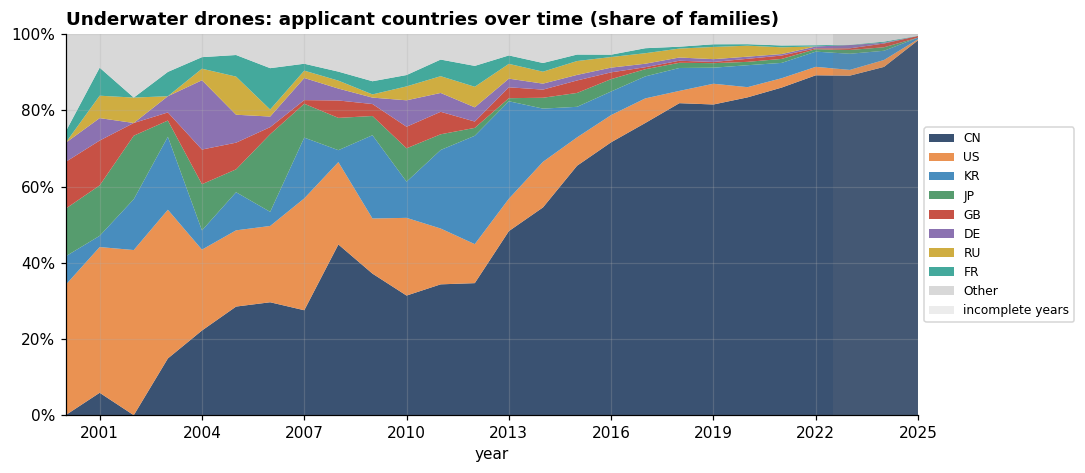

In [13]:
applicants_all = read("applicants.csv", cols={"docdb_family_id", "applicant", "applicant_type", "country", "country_source",
                                              "family_year", "weight"}, low_memory=False)
applicants_all = applicants_all[applicants_all["family_year"].between(Y0, Y1)].copy()      # all years: for the figure
inventors = read("inventors.csv", cols={"docdb_family_id", "inventor", "country", "country_source"}, low_memory=False)
inventors["family_year"] = inventors["docdb_family_id"].map(fam_year_map)
applicants = applicants_all[applicants_all["family_year"] <= LAST]                        # complete years: for the tables
inventors = inventors[inventors["family_year"].between(Y0, LAST)]

src = pd.DataFrame({"applicants": applicants["country_source"].value_counts(normalize=True),
                    "inventors": inventors["country_source"].value_counts(normalize=True)}).round(3)
print("country source, share of rows:")
display(src)
KEY["applicant rows with country taken from the filing office (%)"] = round(float((applicants["country_source"] == "filing_office").mean() * 100), 1)
KEY["inventor rows with country taken from the filing office (%)"] = round(float((inventors["country_source"] == "filing_office").mean() * 100), 1)


def country_shares(df, entity, only_stated=False):
    d = df[df["country"].notna()]
    if only_stated:
        d = d[d["country_source"] == "person"]
    d = d.drop_duplicates(["docdb_family_id", entity])
    w = 1 / d.groupby("docdb_family_id")[entity].transform("size")           # equal split among the known entities
    s = w.groupby(d["country"]).sum()
    return s / s.sum() * 100


def application_country_shares(name):
    path = IN / name
    if not path.exists():
        return pd.Series(dtype=float)
    d = pd.read_csv(path, usecols=lambda c: c in {"appln_id", "country", "weight"})
    d = d[d["appln_id"].map(app_year_map).between(Y0, LAST)]
    s = d.groupby("country")["weight"].sum()
    return s / s.sum() * 100


ctry = pd.DataFrame({
    "family, applicants (all)": country_shares(applicants, "applicant"),
    "family, inventors (all)": country_shares(inventors, "inventor"),
    "family, applicants (stated only)": country_shares(applicants, "applicant", only_stated=True),
    "family, inventors (stated only)": country_shares(inventors, "inventor", only_stated=True),
    "application, applicants (all)": application_country_shares("applicant_countries_by_application.csv"),
    "application, inventors (all)": application_country_shares("inventor_countries_by_application.csv"),
}).fillna(0)
top_c = ctry["family, applicants (all)"].nlargest(TOP_N).index
ctry = pd.concat([ctry.loc[top_c], ctry.drop(top_c).sum().to_frame("Other").T])
ctry.loc["Total"] = ctry.sum()
save_table(ctry.round(2), "tab_countries")
display(ctry.style.format("{:.1f}%"))

app_c = applicants_all[applicants_all["country"].notna()].drop_duplicates(["docdb_family_id", "applicant"]).copy()
app_c["w"] = 1 / app_c.groupby("docdb_family_id")["applicant"].transform("size")
app_c = app_c.rename(columns={"family_year": "year"})
fig, ax = plt.subplots(figsize=(10, 4.5))
stack_100(ax, share_over_time(pool_other(app_c, "country", "w"), "country", "w"), f"{SECTOR}: applicant countries over time (share of families)")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
save(fig, "fig_applicant_countries")
plt.show()

## 7. Patent-heavy or secrecy-reliant?
*Course link: types of IPR and appropriability (Cohen, Nelson & Walsh 2000; Arundel 2001).*

Patent data cannot measure secrecy directly: what is not patented is not in PATSTAT. We therefore triangulate: (a) **who patents**
(universities and state bodies patent for reasons other than appropriation); (b) **how much protection** each invention seeks
(grant, internationalisation, breadth); (c) **whether patents are fought over** (EPO opposition); (d) **whether the market
leaders patent here**. The argued paragraph (7.5) combines these numbers with the literature.

### 7.1 Who patents

type,firm,government / non-profit,hospital,individual,university,unknown
origin_group,,,,,,
All origins,31.5%,8.4%,0.0%,6.5%,48.0%,5.5%
China,24.1%,7.0%,0.0%,3.2%,61.3%,4.3%
United States,50.6%,12.5%,0.0%,24.0%,5.1%,7.8%
Korea & Japan,53.4%,20.8%,0.0%,9.3%,13.7%,2.7%
EP / PCT first,57.0%,5.6%,0.0%,15.0%,9.5%,12.8%
Europe & rest of world,48.4%,6.3%,0.0%,16.5%,14.9%,13.9%


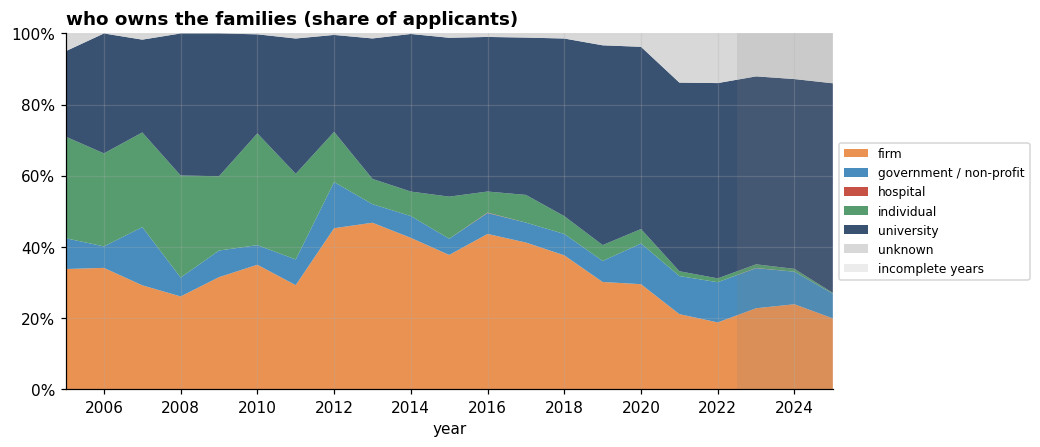

In [14]:
# one type per applicant group: the most frequent known type over its rows ('unknown' only if nothing else is known)
def group_type(s):
    known = s[s != "unknown"]
    return known.mode().iat[0] if len(known) else "unknown"


gtype = applicants_all.groupby("applicant")["applicant_type"].agg(group_type)
applicants_all["type"] = gtype.reindex(applicants_all["applicant"]).values
appl_c = applicants_all[applicants_all["family_year"] <= LAST].copy()            # complete years

types = appl_c.merge(families[["docdb_family_id", "origin_group"]], on="docdb_family_id")
tshare = types.pivot_table(index="origin_group", columns="type", values="weight", aggfunc="sum", fill_value=0)
tshare.loc["All origins"] = tshare.sum()
tshare = tshare.div(tshare.sum(axis=1), axis=0) * 100
tshare = tshare.reindex([o for o in ["All origins"] + ORIGINS if o in tshare.index])
save_table(tshare.round(1), "tab_owner_type_by_origin")
display(tshare.style.format("{:.1f}%"))
KEY["owner type, share of weighted applicant rows (%, complete years)"] = {k: round(float(v), 1) for k, v in tshare.loc["All origins"].items()}

ty = applicants_all[applicants_all["family_year"].between(2005, Y1)].pivot_table(index="family_year", columns="type", values="weight",
                                                                                aggfunc="sum", fill_value=0)
ty = ty.div(ty.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(9, 4.2))
type_colors = {"university": NAVY, "firm": ORANGE, "government / non-profit": BLUE, "individual": GREEN, "hospital": RED, "unknown": "lightgrey"}
ax.stackplot(ty.index, ty.T.values, labels=ty.columns, colors=[type_colors.get(c, GREY) for c in ty.columns], alpha=0.88)
shade(ax)
ax.set(title="who owns the families (share of applicants)", xlabel="year", xlim=(2005, Y1), ylim=(0, 100))
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
save(fig, "fig_owner_types")
plt.show()

### 7.2 How much protection does an invention seek?
By origin and by main owner type of the family. Granted share only on families old enough to have been examined; the
examination practice of each office differs, so compare within a column, not across offices. We deliberately leave out
renewal-fee events: INPADOC records them very differently by office (almost none for China), so the comparison would measure
data coverage, not behaviour.

In [15]:
fam_c = families[families["family_year"] <= LAST].copy()
fam_c["main_type"] = (appl_c.groupby("docdb_family_id")["type"].agg(lambda s: s.value_counts().index[0])
                      .reindex(fam_c["docdb_family_id"]).fillna("unknown").values)


def protection_profile(d):
    old = d[d["family_year"] <= GRANT_MAX_YEAR]
    return pd.Series({"families": len(d), f"granted (priority up to {GRANT_MAX_YEAR})": old["granted_any"].mean() * 100,
                      "international": d["is_international"].mean() * 100, "mean offices per family": d["n_offices"].mean(),
                      "with an EP application": d["has_ep"].mean() * 100})


prot = pd.concat({"origin": fam_c.groupby("origin_group").apply(protection_profile).reindex(ORIGINS).dropna(how="all"),
                  "main owner type": fam_c.groupby("main_type").apply(protection_profile)})
prot.loc[("sector", "all"), :] = protection_profile(fam_c)
save_table(prot.round(2), "tab_protection_profile")
display(prot.style.format({"families": "{:,.0f}", "mean offices per family": "{:.2f}"}, precision=1))
KEY["sector: international share (%, complete years)"] = round(float(prot.loc[("sector", "all"), "international"]), 1)
KEY[f"sector: granted share (%, priority up to {GRANT_MAX_YEAR})"] = round(float(prot.loc[("sector", "all"), f"granted (priority up to {GRANT_MAX_YEAR})"]), 1)

### 7.3 Are patents fought over? EPO opposition
Opposition is the formal challenge to a granted European patent. The sample is small (few sector families are granted at the EPO),
so we report the interval and compare it with the EPO average (about 5%, see the course material), **without reading a difference
unless the interval excludes it**.

In [16]:
legal_path = IN / "legal_events.csv.gz"
if legal_path.exists():
    ev = pd.read_csv(legal_path, usecols=lambda c: c in {"docdb_family_id", "event_auth", "ev_opposition"}, low_memory=False)
    ev["ev_opposition"] = to_bool(ev["ev_opposition"])
    ev["event_auth"] = ev["event_auth"].astype(str).str.strip()
    ep_granted = set(applications.loc[(applications["appln_auth"].astype(str).str.strip() == "EP") & applications["is_granted"],
                                      "docdb_family_id"]) & set(families["docdb_family_id"])
    ep_opposed = set(ev.loc[(ev["event_auth"] == "EP") & ev["ev_opposition"], "docdb_family_id"]) & ep_granted
    k, n = len(ep_opposed), len(ep_granted)
    lo, hi = wilson(k, n)
    print(f"EP-granted families: {n:,} | opposed at the EPO: {k:,} = {k / n:.1%} (95% CI {lo:.1%}-{hi:.1%}) | EPO average: about 5%")
    print("-> consistent with the average" if lo <= 0.05 <= hi else "-> the interval excludes 5%")
    KEY["EP opposition rate (%), 95% CI"] = [round(float(k / n * 100), 1), round(float(lo * 100), 1), round(float(hi * 100), 1), int(n)]
else:
    print("legal_events.csv.gz not found: skip (run 02_clean section 9)")

EP-granted families: 341 | opposed at the EPO: 12 = 3.5% (95% CI 2.0%-6.0%) | EPO average: about 5%
-> consistent with the average


**Other post-grant events** (licences, transfers of ownership, litigation, revocations, UPC opt-outs). INPADOC records them very
unevenly across offices (almost none for China), so read them as **lower bounds** and compare within the international
families. A transfer is a change of owner (assignment, merger, acquisition): a first sign of how often the technology changes
hands, relevant for the acquire-or-partner discussion of Step 6.

In [17]:
if legal_path.exists():
    ev_all = pd.read_csv(legal_path, usecols=lambda c: c in {"docdb_family_id", "event_auth", "event_descr",
                                                             "ev_opposition", "ev_licence", "ev_transfer",
                                                             "ev_litigation", "ev_revocation"}, low_memory=False)
    for c in ["ev_opposition", "ev_licence", "ev_transfer", "ev_litigation", "ev_revocation"]:
        ev_all[c] = to_bool(ev_all[c])
    d_ = ev_all["event_descr"].fillna("").astype(str).str.upper()
    ev_all["ev_upc_opt_out"] = d_.str.contains("OPT-OUT") & ~d_.str.contains("WITHDRAWAL OF OPT-OUT")
    ev_all["ev_transfer_non_US"] = ev_all["ev_transfer"] & ev_all["event_auth"].astype(str).str.strip().ne("US")
    ev_all["ev_litigation"] = ev_all["ev_litigation"] & ~d_.str.contains("OPT-OUT")
    ev_all["ev_revocation"] = ev_all["ev_revocation"] & ~d_.str.contains("INVALIDATED EUROPEAN PATENT|INVALIDATION OF EXTENSION")

    fam_ids, intl_ids = set(families["docdb_family_id"]), SAMPLES["international"]
    rows = []
    for f in ["ev_opposition", "ev_licence", "ev_transfer", "ev_transfer_non_US", "ev_litigation", "ev_revocation", "ev_upc_opt_out"]:
        ids = set(ev_all.loc[ev_all[f], "docdb_family_id"]) & fam_ids
        rows.append({"event": f, "families with the event": len(ids), "% of all families": len(ids) / len(fam_ids) * 100,
                     "% of international families": len(ids & intl_ids) / len(intl_ids) * 100})
    post_grant = pd.DataFrame(rows).set_index("event")
    print("check against the reference table of the group: litigation about 7 families, revocation about 23, UPC opt-out about 131")
    save_table(post_grant.round(2), "tab_post_grant_events")
    display(post_grant.style.format({"families with the event": "{:,.0f}", "% of all families": "{:.2f}%", "% of international families": "{:.2f}%"}))
    KEY["families with a transfer of ownership (% of international families)"] = round(float(post_grant.loc["ev_transfer", "% of international families"]), 1)
else:
    print("legal_events.csv.gz not found: skip")

check against the reference table of the group: litigation about 7 families, revocation about 23, UPC opt-out about 131


,families with the event,% of all families,% of international families
event,,,
ev_opposition,19,0.12%,1.20%
ev_licence,119,0.76%,3.31%
ev_transfer,"1,940",12.31%,64.26%
ev_transfer_non_US,"1,049",6.66%,19.86%
ev_litigation,7,0.04%,0.45%
ev_revocation,23,0.15%,1.50%
ev_upc_opt_out,131,0.83%,9.56%


### 7.4 Do the market leaders patent here?
Market leaders (list from the Step 0 literature note: **cite the source of the market shares in the deck**) against the
largest patentees of the sector. If the leaders are far down the patent ranking, patents measure research effort (often
public) more than market power, and secrecy or know-how protect the commercial leaders. **Before using this as evidence, check
the recall of the query on their flagship products** (for instance HUGIN, REMUS, Bluefin, Sabertooth): a miss would look
like "few patents".

In [18]:
MARKET_LEADERS = {   # label -> substrings of the harmonised applicant name (a leader can appear under several groups)
    "Kongsberg": ["KONGSBERG"], "Teledyne": ["TELEDYNE"], "Saab": ["SAAB"], "General Dynamics (Bluefin)": ["GENERAL DYNAMICS", "BLUEFIN ROBOTICS"],
    "L3Harris": ["L3HARRIS", "L3 HARRIS", "HARRIS CORP"], "Huntington Ingalls (Hydroid)": ["HUNTINGTON INGALLS", "HYDROID"],
    "Exail (ECA, iXblue)": ["EXAIL", "IXBLUE", "ECA GROUP"], "Oceaneering": ["OCEANEERING"],
    "TKMS / ThyssenKrupp": ["THYSSENKRUPP", "THYSSEN KRUPP", "ATLAS ELEKTRONIK", "TKMS"], "Naval Group": ["NAVAL GROUP", "DCNS"],
    "BAE Systems": ["BAE SYSTEMS"], "Hanwha": ["HANWHA"], "Fincantieri (client group)": ["FINCANTIERI"]}
grp = (applicants_all.drop_duplicates(["docdb_family_id", "applicant"]).groupby("applicant")
       .agg(families=("docdb_family_id", "nunique"), type=("type", "first"),
            country=("country", lambda s: s.dropna().mode().iat[0] if s.notna().any() else "")))
grp = grp.sort_values("families", ascending=False)
grp["rank (all applicants)"] = np.arange(1, len(grp) + 1)
firms = grp[grp["type"].isin(["firm", "unknown"])].copy()
firms["rank (firms)"] = np.arange(1, len(firms) + 1)
rows = []
for label, keys in MARKET_LEADERS.items():
    hit = grp[grp.index.map(lambda n: any(k in n for k in keys))]
    if len(hit):
        in_firms = firms.index.intersection(hit.index)
        rows.append({"market leader": label, "applicant groups matched": "; ".join(hit.index[:3]), "families (sum of groups)": int(hit["families"].sum()),
                     "rank (all applicants)": int(hit["rank (all applicants)"].min()),
                     "rank (firms)": int(firms.loc[in_firms, "rank (firms)"].min()) if len(in_firms) else np.nan})
    else:
        rows.append({"market leader": label, "applicant groups matched": "(not found)", "families (sum of groups)": 0,
                     "rank (all applicants)": np.nan, "rank (firms)": np.nan})
leaders = pd.DataFrame(rows).set_index("market leader")
save_table(leaders, "tab_market_vs_patent_leaders")
display(leaders)
top_pat = grp.head(10)[["families", "type", "country"]]
save_table(top_pat, "tab_top10_patentees")
display(top_pat)
KEY["top-10 patentees: universities / state bodies (count)"] = int(top_pat["type"].isin(["university", "government / non-profit"]).sum())

,applicant groups matched,families (sum of groups),rank (all applicants),rank (firms)
market leader,,,,
Kongsberg,KONGSBERG,10,225,85
Teledyne,TELEDYNE,9,243,100
Saab,SAAB,13,181,65
General Dynamics (Bluefin),GENERAL DYNAMICS (BLUEFIN),4,611,298
L3Harris,L3HARRIS,6,399,181
Huntington Ingalls (Hydroid),HUNTINGTON INGALLS (HYDROID),2,1410,764
"Exail (ECA, iXblue)",EXAIL (ECA); IXBLUE,21,162,57
Oceaneering,OCEANEERING,45,47,9
TKMS / ThyssenKrupp,TKMS (ATLAS ELEKTRONIK); THYSSEN KRUPP,136,17,4


,families,type,country
applicant,,,
HARBIN ENGINEERING UNIVERSITY,1226,university,CN
CHINESE ACADEMY OF SCIENCES,804,university,CN
CHINA STATE SHIPBUILDING (CSSC),697,firm,CN
NORTHWESTERN POLYTECHNICAL UNIVERSITY,575,university,CN
ZHEJIANG UNIVERSITY,381,university,CN
JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY,223,university,CN
TIANJIN UNIVERSITY,199,university,CN
DALIAN MARITIME UNIVERSITY,165,university,CN
HOHAI UNIVERSITY,158,university,CN


### 7.5 The argued paragraph (draft: fill in the brackets, add the sector literature)

> *Patents appear to measure research effort in this sector more than commercial power.* [x]% of the families are owned by
> universities and state bodies, which patent to publish and to obtain funding rather than to protect a product; the
> large commercial players (Kongsberg, Teledyne, Saab, ...) hold [few] families and rank [far down] the patentee list. The
> inventions that are protected abroad are a small minority ([y]% international; [z]% for Chinese origin), and the EPO
> opposition rate is [o]% (95% CI [a]-[b]%), [in line with / different from] the usual 5%: patents are rarely a
> battlefield. This fits the evidence that, in capital-goods and defence markets, firms rely on secrecy, lead time, complementary assets
> and public procurement relationships more than on patents (Cohen, Nelson & Walsh, 2000; Arundel, 2001) [add 2-3
> sources on defence/offshore robotics and on secrecy orders]. The patent data therefore describe the technology frontier and
> the public R&D system well, and the commercial incumbents less well: this is why Step 3 scores *firms* only on what they do patent.

Numbers for the brackets:

In [19]:
own = KEY["owner type, share of weighted applicant rows (%, complete years)"]
print(f"[x]  universities {own.get('university', 0):.0f}% + state/non-profit {own.get('government / non-profit', 0):.0f}% "
      f"+ individuals {own.get('individual', 0):.0f}% | firms {own.get('firm', 0):.0f}% | unknown {own.get('unknown', 0):.0f}%")
print(f"[y]  international share of the sector: {KEY['sector: international share (%, complete years)']:.1f}%")
print("[z]  international share, China origin:", round(float(intl.loc["China", "international"]), 1) if "China" in intl.index else "n/a")
print("[o]  EP opposition:", KEY.get("EP opposition rate (%), 95% CI", "n/a"))
print("[few / far down]  see the table in 7.4")

[x]  universities 48% + state/non-profit 8% + individuals 6% | firms 32% | unknown 6%
[y]  international share of the sector: 11.1%
[z]  international share, China origin: 2.5
[o]  EP opposition: [3.5, 2.0, 6.0, 341]
[few / far down]  see the table in 7.4


## 8. Robustness on the three samples and key numbers
The headline results on the whole sector, without the weakest block of the query, and on the international families. If a
number moves a lot, the conclusion depends on the sample and must be said in the deck.

In [20]:
def headline(name, ids):
    fc_ = families[families["docdb_family_id"].isin(ids) & (families["family_year"] <= LAST)]
    y = fc_.groupby("family_year").size().reindex(range(Y0, LAST + 1), fill_value=0)
    a = appl_c[appl_c["docdb_family_id"].isin(ids)]
    t = a.groupby("type")["weight"].sum() / a["weight"].sum() * 100
    top = a.drop_duplicates(["docdb_family_id", "applicant"]).groupby("applicant")["docdb_family_id"].nunique().sort_values(ascending=False)
    cs = complete(fsw[fsw["docdb_family_id"].isin(ids)]).groupby("subclass")["weight_tech"].sum()
    cs = (cs / cs.sum() * 100).sort_values(ascending=False)
    return pd.Series({
        f"families, {Y0}-{LAST}": len(fc_),
        f"CAGR {BASE_YEAR}-{LAST} (%)": cagr(y, BASE_YEAR, LAST),
        "S-curve inflection year": life.loc[name, "t0 (inflection year)"] if name in life.index else np.nan,
        "first filed in China (%)": (fc_["first_office"].astype(str).str.strip() == "CN").mean() * 100,
        "international (%)": fc_["is_international"].mean() * 100,
        "owners: university (%)": t.get("university", 0), "owners: firm (%)": t.get("firm", 0),
        "top applicant": top.index[0] if len(top) else "", "top-1 CPC subclass": cs.index[0] if len(cs) else "",
        "top-1 CPC subclass share (%)": cs.iloc[0] if len(cs) else np.nan})


robust = pd.DataFrame({name: headline(name, ids) for name, ids in SAMPLES.items()})
save_table(robust, "tab_robustness_samples")
display(robust.style.format(lambda v: f"{v:,.1f}" if isinstance(v, (float, np.floating)) else v, na_rep="-"))

fc_all = families[families["family_year"] <= LAST]
KEY.update({"sector families (all years)": len(families), f"families in incomplete years ({LAST + 1}-{Y1})": int((families["family_year"] > LAST).sum()),
            "applications (window)": len(apps), "applications per family (mean)": round(len(apps) / len(families), 2),
            "share via PCT (%, complete years)": round(float(fc_all["via_pct"].mean() * 100), 1)})


def clean_json(o):
    if isinstance(o, dict):
        return {str(k): clean_json(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean_json(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return None if np.isnan(o) else float(o)
    return o


(OUT / "key_numbers.json").write_text(json.dumps(clean_json(KEY), indent=2, ensure_ascii=False))
display(pd.Series(clean_json(KEY), name="value").to_frame())

,all,without block-6-only,international
"families, 2000-2022",9991,7776,1107
CAGR 2012-2022 (%),19.9,20.0,8.4
S-curve inflection year,"2,024.3","2,023.5","2,021.1"
first filed in China (%),73.1,71.9,16.5
international (%),11.1,12.6,100.0
owners: university (%),48.0,48.6,15.1
owners: firm (%),31.5,30.8,56.6
top applicant,HARBIN ENGINEERING UNIVERSITY,HARBIN ENGINEERING UNIVERSITY,TKMS (ATLAS ELEKTRONIK)
top-1 CPC subclass,B63G,B63G,B63G
top-1 CPC subclass share (%),17.0,19.5,25.5


,value
sector CAGR 2012-2022 (%),19.9
all patents CAGR 2012-2022 (%),5.5
"sector share of all patents, 2012 (per mille)",0.172
"sector share of all patents, 2022 (per mille)",0.619
neighbour B63 CAGR 2012-2022 (%),7.0
"share of method/process titles, first 5 / last 5 complete years (%)","[22.4, 44.1]"
"share of control/navigation titles, first 5 / last 5 complete years (%)","[14.4, 24.5]"
"top-3 CPC subclasses (families, % of weight)","{'B63G': 17.0, 'B63C': 14.9, 'G05D': 8.2}"
"mean CPC subclasses per family: peak year and value, last 5 complete years","[2012, 2.86, 2.05]"
share of applications at the IP5 (%),77.7


In [21]:
# consistency checks between the input files and the configuration: every line must be True
checks = {
    "one row per family": families["docdb_family_id"].is_unique,
    "truncated flag matches LAST_COMPLETE_YEAR": bool((families["family_year"] > LAST).eq(families["is_truncated"]).all()),
    "every application belongs to a listed family": bool(applications["docdb_family_id"].isin(families["docdb_family_id"]).all()),
    "CPC shares sum to 100": bool(np.allclose(cpc_tab.loc["Total", list(LEVELS)], 100)),
    "WIPO sector shares sum to 100": bool(np.allclose(by_sector.loc["Total"], 100)),
    "application-level office shares sum to 100": bool(np.isclose(office_tab.loc["Total", "% of applications"], 100)),
    "first-office shares sum to 100": bool(np.isclose(office_tab.loc["Total", "% of families, by first office"], 100)),
    "country shares sum to 100": bool(np.allclose(ctry.loc["Total"], 100)),
    "sample sizes are nested": SAMPLES["without block-6-only"] <= SAMPLES["all"] and SAMPLES["international"] <= SAMPLES["all"],
}
display(pd.Series(checks, name="ok").to_frame())
assert all(checks.values()), "a check failed: see the table above"
print("saved figures:", ", ".join(sorted(p.name for p in FIG_DIR.glob("*.png"))))

,ok
one row per family,True
truncated flag matches LAST_COMPLETE_YEAR,True
every application belongs to a listed family,True
CPC shares sum to 100,True
WIPO sector shares sum to 100,True
application-level office shares sum to 100,True
first-office shares sum to 100,True
country shares sum to 100,True
sample sizes are nested,True


saved figures: fig_applicant_countries.png, fig_cpc_absolute.png, fig_cpc_mix.png, fig_dating.png, fig_deck_volume_growth.png, fig_ip5_offices.png, fig_origin.png, fig_owner_types.png, fig_process_proxy.png, fig_recombination.png, fig_s_curve.png, fig_share_of_all.png, fig_volume.png, fig_volume_samples.png, fig_wipo_sectors.png


**For the main deck (at most 10 figures and tables for the whole deck, Steps 1-6: keep Step 1 to about 4).**
1. `fig_deck_volume_growth`: size and growth, truncated years shaded (answers "how big, growing?").
2. `fig_cpc_mix` + `tab_cpc_subclasses`: the mix over time and the table with the official definitions (answers "which technologies?").
3. `fig_origin` or `tab_offices`: geography (answers "where?").
4. The paragraph of 7.5, with one small table (`tab_market_vs_patent_leaders` or `tab_owner_type_by_origin`).

Everything else (`fig_volume`, `fig_dating`, the samples, the S-curve, WIPO, recombination, the country table) goes in the technical appendix.

## 9. To state in the technical appendix

- *Unit*: DOCDB family (one invention = one count), dated by its earliest priority year; the application level counts every filing at its office by filing year. Every figure and table says which level it shows.
- *Truncation*: the last 3 years (`LAST_COMPLETE_YEAR` + 1 to 2025) are incomplete (18-month publication lag, plus the delay in PATSTAT): shaded in every figure and excluded from every growth figure and share. The sector, dominated by Chinese filings, is truncated less than the benchmarks, so its share of all patents in those years is inflated. The *international* flag needs the second filing: its last 2 years are certainly incomplete.
- *Fractional counting*: CPC subclasses, WIPO fields, applicants and inventors split a family equally, so each family sums to 1 (countries: only entities with a known country).
- *Benchmarks*: all patents and CPC B63, same rules (patents of invention only, dummy applications excluded).
- *Y tagging section* left out of the CPC mix (`weight_tech`).
- *Country*: filled with the filing office when missing; applicant and inventor countries are therefore not independent (6.3); "stated only" columns use only declared countries.
- *Applicant type*: the most frequent known type of each harmonised group; "unknown" only if no row says otherwise.
- *Sector*: Step 0 definition (rule blocks 1-6, exclusions, hand-label corrections); precision and recall with their intervals are in the Step 0 appendix. Block 6 is kept (group decision) and tested in the *without block-6-only* sample.
- *S-curve*: logistic fit on cumulative complete years; fit quality on annual counts; `K` is not interpreted.
- *Patents vs secrecy*: triangulation (owner types, protection sought, opposition, market leaders) plus the literature (Cohen, Nelson & Walsh 2000; Arundel 2001; defence and offshore robotics sources to add); not directly measurable from patent data.

---
---
# PART B · STEP 2 — Competitive landscape


# Step 2 · Competitive landscape: Underwater drones (client: Fincantieri)

**PW Innovation Management · Team 10 · client: Fincantieri** · notebook `04_step2_competitive_landscape`

This standalone notebook answers all the questions of **Step 2 (competitive landscape)** of the presentation deck and writes every figure and table for the deck and the technical appendix. It reads only the clean tables written by `02_clean.ipynb` (`outputs/<env>/step1/`) and needs **no PATSTAT query** (two optional cells, switched off by default with `RUN_PATSTAT = False`, can be run on TIP).

| Deck question (kick-off, Step 2) | Section | Course & literature link |
|---|---|---|
| How concentrated is the field, and is it consolidating? | 2.1 Concentration (6 metrics) · 2.1.1 Consolidation over time · 2.1.2 By country & Lorenz curves | Tutorial 1 nb 11 §3–5.1 (Liston-Heyes & Pilkington, 2004) |
| Who are the incumbents, the new entrants and the start-ups? Which players to score in Step 3? | 2.2 Top players (all, firms, non-CN firms, universities, start-up candidates) · 2.2.1 Shortlist for Step 3 · 2.2.2 Incumbents vs entrants summary | Tutorial 1 nb 11 §5.0–5.2; Tutorial 4 (volume gate) |
| How many players enter and exit each year, and who persists? | 2.3 Entry, exit & disappearance rate · 2.3.1 Persistence by applicant type | Tutorial 1 nb 11 §5.2; Patel & Pavitt (1997) |
| Which subfields are growing fastest, and where are they in the maturity matrix? | 2.4.1 CPC main groups & WIPO (2024) Maturity Matrix + fine CPC subgroups (`tab_fastest_growers`) · 2.4.2 Topics from abstracts (TF-IDF + NMF) | Tutorial 1 nb 11 §5.3; IM_Theory_3 (WIPO 2024 SDG report); Tutorial 2 nb 21 §9 |
| Who leads where, and who works with whom? | 2.5 Specialisation (RTA of players and countries) · 2.6 Co-applicant network & brokers | Patel & Pavitt (1997) RTA; IM_Theory_2 & 4 (collaboration, brokers) |
| Where does the client stand, and who leads in its subfields? | 2.7 Client portfolio (`FINCANTIERI`) & top non-university owners in target subfields | Teece (1986) complementary assets; sets up Step 6 |
| Which Political, Economic, Social, Technological forces shape the sector? | 2.8 Mandatory PEST table paired with patent signals from our data | Tutorial 1 nb 11 §5.4 |
| Do conclusions hold across samples? | 3 Robustness summary (`all`, `without block-6-only`, `international`) · 4 Consistency checks | Dang & Motohashi (2015); WIPO (2024) |

**Counting rules**: unit = DOCDB family; year = earliest priority year of the family; years after `LAST_COMPLETE_YEAR` (2022) are incomplete (18-month publication lag), shaded in grey and excluded from growth/disappearance figures; applicants are the harmonised corporate groups of `02_clean`.

## 1 · Setup and data

In [22]:
import json
import re
import shutil
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import MaxNLocator, PercentFormatter
from scipy import stats
from scipy.optimize import curve_fit

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)


def find_config():
    """Folder with config.py: this folder, its parent, or the step_0 folder next to it."""
    here = Path.cwd().resolve()
    for d in (here, here.parent, here.parent / "step_0_HL", here / "step_0_HL"):
        if (d / "config.py").exists():
            return d
    raise FileNotFoundError("config.py not found: run from the folder with config.py or from a folder next to step_0_HL")


BASE = find_config()
sys.path.insert(0, str(BASE))
import config as C                         # the same configuration as Step 0: env, years, sector name, client aliases

IN = BASE / C.OUT_STEP1                    # outputs/<env>/step1: the clean tables of 02_clean
OUT = Path("outputs") / C.ENV.lower() / "step2_Landscape"
FIG, TAB = OUT / "figures", OUT / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- analysis settings (design choices: justify them)
SECTOR = C.SECTOR_NAME
LAST = C.LAST_COMPLETE_YEAR                # 2022: last complete priority year
YEAR_MIN, YEAR_MAX = C.YEAR_MIN, C.YEAR_MAX
SPLIT_YEAR = 2015                          # incumbents: first family in the sector before 2015; entrants: from 2015
WINDOW = 3                                 # years per window when following concentration over time
PAST = (LAST - 9, LAST - 5)                # 2013-2017 (5 complete years)
RECENT = (LAST - 4, LAST)                  # 2018-2022 (last 5 complete years)
TOP_N = 15
MIN_FAMILIES_SCORE = 10                    # gate for the Step 3 shortlist (Clarivate-style volume gate, Tutorial 4)
CLIENT = "FINCANTIERI"
RUN_PATSTAT = False                        # True only on TIP: optional cells that query PATSTAT / BERTopic

NAVY, ORANGE, BLUE, GREY, MID, LIGHT, GREEN, RED = (
    "#002B49", "#EF7B00", "#4F7CA3", "#4A5A6A", "#8A9AAB", "#D9E1E8", "#7A9A3A", "#A23B72"
)
PALETTE = [NAVY, ORANGE, BLUE, GREEN, RED, MID, "#C9A227", "#5B8E7D", "#B5651D", "#6C5B7B"]
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.alpha": 0.25,
    "figure.dpi": 110, "savefig.dpi": 200, "axes.prop_cycle": plt.cycler(color=PALETTE)
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)


def shade(ax, last=LAST, right=YEAR_MAX):
    """Grey band on the incomplete (truncated) years."""
    ax.axvspan(last + 0.5, right + 0.5, color="grey", alpha=0.15, lw=0, label="incomplete years")


def save(fig, name):
    """Save a figure in outputs/<env>/step2/figures/."""
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")


def save_table(df, name, **kw):
    """Save a CSV table in both outputs/<env>/step2/tables/ and outputs/<env>/step2/."""
    df.to_csv(TAB / f"{name}.csv", **kw)
    df.to_csv(OUT / f"{name}.csv", **kw)


def cagr(first, last, years):
    return (last / first) ** (1 / years) - 1 if first > 0 and years > 0 else np.nan


def pct(x, d=1):
    return f"{100 * x:.{d}f}%"


def short(df, n=45):
    """Shorter index labels for display (some PATSTAT names are 200 characters long)."""
    return df.rename(index=lambda s: s if not isinstance(s, str) or len(s) <= n else s[:n - 1] + "…")


def share_by(df, key, weight="weight_tech", top=12):
    d = df.dropna(subset=[weight])
    s = d.groupby(key)[weight].sum().sort_values(ascending=False)
    s = s / s.sum()
    out = s.head(top).copy()
    out.loc["Other"] = s.iloc[top:].sum()
    return out


KEY = {}     # headline numbers, saved at the end in key_numbers.json
print(f"{SECTOR} · env {C.ENV} · reading {IN} · writing {OUT} · complete years up to {LAST}")

Underwater drones · env PROD · reading /home/jovyan/PW-InnovationManagement/outputs/prod/step1 · writing outputs/prod/step2_Landscape · complete years up to 2022


### 1.1 Data and the three robustness samples

All tables come from `02_clean`. `applicants.csv` carries the harmonised group name (`applicant`), the type and the country of each applicant of each family, and the fractional weights (each family sums to 1). The **type of an applicant** is taken from `applicants_profile.csv` (or the most frequent known type across its rows), because `psn_sector` can differ between spellings of the same group.

Every headline metric in Step 2 is tested across three samples:
- **all**: all sector families;
- **without block-6-only**: excluding families retrieved only by Block 6 (precision ~48%);
- **international**: families filed at more than one office or via PCT (controls for domestic subsidy-driven filings).

In [23]:
fam = pd.read_csv(IN / "families.csv", low_memory=False)
apps = pd.read_csv(IN / "applications.csv", low_memory=False)
appl = pd.read_csv(IN / "applicants.csv", low_memory=False)
prof = pd.read_csv(IN / "applicants_profile.csv", low_memory=False) if (IN / "applicants_profile.csv").exists() else pd.DataFrame()
inv = pd.read_csv(IN / "inventors.csv", low_memory=False)
fcpc = pd.read_csv(IN / "family_cpc.csv", low_memory=False)
fsub = pd.read_csv(IN / "family_subclass.csv", low_memory=False)
fwipo = pd.read_csv(IN / "family_wipo_fields.csv", low_memory=False)
fwd = pd.read_csv(IN / "citations_forward.csv", low_memory=False)

for col in ["is_truncated", "granted_any", "via_pct", "is_international", "has_ep", "active_proxy",
            "fwd_window_complete", "has_en_abstract"]:
    if col in fam.columns:
        fam[col] = fam[col].astype(str).str.lower().eq("true")

# The client group (Fincantieri, with the former WASS / Whitehead business and Leonardo's underwater families) is built once,
# in 02_clean, by config.GROUP_ALIASES: here we only check that it is there and mark it as a firm.
if CLIENT not in set(appl["applicant"]):
    print(f"WARNING: {CLIENT} not found among the applicants: check GROUP_ALIASES in config.py and rerun 02_clean")
appl.loc[appl["applicant"] == CLIENT, "applicant_type"] = "firm"

# One consistent type per applicant group
def resolve_group_type(s):
    known = s[s != "unknown"]
    return known.mode().iat[0] if len(known) else "unknown"

if not prof.empty and "applicant" in prof.columns and "type" in prof.columns:
    type_map = prof.set_index("applicant")["type"].to_dict()
else:
    type_map = {}
fallback_map = appl.groupby("applicant")["applicant_type"].agg(resolve_group_type).to_dict()
appl["type"] = appl["applicant"].map(lambda a: "firm" if a == CLIENT else type_map.get(a, fallback_map.get(a, "unknown")))
appl["year"] = appl["family_year"]

# Subclass table merged with family metadata (weight_tech excludes Y climate/tagging codes, weight includes all)
if "weight_tech" not in fsub.columns:
    non_y = fsub[~fsub["subclass"].astype(str).str.startswith("Y")].copy()
    non_y["weight_tech"] = 1 / non_y.groupby("docdb_family_id")["subclass"].transform("size")
    fsub = fsub.merge(non_y[["docdb_family_id", "subclass", "weight_tech"]], on=["docdb_family_id", "subclass"], how="left")
sub = fsub.merge(fam[["docdb_family_id", "family_year", "is_international"]], on="docdb_family_id")
sub["b6_only"] = sub["docdb_family_id"].map(fam.set_index("docdb_family_id")["block_combo"].astype(str).eq("b6"))
sub_c = sub[sub["family_year"] <= LAST]

# The three robustness samples
fam["b6_only"] = fam["block_combo"].astype(str).eq("b6")
SAMPLES = {
    "all": set(fam["docdb_family_id"]),
    "without block-6-only": set(fam.loc[~fam["b6_only"], "docdb_family_id"]),
    "international": set(fam.loc[fam["is_international"], "docdb_family_id"]),
}

# Pre-populate baseline sector indicators used in Section 2.8 (PEST) and Section 3 (Robustness)
fam_c = fam[fam["family_year"] <= LAST]
KEY["families_total"] = int(len(fam))
KEY["families_complete_years"] = int(len(fam_c))
KEY["share_first_filed_CN"] = float((fam_c["first_office"].astype(str).str.strip() == "CN").mean())
KEY["share_international"] = float(fam_c["is_international"].mean())
appl_c_weights = appl[appl["family_year"] <= LAST].groupby("type")["weight"].sum()
appl_c_weights = appl_c_weights / appl_c_weights.sum()
KEY["share_university"] = float(appl_c_weights.get("university", 0.0))
KEY["share_firm"] = float(appl_c_weights.get("firm", 0.0))

print(f"{len(fam):,} families, {len(apps):,} applications, {appl['applicant'].nunique():,} applicant groups, "
      f"{len(fcpc):,} family-CPC rows")
display(pd.DataFrame({"families": {k: len(v) for k, v in SAMPLES.items()},
                      "share of all": {k: pct(len(v) / len(fam)) for k, v in SAMPLES.items()}}))

15,755 families, 20,430 applications, 5,175 applicant groups, 58,717 family-CPC rows


,families,share of all
all,15755,100.0%
without block-6-only,11968,76.0%
international,1329,8.4%


# STEP 2 · Competitive landscape

## 2.1 Concentration: how concentrated is the field, and is it consolidating?

**Unit.** The applicant is the harmonised group of `02_clean` (three traceable layers, `applicants_audit.csv`): without harmonisation a large firm splits into many small ones and every concentration measure is underestimated (Tutorial 1 nb 11 §2). **Counts.** *Inventive* concentration: the share of families held by each applicant (full counting: a co-owned family counts for each owner, as in Tutorial 1, plus a check with fractional counting).

We compute both the summary table of Tutorial 1 (`tab_field_concentration.csv`: `firms`, `patents`, `CR4`, `HH`, `1/HH`) and the full six-measure set of **Liston-Heyes & Pilkington (2004)** (Tutorial 1 nb 11 §3: `CR4`, `CR8`, `HH`, `1/HH`, coefficient of variation `CV`, `Gini`, `Lotka L` slope and p-value).

In [24]:
def concentration_ratio(x, k=4):
    x = np.sort(np.asarray(x, dtype=float))[::-1]
    return float(x[:k].sum() / x.sum()) if x.sum() > 0 else np.nan


def herfindahl(x):
    s = np.asarray(x, dtype=float) / np.sum(x)
    return float(np.sum(s ** 2)) if np.sum(x) > 0 else np.nan


def lorenz_curve(x):
    x = np.sort(np.asarray(x, dtype=float))
    return np.arange(0, len(x) + 1) / len(x), np.concatenate([[0], np.cumsum(x) / x.sum()])


def gini(x):
    f, p = lorenz_curve(x)
    return float((0.5 - np.sum(np.diff(f) * (p[1:] + p[:-1]) / 2)) / 0.5)


def lotka(x):
    f = pd.Series(x).value_counts().sort_index()
    if len(f) < 3:
        return np.nan, np.nan
    fit = stats.linregress(np.log(f.index.astype(float)), np.log(f.values.astype(float)))
    return float(fit.slope), float(fit.pvalue)


def field_measures(patents_per_firm):
    """Tutorial 1 summary measures (from LANDSCAPE.py)."""
    hh = herfindahl(patents_per_firm)
    return {
        "firms (applicants)": len(patents_per_firm),
        "patents (sum over firms)": int(np.sum(patents_per_firm)),
        "CR4 (%)": concentration_ratio(patents_per_firm, 4) * 100,
        "HH": hh,
        "1/HH": 1 / hh if hh > 0 else np.nan,
    }


def six_measures(x):
    """Full Liston-Heyes & Pilkington (2004) concentration metrics."""
    x = np.asarray(x, dtype=float)
    L, p = lotka(np.round(x).astype(int)) if np.allclose(x, np.round(x)) else (np.nan, np.nan)
    hh = herfindahl(x)
    return {
        "applicants": len(x), "families (sum)": x.sum(),
        "CR4": concentration_ratio(x, 4), "CR8": concentration_ratio(x, 8),
        "HH": hh, "1/HH": 1 / hh if hh > 0 else np.nan,
        "CV": x.std(ddof=1) / x.mean(), "Gini": gini(x),
        "Lotka L": L, "Lotka p": p,
    }


links = appl[["docdb_family_id", "applicant", "type", "country", "weight", "family_year"]].drop_duplicates(["docdb_family_id", "applicant"])
links_c = links[links["family_year"] <= LAST]

# Tutorial 1 compact table (tab_field_concentration.csv)
fam_per_appl = links_c.groupby("applicant")["docdb_family_id"].nunique()
tab_field_conc = pd.Series(field_measures(fam_per_appl.to_numpy()), name=SECTOR).round(3).to_frame()
save_table(tab_field_conc, "tab_field_concentration")

# Full 6-measure comparison across samples and counting rules (concentration.csv)
conc = {}
for name, ids in SAMPLES.items():
    d = links_c[links_c["docdb_family_id"].isin(ids)]
    conc[name] = six_measures(d.groupby("applicant")["docdb_family_id"].nunique())
conc["all · firms only (strict)"] = six_measures(links_c[links_c["type"] == "firm"].groupby("applicant")["docdb_family_id"].nunique())
conc["all · firms (incl. unclassified)"] = six_measures(links_c[links_c["type"].isin(["firm", "unknown"])].groupby("applicant")["docdb_family_id"].nunique())
conc["all · fractional counts"] = six_measures(links_c.groupby("applicant")["weight"].sum())
conc = pd.DataFrame(conc).T
save_table(conc.round(4), "concentration")

KEY["HH_all"] = float(conc.loc["all", "HH"])
KEY["CR4_all"] = float(conc.loc["all", "CR4"])
KEY["one_over_HH_all"] = float(conc.loc["all", "1/HH"])

display(conc.style.format({
    "applicants": "{:,.0f}", "families (sum)": "{:,.0f}", "CR4": "{:.1%}", "CR8": "{:.1%}",
    "HH": "{:.4f}", "1/HH": "{:,.1f}", "CV": "{:.2f}", "Gini": "{:.2f}",
    "Lotka L": "{:.2f}", "Lotka p": "{:.3f}"
}, na_rep="–"))

,applicants,families (sum),CR4,CR8,HH,1/HH,CV,Gini,Lotka L,Lotka p
all,"3,984","12,101",16.9%,21.7%,0.0099,101.5,6.19,0.62,-1.14,0.000
without block-6-only,"3,305","9,468",17.3%,22.4%,0.0106,94.4,5.83,0.60,-1.16,0.000
international,"1,266","2,133",7.2%,10.6%,0.0034,298.4,1.80,0.37,-1.79,0.000
all · firms only (strict),"1,379","3,896",14.8%,19.1%,0.0098,101.6,3.55,0.56,-1.31,0.000
all · firms (incl. unclassified),"1,911","4,656",12.3%,16.0%,0.0070,142.8,3.52,0.52,-1.39,0.000
all · fractional counts,"3,984","9,969",20.1%,25.7%,0.0137,72.9,7.33,0.74,–,–


**Reading.** HH is far below 0.15 (the usual antitrust threshold for a *moderately* concentrated market): the
production of inventions is dispersed, with about 100 "equal-sized" applicants (1/HH). Three things to say on the
slide: (i) the Gini is high even when HH is low: many applicants with one or two families and a few very large
portfolios (Lotka slope flatter than the −2 of Lotka's law means more big portfolios than chance); (ii) the large
portfolios belong to universities, so firms-only concentration tells a different story about who could be bought;
(iii) among **international** families concentration is even lower: the value frontier is contested by many
players, a fragmented market for an acquirer.

### 2.1.1 Is the field consolidating? (the cell missing in Tutorial 1)

A field consolidates when fewer applicants account for more inventions over time: HH and CR4 rising, 1/HH falling.
Computed on windows of `WINDOW` = 3 priority years (one year alone is too small), for all families and for
international ones.

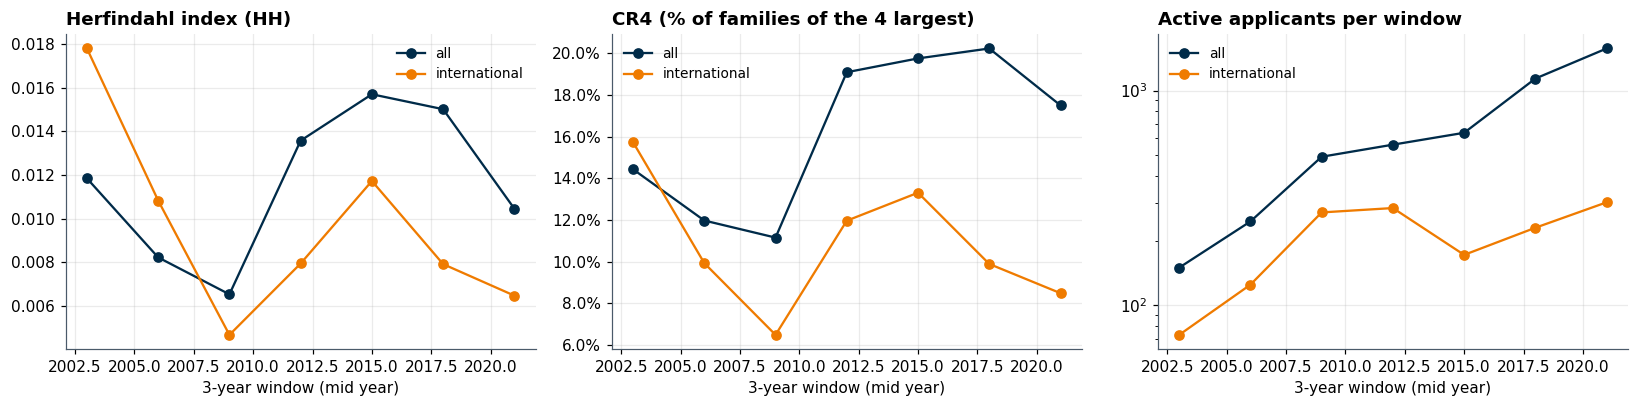

sample,window,mid,applicants,HH,1/HH,CR4,top-4 applicants
all,2002-2004,2003.0,150,0.0119,84.4,14.4%,"United States Of Ameri, Chinese Academy Of Sci, Tkms (Atlas Elektronik, Honeywell Internationa"
all,2005-2007,2006.0,246,0.0082,121.5,12.0%,"Chinese Academy Of Sci, Tkms (Atlas Elektronik, United States Of Ameri, Mitsui Engineering And"
all,2008-2010,2009.0,492,0.0065,153.0,11.2%,"Harbin Engineering Uni, Chinese Academy Of Sci, Tkms (Atlas Elektronik, China State Shipbuildi"
all,2011-2013,2012.0,560,0.0136,73.6,19.1%,"Chinese Academy Of Sci, Samsung Heavy Industri, Harbin Engineering Uni, Hanwha"
all,2014-2016,2015.0,636,0.0157,63.7,19.8%,"Harbin Engineering Uni, Chinese Academy Of Sci, China State Shipbuildi, Zhejiang University"
all,2017-2019,2018.0,1137,0.0150,66.6,20.2%,"Harbin Engineering Uni, Chinese Academy Of Sci, Northwestern Polytechn, China State Shipbuildi"
all,2020-2022,2021.0,1569,0.0105,95.6,17.5%,"Harbin Engineering Uni, Northwestern Polytechn, Chinese Academy Of Sci, China State Shipbuildi"
international,2002-2004,2003.0,73,0.0178,56.2,15.7%,"Tkms (Atlas Elektronik, Richter Ralf, Oceaneering, Lambertus Detlef"
international,2005-2007,2006.0,125,0.0108,92.3,9.9%,"Tkms (Atlas Elektronik, Institut Francais De R, Ciausu Viorel, Fournier Jean Claude"
international,2008-2010,2009.0,271,0.0047,213.7,6.5%,"Tkms (Atlas Elektronik, Eni, Kalwa Joerg, Schlumberger Canada"


In [25]:
def windows(end=LAST, size=WINDOW, n=8):
    """n consecutive windows of `size` years, the last one ending at the last complete year. Only FULL windows are kept:
    a shorter first window (e.g. 2000-2001) has fewer families and would inflate HH and CR4."""
    raw = [(e - size + 1, e) for e in range(end, end - size * n, -size)][::-1]
    return [w for w in raw if w[0] >= YEAR_MIN]


rows = []
for sample in ["all", "international"]:
    d0 = links[links["docdb_family_id"].isin(SAMPLES[sample])]
    for a, b_ in windows():
        d = d0[d0["family_year"].between(a, b_)]
        x = d.groupby("applicant")["docdb_family_id"].nunique()
        if len(x) < 5:
            continue
        rows.append({
            "sample": sample, "window": f"{a}-{b_}", "mid": (a + b_) / 2, "applicants": len(x),
            "HH": herfindahl(x), "1/HH": 1 / herfindahl(x), "CR4": concentration_ratio(x, 4),
            "top-4 applicants": ", ".join(x.sort_values(ascending=False).head(4).index.str.title().str[:22])
        })
cons = pd.DataFrame(rows)
save_table(cons.round(4), "concentration_over_time", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for sample, c in [("all", NAVY), ("international", ORANGE)]:
    d = cons[cons["sample"] == sample]
    axes[0].plot(d["mid"], d["HH"], marker="o", color=c, label=sample)
    axes[1].plot(d["mid"], d["CR4"] * 100, marker="o", color=c, label=sample)
    axes[2].plot(d["mid"], d["applicants"], marker="o", color=c, label=sample)
axes[0].set(title="Herfindahl index (HH)", xlabel="3-year window (mid year)")
axes[1].set(title="CR4 (% of families of the 4 largest)", xlabel="3-year window (mid year)")
axes[1].yaxis.set_major_formatter(PercentFormatter(100))
axes[2].set(title="Active applicants per window", xlabel="3-year window (mid year)")
axes[2].set_yscale("log")
for ax in axes:
    ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
save(fig, "s2_concentration_over_time")
plt.show()
display(cons.style.format({"HH": "{:.4f}", "1/HH": "{:,.1f}", "CR4": "{:.1%}", "mid": "{:.1f}"}).hide(axis="index"))

In [26]:
# Is the field consolidating? The sentence is computed from the table above: copy it into the slide.
a = cons[cons["sample"] == "all"].reset_index(drop=True)
first, peak, last, prev = a.iloc[0], a.loc[a["HH"].idxmax()], a.iloc[-1], a.iloc[-2]
chg = last["HH"] / prev["HH"] - 1
trend = "consolidating" if chg > 0.10 else "de-concentrating" if chg < -0.10 else "stable"
print(f"HH {first['HH']:.4f} ({first['window']}) -> peak {peak['HH']:.4f} ({peak['window']}) -> {last['HH']:.4f} ({last['window']}); "
      f"CR4 {first['CR4']:.1%} -> {peak['CR4']:.1%} at the HH peak -> {last['CR4']:.1%}; active applicants {first['applicants']:,} -> {last['applicants']:,}.")
print(f"In the last window the field is {trend} (HH {chg:+.0%} against the previous window); the applicants keep entering: "
      f"{last['applicants'] / prev['applicants'] - 1:+.0%} active applicants.")
KEY["HH_first_window"], KEY["HH_peak_window"], KEY["HH_last_window"] = float(first["HH"]), float(peak["HH"]), float(last["HH"])
KEY["HH_trend_last_window"] = trend


HH 0.0119 (2002-2004) -> peak 0.0157 (2014-2016) -> 0.0105 (2020-2022); CR4 14.4% -> 19.8% at the HH peak -> 17.5%; active applicants 150 -> 1,569.
In the last window the field is de-concentrating (HH -30% against the previous window); the applicants keep entering: +38% active applicants.


### 2.1.2 Concentration by country, and the Lorenz curves

The comparative design of Liston-Heyes & Pilkington (2004) on our sector: the measures computed separately on the
applicants of each country (applicant country, complete years), then countries ranked under each measure and the
agreement between rankings measured with Kendall's tau-b. Countries with at least 30 applicants only.

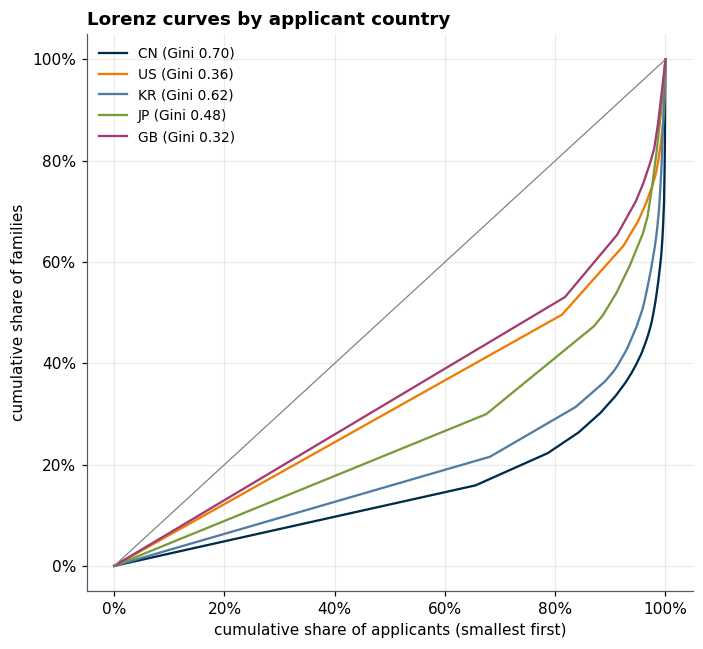

,applicants,families (sum),CR4,CR8,HH,1/HH,CV,Gini,Lotka L,Lotka p
CN,"1,977","8,156",25.1%,32.3%,0.021,48.0,6.34,0.70,-0.99,0.000
US,709,"1,161",13.8%,18.8%,0.009,109.7,2.34,0.36,-1.43,0.000
KR,264,835,33.5%,43.7%,0.037,26.9,2.97,0.62,-0.96,0.000
RU,138,278,23.7%,35.3%,0.024,42.0,1.52,0.44,-1.39,0.000
JP,123,277,31.0%,40.8%,0.032,31.3,1.72,0.48,-1.20,0.000
GB,148,228,20.2%,28.1%,0.017,58.9,1.23,0.32,-1.64,0.001
FR,89,212,35.4%,44.8%,0.040,25.0,1.61,0.49,-1.22,0.002
DE,64,206,60.7%,69.4%,0.174,5.8,3.21,0.65,-0.68,0.031
NO,89,164,31.7%,42.1%,0.039,25.6,1.58,0.41,-1.29,0.004
CA,52,69,20.3%,31.9%,0.027,37.5,0.63,0.21,-2.14,0.023


,CV,CR4,CR8,HH,Lotka L,Gini
CV,1.00,0.28,0.26,0.10,0.73,0.82
CR4,0.28,1.00,0.97,0.82,0.42,0.41
CR8,0.26,0.97,1.00,0.85,0.39,0.38
HH,0.10,0.82,0.85,1.00,0.27,0.23
Lotka L,0.73,0.42,0.39,0.27,1.00,0.82
Gini,0.82,0.41,0.38,0.23,0.82,1.00


In [27]:
by_ctry = {}
for ctry, d in links_c.groupby("country"):
    x = d.groupby("applicant")["docdb_family_id"].nunique()
    if len(x) >= 30:
        by_ctry[ctry] = six_measures(x)
by_ctry = pd.DataFrame(by_ctry).T.sort_values("families (sum)", ascending=False)
save_table(by_ctry.round(4), "concentration_by_country")
MEAS = ["CV", "CR4", "CR8", "HH", "Lotka L", "Gini"]
scores = by_ctry[MEAS].copy(); scores["Lotka L"] = -scores["Lotka L"].abs()
tau = pd.DataFrame(index=MEAS, columns=MEAS, dtype=float)
for a in MEAS:
    for b_ in MEAS:
        tau.loc[a, b_] = stats.kendalltau(scores[a], scores[b_], nan_policy="omit")[0]

fig, ax = plt.subplots(figsize=(6.5, 6))
for ctry, c in zip(["CN", "US", "KR", "JP", "GB"], PALETTE):
    x = links_c[links_c.country == ctry].groupby("applicant")["docdb_family_id"].nunique()
    if len(x):
        f_, p_ = lorenz_curve(x); ax.plot(f_, p_, color=c, label=f"{ctry} (Gini {gini(x):.2f})")
ax.plot([0, 1], [0, 1], color="grey", lw=0.8)
ax.set(title="Lorenz curves by applicant country", xlabel="cumulative share of applicants (smallest first)", ylabel="cumulative share of families")
ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); save(fig, "s2_lorenz_by_country"); plt.show()
display(by_ctry.style.format({"applicants": "{:,.0f}", "families (sum)": "{:,.0f}", "CR4": "{:.1%}", "CR8": "{:.1%}", "HH": "{:.3f}",
                              "1/HH": "{:,.1f}", "CV": "{:.2f}", "Gini": "{:.2f}", "Lotka L": "{:.2f}", "Lotka p": "{:.3f}"}, na_rep="–"))
tau.round(2)

## 2.2 The players: incumbents, entrants and the shortlist for Step 3

**Top applicants** with type, country, size, momentum and a first look at quality. Definitions (all design choices):

- **incumbent**: first family in the sector before `SPLIT_YEAR` (2015); **entrant**: from 2015 on;
- **momentum**: share of the sector's families in 2018–2022 minus share in 2013–2017 (percentage points);
- **influence preview**: forward citations within 5 years divided by the mean of the families of the same priority
  year (Tutorial 4 §5.1; complete 5-year windows only), averaged over the applicant's families: 1 = average;
- **international share**: share of the applicant's families filed at more than one office or via PCT.

In [28]:
fam["fwd5_norm"] = np.nan
ok = fam["fwd_window_complete"]
fam.loc[ok, "fwd5_norm"] = fam.loc[ok, "fwd_cits_5y"] / fam.loc[ok].groupby("family_year")["fwd_cits_5y"].transform("mean").replace(0, np.nan)
fl = links.merge(fam[["docdb_family_id", "is_international", "granted_any", "fwd5_norm", "n_offices"]], on="docdb_family_id")

tot_past = fam["family_year"].between(*PAST).sum()
tot_rec = fam["family_year"].between(*RECENT).sum()
g = fl.groupby("applicant")
rec_n = fl[fl["family_year"].between(*RECENT)].groupby("applicant")["docdb_family_id"].nunique().reindex(g.size().index, fill_value=0)
past_n = fl[fl["family_year"].between(*PAST)].groupby("applicant")["docdb_family_id"].nunique().reindex(g.size().index, fill_value=0)
players = pd.DataFrame({
    "type": g["type"].first(),
    "country": g["country"].agg(lambda s: s.mode().iat[0] if s.notna().any() else None),
    "families": g["docdb_family_id"].nunique(),
    "families (<=2022)": fl[fl["family_year"] <= LAST].groupby("applicant")["docdb_family_id"].nunique(),
    "fractional": g["weight"].sum(),
    "first year": g["family_year"].min(),
    "last year": g["family_year"].max(),
    f"families since {SPLIT_YEAR}": fl[fl["family_year"] >= SPLIT_YEAR].groupby("applicant")["docdb_family_id"].nunique(),
    f"families {RECENT[0]}-{RECENT[1]}": fl[fl["family_year"].between(*RECENT)].groupby("applicant")["docdb_family_id"].nunique(),
    "momentum (pp)": (rec_n / tot_rec - past_n / tot_past) * 100,        # both aligned on ALL applicants: a player with no recent family gets a negative value
    "international share": g["is_international"].mean(),
    "mean offices": g["n_offices"].mean(),
    "granted share": g["granted_any"].mean(),
    "influence (fwd5, 1 = avg)": g["fwd5_norm"].mean(),
}).fillna({"families (<=2022)": 0, f"families since {SPLIT_YEAR}": 0, f"families {RECENT[0]}-{RECENT[1]}": 0})
players["share of sector"] = players["families"] / len(fam)
players["status"] = np.where(players["first year"] < SPLIT_YEAR, "incumbent", "entrant")
players["is client"] = players.index == CLIENT
players = players.sort_values("families", ascending=False)
save_table(players, "players_all")
save_table(players, "tab_share_of_each_years_families")

FMT_P = {
    "families": "{:,.0f}", "families (<=2022)": "{:,.0f}", "fractional": "{:,.1f}",
    "first year": "{:.0f}", "last year": "{:.0f}",
    f"families since {SPLIT_YEAR}": "{:,.0f}", f"families {RECENT[0]}-{RECENT[1]}": "{:,.0f}",
    "momentum (pp)": "{:+.2f}", "international share": "{:.0%}",
    "mean offices": "{:.2f}", "granted share": "{:.0%}",
    "influence (fwd5, 1 = avg)": "{:.2f}", "share of sector": "{:.2%}"
}
cols_show = [
    "type", "country", "families", "share of sector", "first year", "status",
    f"families {RECENT[0]}-{RECENT[1]}", "momentum (pp)", "international share", "influence (fwd5, 1 = avg)"
]
display(short(players.head(TOP_N)[cols_show]).style.format(FMT_P, na_rep="–"))

,type,country,families,share of sector,first year,status,families 2018-2022,momentum (pp),international share,"influence (fwd5, 1 = avg)"
applicant,,,,,,,,,,
HARBIN ENGINEERING UNIVERSITY,university,CN,"1,226",7.78%,2004,incumbent,508,-1.22,1%,1.17
CHINESE ACADEMY OF SCIENCES,university,CN,804,5.10%,2001,incumbent,329,-1.02,2%,0.68
CHINA STATE SHIPBUILDING (CSSC),firm,CN,697,4.42%,2007,incumbent,208,-0.11,0%,0.91
NORTHWESTERN POLYTECHNICAL UNIVERSITY,university,CN,575,3.65%,2010,incumbent,290,+1.91,0%,1.27
ZHEJIANG UNIVERSITY,university,CN,381,2.42%,2006,incumbent,165,+0.06,4%,1.32
JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY,university,CN,223,1.42%,2013,incumbent,100,+0.25,5%,1.64
TIANJIN UNIVERSITY,university,CN,199,1.26%,2005,incumbent,85,+1.06,2%,1.03
DALIAN MARITIME UNIVERSITY,university,CN,165,1.05%,2013,incumbent,91,+1.03,2%,0.97
HOHAI UNIVERSITY,university,CN,158,1.00%,2010,incumbent,54,-0.52,4%,1.09


The overall ranking is a ranking of **Chinese universities**. For an acquirer that is not the relevant competitive
set: a university cannot be bought (it can be a *partner*, licensor or source of spin-offs, IM_Theory_2). The deck
table should therefore show three views: top firms worldwide, top firms outside China, and top universities /
public research organisations (potential partners).

In [29]:
firms = players[players.type.isin(["firm", "unknown"])]
display(short(firms.head(TOP_N)[cols_show]).style.format(FMT_P, na_rep="–").set_caption("Top firms (incl. unclassified companies)"))
display(short(firms[firms.country != "CN"].head(TOP_N)[cols_show]).style.format(FMT_P, na_rep="–").set_caption("Top firms outside China"))
short(players[players.type.isin(["university", "government / non-profit"])].head(10)[cols_show]).style.format(FMT_P, na_rep="–").set_caption("Top universities and public research organisations")

,type,country,families,share of sector,first year,status,families 2018-2022,momentum (pp),international share,"influence (fwd5, 1 = avg)"
applicant,,,,,,,,,,
CHINA STATE SHIPBUILDING (CSSC),firm,CN,697,4.42%,2007,incumbent,208,-0.11,0%,0.91
CNOOC,firm,CN,102,0.65%,2007,incumbent,35,-0.29,0%,0.51
HANWHA,firm,KR,101,0.64%,2003,incumbent,41,-0.60,0%,0.46
TKMS (ATLAS ELEKTRONIK),firm,DE,96,0.61%,2000,incumbent,18,-0.56,95%,0.80
SAMSUNG HEAVY INDUSTRIES,firm,KR,91,0.58%,2010,incumbent,1,-2.60,2%,0.27
CHINA THREE GORGES,firm,CN,60,0.38%,2012,incumbent,11,+0.17,2%,0.78
CHINA HUANENG GROUP,firm,CN,57,0.36%,2020,entrant,16,+0.25,4%,–
DEEPFAR OCEAN TECHNOLOGY,firm,CN,53,0.34%,2016,entrant,14,-0.54,4%,0.43
OCEANEERING,firm,US,45,0.29%,2000,incumbent,10,-0.65,76%,1.16


,type,country,families,share of sector,first year,status,families 2018-2022,momentum (pp),international share,"influence (fwd5, 1 = avg)"
applicant,,,,,,,,,,
HANWHA,firm,KR,101,0.64%,2003,incumbent,41,-0.60,0%,0.46
TKMS (ATLAS ELEKTRONIK),firm,DE,96,0.61%,2000,incumbent,18,-0.56,95%,0.80
SAMSUNG HEAVY INDUSTRIES,firm,KR,91,0.58%,2010,incumbent,1,-2.60,2%,0.27
OCEANEERING,firm,US,45,0.29%,2000,incumbent,10,-0.65,76%,1.16
BAE SYSTEMS,firm,GB,41,0.26%,2001,incumbent,18,+0.20,34%,0.83
THYSSEN KRUPP,firm,DE,40,0.25%,2014,incumbent,18,+0.04,98%,0.36
LIG NEX1,firm,KR,32,0.20%,2010,incumbent,17,+0.03,0%,0.27
IHI ISHIKAWAJIMA HARIMA HEAVY INDUSTRIES,firm,JP,29,0.18%,2008,incumbent,8,-0.32,10%,0.81
FEDERALNOE GOSUDARSTVENNOE KAZENNOE VOENNOE …,unknown,RU,26,0.17%,2016,entrant,22,+0.19,0%,0.04


,type,country,families,share of sector,first year,status,families 2018-2022,momentum (pp),international share,"influence (fwd5, 1 = avg)"
applicant,,,,,,,,,,
HARBIN ENGINEERING UNIVERSITY,university,CN,"1,226",7.78%,2004,incumbent,508,-1.22,1%,1.17
CHINESE ACADEMY OF SCIENCES,university,CN,804,5.10%,2001,incumbent,329,-1.02,2%,0.68
NORTHWESTERN POLYTECHNICAL UNIVERSITY,university,CN,575,3.65%,2010,incumbent,290,+1.91,0%,1.27
ZHEJIANG UNIVERSITY,university,CN,381,2.42%,2006,incumbent,165,+0.06,4%,1.32
JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY,university,CN,223,1.42%,2013,incumbent,100,+0.25,5%,1.64
TIANJIN UNIVERSITY,university,CN,199,1.26%,2005,incumbent,85,+1.06,2%,1.03
DALIAN MARITIME UNIVERSITY,university,CN,165,1.05%,2013,incumbent,91,+1.03,2%,0.97
HOHAI UNIVERSITY,university,CN,158,1.00%,2010,incumbent,54,-0.52,4%,1.09
OCEAN UNIVERSITY OF CHINA,university,CN,157,1.00%,2008,incumbent,67,+0.13,2%,1.38


**Start-ups.** The kick-off asks for the applicant type *firm / start-up / university*, but `psn_sector` has no
start-up category. Offline proxy (to verify by hand on company websites / Crunchbase): a **young firm** is a firm
whose first family in the sector is from 2015 on, with **3 to 30 families, active in at least 2 different years and
still active in the last two complete years**, not part of a large group in `GROUP_ALIASES`. (Without these filters the
proxy flagged more than a thousand small applicants, most of them single-family filers.) On TIP, the optional cell below refines it with the year of the **first patent ever, in any field**
(Tutorial 1 nb 11 §5.0: "they never patented before").

Read the list with care: the proxy also catches **large incumbents of other industries** that enter the sector late
(power grids, oil majors, rail-equipment makers). They are *diversifying entrants*, not start-ups, and they are a
finding in themselves (who is moving into underwater drones, and from where). The first-patent-ever refinement
separates the two groups.

In [30]:
big_groups = set(C.GROUP_ALIASES.values())
years_active = links.groupby("applicant")["family_year"].nunique()
players["years active"] = years_active.reindex(players.index).fillna(0).astype(int)
players["young firm (start-up candidate)"] = (
    players["type"].isin(["firm", "unknown"])
    & (players["first year"].between(SPLIT_YEAR, LAST))
    & (players["families"].between(3, 30))
    & (players["years active"] >= 2)
    & (players["last year"] >= LAST - 1)
    & ~players.index.isin(big_groups)
)
young = players[players["young firm (start-up candidate)"]].head(15)
save_table(players, "players_all")
print(f"{players['young firm (start-up candidate)'].sum():,} young firms (entered {SPLIT_YEAR}-{LAST}, 3-30 families, still active); the largest:")
display(short(young[["country", "families", "first year", "years active", "international share", "influence (fwd5, 1 = avg)"]]).style.format(FMT_P, na_rep="–"))


144 young firms (entered 2015-2022, 3-30 families, still active); the largest:


,country,families,first year,years active,international share,"influence (fwd5, 1 = avg)"
applicant,,,,,,
SGCC STATE GRID CORPORATION OF CHINA,CN,30,2015,8,0%,3.04
ZHUZHOU CRRC TIMES ELECTRIC,CN,28,2019,6,7%,–
FEDERALNOE GOSUDARSTVENNOE KAZENNOE VOENNOE …,RU,26,2016,6,0%,0.04
GUANGDONG POWER GRID,CN,26,2020,5,0%,–
KUNMING HAIWEI ELECTROMECHANICAL TECHNOLOGY …,CN,24,2019,7,0%,–
ARTIFICIAL INTELLIGENCE ROBOT,KR,20,2017,5,5%,0.14
QINGDAO PENGPAI OCEAN EXPLORATION TECHNOLOGY,CN,19,2019,6,0%,–
SAUDI ARABIAN OIL,SA,19,2015,9,74%,3.38
SHENGDONG RUDONG OFFSHORE WIND POWER GENERAT…,CN,19,2022,3,0%,–


In [31]:
if RUN_PATSTAT:   # TIP only: first patent ever (any field) of the top applicants, from their PATSTAT names
    from epo.tipdata.patstat import PatstatClient
    from epo.tipdata.patstat.database.models import TLS201_APPLN, TLS206_PERSON, TLS207_PERS_APPLN
    from sqlalchemy import func
    patstat = PatstatClient(env=C.ENV); db = patstat.orm()
    raw = appl.drop_duplicates("applicant").set_index("applicant")["raw_names"].dropna()
    names = {n.strip(): grp_name for grp_name, s in raw.loc[raw.index.isin(players.head(300).index)].items() for n in s.split("|")}
    q = (db.query(TLS206_PERSON.psn_name, func.min(TLS201_APPLN.earliest_filing_year).label("first_patent_year"))
         .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
         .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS207_PERS_APPLN.appln_id)
         .filter(TLS206_PERSON.psn_name.in_(list(names)), TLS207_PERS_APPLN.applt_seq_nr > 0,
                 TLS201_APPLN.earliest_filing_year.between(1900, YEAR_MAX))
         .group_by(TLS206_PERSON.psn_name))
    first_ever = patstat.df(q).assign(applicant=lambda d: d.psn_name.map(names)).groupby("applicant")["first_patent_year"].min()
    players["first patent ever"] = first_ever
    players.to_csv(OUT / "players_all.csv")
else:
    print("RUN_PATSTAT = False: first-patent-ever not queried (run on TIP to refine the start-up flag)")

RUN_PATSTAT = False: first-patent-ever not queried (run on TIP to refine the start-up flag)


### 2.2.1 Shortlist for Step 3 (present score)

The players worth scoring: **firms** (including unclassified companies) with at least `MIN_FAMILIES_SCORE` families
in the sector (a volume gate, as in Clarivate and Tutorial 4), plus the client as a reference point. Saved as
`shortlist_step3.csv`. The choice of gate is a design decision to justify in the appendix.

In [32]:
shortlist = players[(players.type.isin(["firm", "unknown"]) & (players.families >= MIN_FAMILIES_SCORE)) | players["is client"]]
save_table(shortlist, "shortlist_step3")
KEY["shortlist_size"] = int(len(shortlist))
print(f"{len(shortlist)} applicants in the shortlist ({(shortlist.country != 'CN').sum()} outside China); client included: {CLIENT in shortlist.index}")
short(shortlist.head(25)[cols_show]).style.format(FMT_P, na_rep="–")

99 applicants in the shortlist (41 outside China); client included: True


,type,country,families,share of sector,first year,status,families 2018-2022,momentum (pp),international share,"influence (fwd5, 1 = avg)"
applicant,,,,,,,,,,
CHINA STATE SHIPBUILDING (CSSC),firm,CN,697,4.42%,2007,incumbent,208,-0.11,0%,0.91
CNOOC,firm,CN,102,0.65%,2007,incumbent,35,-0.29,0%,0.51
HANWHA,firm,KR,101,0.64%,2003,incumbent,41,-0.60,0%,0.46
TKMS (ATLAS ELEKTRONIK),firm,DE,96,0.61%,2000,incumbent,18,-0.56,95%,0.80
SAMSUNG HEAVY INDUSTRIES,firm,KR,91,0.58%,2010,incumbent,1,-2.60,2%,0.27
CHINA THREE GORGES,firm,CN,60,0.38%,2012,incumbent,11,+0.17,2%,0.78
CHINA HUANENG GROUP,firm,CN,57,0.36%,2020,entrant,16,+0.25,4%,–
DEEPFAR OCEAN TECHNOLOGY,firm,CN,53,0.34%,2016,entrant,14,-0.54,4%,0.43
OCEANEERING,firm,US,45,0.29%,2000,incumbent,10,-0.65,76%,1.16


## 2.3 Entry and exit, year by year

As in Tutorial 1 nb 11 §5.2: for each priority year, the active applicants, those **new to the sector** (first
family in the sector that year), the **entrants' share of families** (families with at least one applicant new to
the sector) and the **rate of disappearance** (share of the year's active applicants that never file again in the
sector; shown only up to `LAST − 3`, because an applicant silent in the last years may simply not be published yet).
In the first years almost everyone looks new (families before 2000 are not seen): read entry from about 2005.

metric,value
Incumbents among the 30 largest applicants (all types),26
Entrants among the 30 largest applicants (all types),4
Incumbents among the 30 largest firms,18
Entrants among the 30 largest firms,12
Largest incumbents (firms),"CHINA STATE SHIPBUILDING (CSSC), CNOOC, HANWHA, TKMS (ATLAS ELEKTRONIK)"
"Largest entrants (firms, first family from 2015)","CHINA HUANENG GROUP, DEEPFAR OCEAN TECHNOLOGY, SHANGHAI CRRC SMD MARINE EQUIPMENT, ROBOSEA BEIJING ROBOT SCIENCE AND TECHNOLOGY"
Average entrants' share of families in the last 5 complete years (%),33.9%


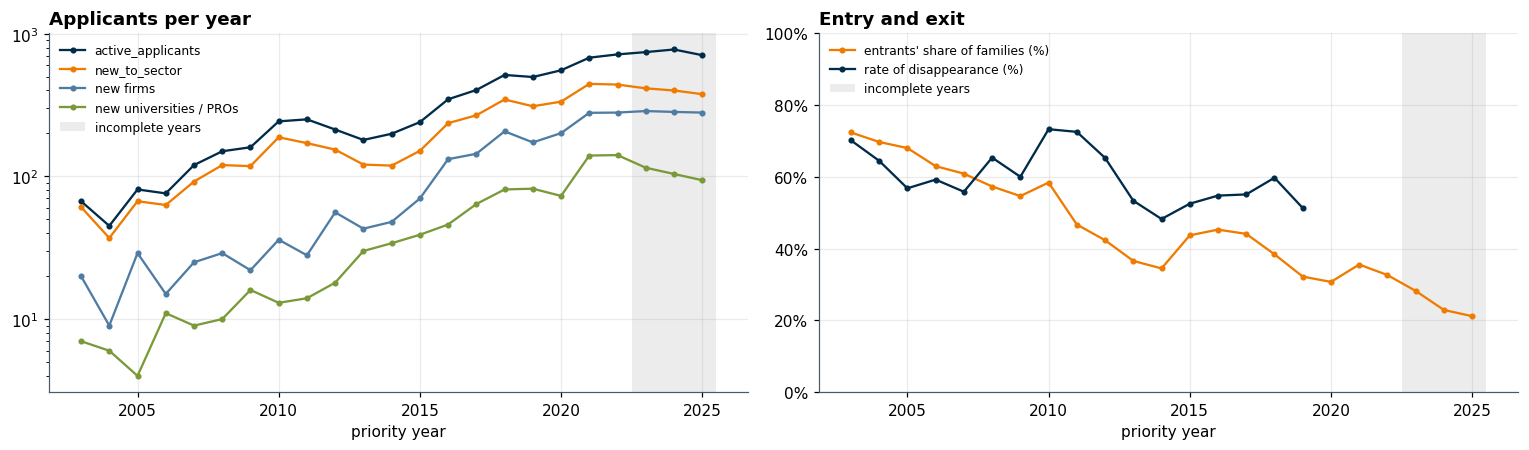

,active_applicants,new_to_sector,leaving,new firms,new universities / PROs,rate of disappearance (%),entrants' share of families (%)
year,,,,,,,
2003,67,61,47,20,7,70.1,72.3
2004,45,37,29,9,6,64.4,69.7
2005,81,67,46,29,4,56.8,68.0
2006,76,63,45,15,11,59.2,63.0
2007,120,92,67,25,9,55.8,60.9
2008,150,120,98,29,10,65.3,57.3
2009,160,118,96,22,16,60.0,54.6
2010,243,188,178,36,13,73.3,58.4
2011,251,171,182,28,14,72.5,46.7


In [33]:
first_year = links.groupby("applicant")["family_year"].min()
last_year = links.groupby("applicant")["family_year"].max()
active = links[["applicant", "family_year", "type"]].rename(columns={"family_year": "year"}).drop_duplicates(["applicant", "year"])
active["new"] = active["year"] == active["applicant"].map(first_year)
active["leaving"] = active["year"] == active["applicant"].map(last_year)
ee = active.groupby("year").agg(active_applicants=("applicant", "size"), new_to_sector=("new", "sum"), leaving=("leaving", "sum"))
if "first patent ever" in players.columns:
    first_ever_map = players["first patent ever"].to_dict()
    active["new_to_patenting"] = active["year"] == active["applicant"].map(first_ever_map)
    ee["new_to_patenting"] = active.groupby("year")["new_to_patenting"].sum()
ee["new firms"] = active[active["type"].isin(["firm", "unknown"])].groupby("year")["new"].sum()
ee["new universities / PROs"] = active[active["type"].isin(["university", "government / non-profit"])].groupby("year")["new"].sum()
ee["rate of disappearance (%)"] = ee["leaving"] / ee["active_applicants"] * 100
ee.loc[ee.index > LAST - 3, "rate of disappearance (%)"] = np.nan
ln = links.assign(new=links["family_year"] == links["applicant"].map(first_year))
ee["entrants' share of families (%)"] = ln.groupby(["family_year", "docdb_family_id"])["new"].any().groupby("family_year").mean() * 100
ee = ee.loc[2003:YEAR_MAX]
save_table(ee.round(1), "entry_exit")
save_table(ee.round(1), "tab_categorised_applicants")
KEY["entrants_share_last5"] = float(ee.loc[LAST - 4:LAST, "entrants' share of families (%)"].mean() / 100)

# Summary table of Incumbents vs Entrants (from LANDSCAPE.py, Tutorial 1 nb 11 §5.2)
top30_all = players.head(30)
top30_firms = firms.head(30)
inc_all = top30_all[top30_all["status"] == "incumbent"].index.tolist()
ent_all = top30_all[top30_all["status"] == "entrant"].index.tolist()
inc_firms = top30_firms[top30_firms["status"] == "incumbent"].index.tolist()
ent_firms = top30_firms[top30_firms["status"] == "entrant"].index.tolist()

inc_ent_summary = pd.DataFrame({
    "metric": [
        "Incumbents among the 30 largest applicants (all types)",
        "Entrants among the 30 largest applicants (all types)",
        "Incumbents among the 30 largest firms",
        "Entrants among the 30 largest firms",
        "Largest incumbents (firms)",
        f"Largest entrants (firms, first family from {SPLIT_YEAR})",
        "Average entrants' share of families in the last 5 complete years (%)",
    ],
    "value": [
        len(inc_all),
        len(ent_all),
        len(inc_firms),
        len(ent_firms),
        ", ".join(inc_firms[:4]) or "none",
        ", ".join(ent_firms[:4]) or "none",
        f"{KEY['entrants_share_last5'] * 100:.1f}%",
    ]
})
save_table(inc_ent_summary, "tab_incumbents_and_entrants", index=False)
display(inc_ent_summary.style.hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
ee[["active_applicants", "new_to_sector", "new firms", "new universities / PROs"]].plot(
    ax=axes[0], marker="o", ms=3, color=[NAVY, ORANGE, BLUE, GREEN]
)
axes[0].set(title="Applicants per year", xlabel="priority year")
axes[0].set_yscale("log")
ee[["entrants' share of families (%)", "rate of disappearance (%)"]].plot(
    ax=axes[1], marker="o", ms=3, color=[ORANGE, NAVY]
)
axes[1].set(title="Entry and exit", xlabel="priority year", ylim=(0, 100))
axes[1].yaxis.set_major_formatter(PercentFormatter(100))
for ax in axes:
    shade(ax)
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
save(fig, "s2_entry_exit")
plt.show()
display(ee.round(1))

**Persistence.** Most applicants appear once and disappear. The share of applicants active in at least 3 distinct
years, by type, separates the *persistent* innovators (Patel & Pavitt, 1997: competences are path-dependent) from
occasional filers.

In [34]:
persist = links.groupby(["applicant"]).agg(type=("type", "first"), years_active=("family_year", "nunique"), families=("docdb_family_id", "nunique"))
pers = persist.groupby("type").agg(applicants=("years_active", "size"), share_active_3plus_years=("years_active", lambda s: (s >= 3).mean()),
                                   share_one_family=("families", lambda s: (s == 1).mean()))
save_table(pers.round(3), "tab_persistence_by_type")
pers.style.format({"applicants": "{:,.0f}", "share_active_3plus_years": "{:.1%}", "share_one_family": "{:.1%}"})

,applicants,share_active_3plus_years,share_one_family
type,,,
firm,"1,690",12.0%,63.6%
government / non-profit,386,16.8%,59.6%
hospital,2,0.0%,50.0%
individual,"1,250",1.1%,86.7%
university,776,27.6%,50.3%
unknown,"1,071",2.6%,77.6%


## 2.4 Subfields: which parts of the sector grow fastest?

Two independent definitions of a subfield, as the kick-off suggests (*"growth of CPC groups, or topics from
abstracts"*). If both point to the same growth areas, the result is robust to the definition.

### 2.4.1 CPC main groups: growth map and maturity matrix

A subfield = a CPC main group (e.g. `G05D1/`, `G06N3/`), allocation codes only (the Y and 2000-series indexing
codes are kept apart, except `B63G2008/` which names the unmanned vessels themselves). Families counted once per
subfield. Growth = families in 2018–2022 vs 2013–2017. Only subfields with at least 30 recent families are mapped,
so tiny groups with huge percentages do not win (Tutorial 1 nb 11 §5.3).

subfield,title (verify),families 2013-2017,families 2018-2022,growth (%),maturity quadrant
G06F17/,"Digital computing or data processing equipment or methods, specially adapted for specific functions",2,60,+2900%,emerging
G06F18/,Pattern recognition,4,73,+1725%,emerging
G06N3/,"Computing arrangements based on biological models, e.g. neural networks",9,164,+1722%,current hot topic
B60L53/,(check on CPC scheme),7,72,+929%,emerging
G01N21/,(check on CPC scheme),7,60,+757%,emerging


subfield,title (verify),families 2013-2017,families 2018-2022
G01R33/,(check on CPC scheme),0,17
G06T3/,(check on CPC scheme),0,17
H02N2/,(check on CPC scheme),0,16
F16M11/,(check on CPC scheme),0,15
B60L58/,(check on CPC scheme),0,13
G01V8/,(check on CPC scheme),0,12
H02N11/,(check on CPC scheme),0,11
E02F7/,(check on CPC scheme),0,10


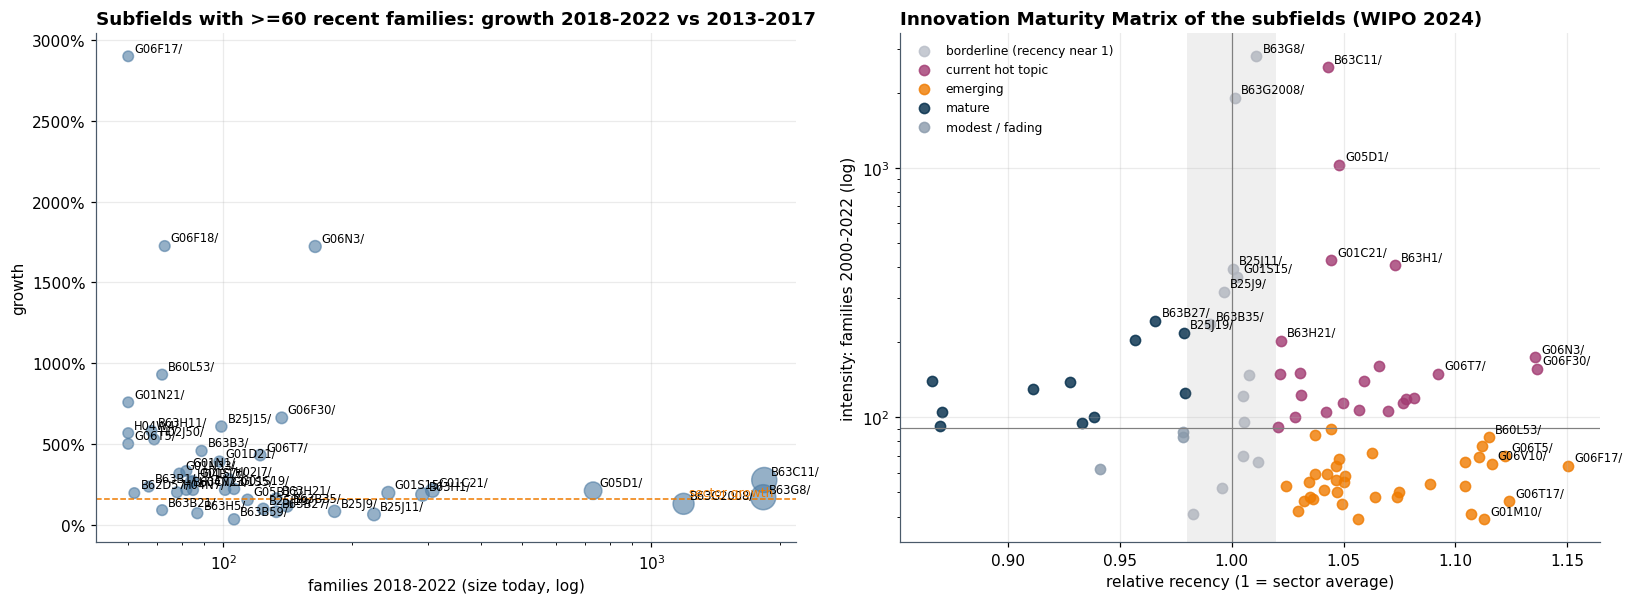

,families 2013-2017,families 2018-2022,growth (%),growth vs sector (pp),intensity (families <= 2022),relative recency,title (verify),maturity quadrant
main_group,,,,,,,,
B63C11/,488,"1,835",+276%,+120,"2,527",1.04,Equipment for dwelling or working under water; means for searching for underwater objects,current hot topic
B63G8/,677,"1,825",+170%,+14,"2,793",1.01,"Underwater vessels, e.g. submarines",borderline (recency near 1)
B63G2008/,520,"1,189",+129%,-27,"1,909",1.00,Unmanned underwater vessels [UUV] (indexing scheme),borderline (recency near 1)
G05D1/,236,731,+210%,+54,"1,026",1.05,"Control of position, course, altitude or attitude of land, water, air or space vehicles",current hot topic
G01C21/,99,308,+211%,+55,426,1.04,Navigation; navigational instruments not provided for in groups G01C1/00-G01C19/00,current hot topic
B63H1/,102,292,+186%,+31,407,1.07,"Propulsive elements directly acting on water, e.g. propellers",current hot topic
G01S15/,82,243,+196%,+41,365,1.00,"Systems using the reflection or reradiation of acoustic waves, e.g. sonar systems",borderline (recency near 1)
B25J11/,138,225,+63%,-93,394,1.00,"Manipulators not otherwise provided for, e.g. underwater manipulators",borderline (recency near 1)
B25J9/,100,182,+82%,-74,318,1.00,Programme-controlled manipulators,borderline (recency near 1)


In [35]:
MAIN_GROUP_TITLES = {   # official CPC main-group titles (verify on https://www.cooperativepatentclassification.org)
    "B63G8/": "Underwater vessels, e.g. submarines",
    "B63C11/": "Equipment for dwelling or working under water; means for searching for underwater objects",
    "B63G2008/": "Unmanned underwater vessels [UUV] (indexing scheme)",
    "G05D1/": "Control of position, course, altitude or attitude of land, water, air or space vehicles",
    "G01C21/": "Navigation; navigational instruments not provided for in groups G01C1/00-G01C19/00",
    "G06N3/": "Computing arrangements based on biological models, e.g. neural networks",
    "G01S15/": "Systems using the reflection or reradiation of acoustic waves, e.g. sonar systems",
    "B25J9/": "Programme-controlled manipulators",
    "G06V10/": "Image or video recognition or understanding (arrangements therefor)",
    "B63H1/": "Propulsive elements directly acting on water, e.g. propellers",
    "G06F30/": "Computer-aided design [CAD] or computer-aided engineering [CAE]",
    "G06T7/": "Image analysis, e.g. segmentation, feature extraction or motion estimation",
    "B25J11/": "Manipulators not otherwise provided for, e.g. underwater manipulators",
    "B63B27/": "Arrangement of ship-based loading or unloading equipment for cargo or passengers",
    "G06F18/": "Pattern recognition",
    "H02J7/": "Circuit arrangements for charging or depolarising batteries",
    "B25J19/": "Accessories fitted to manipulators, e.g. sensors or safety devices",
    "G01V1/": "Seismology; seismic or acoustic prospecting or detecting",
    "B63B35/": "Vessels or similar floating structures adapted for special purposes",
    "H04N23/": "Cameras or camera modules for generating image signals",
    "B63H21/": "Use of propulsion power plant or units on vessels",
    "H04B13/": "Transmission systems characterised by the medium, e.g. via water",
    "H04B11/": "Transmission systems using ultrasonic, sonic or infrasonic waves",
    "G01S7/": "Details of systems according to groups G01S13/00, G01S15/00, G01S17/00",
    "G01S5/": "Position-fixing by coordinating two or more direction or position-line determinations",
    "G05B13/": "Adaptive control systems, i.e. systems adjusting themselves to have optimal performance",
    "G05B17/": "Systems involving the use of models or simulators of said systems",
    "B08B1/": "Cleaning by methods involving the use of tools, brushes or like members",
    "B63B79/": "Monitoring properties or operating parameters of vessels in operation",
    "G01N33/": "Investigating or analysing materials by specific methods (incl. water analysis)",
    "B63B22/": "Buoys",
    "H01M50/": "Constructional details or processes of manufacture of non-active parts of batteries",
    "H01M10/": "Secondary cells; manufacture thereof",
    "F42B19/": "Marine torpedoes, e.g. launched by surface vessels or submarines",
    "H01M6/": "Primary cells; manufacture thereof",
    "G06F17/": "Digital computing or data processing equipment or methods, specially adapted for specific functions",
    "B63G9/": "Other offensive or defensive arrangements on vessels against submarines, torpedoes or mines",
    "B63B21/": "Tying-up; shifting, hauling or pushing equipment; anchoring; towing",
    "B63C7/": "Salvaging of disabled, stranded or sunken vessels; salvaging of vessel parts or cargoes",
    "B63H25/": "Steering; slowing-down otherwise than by use of propulsive elements; dynamic anchoring",
    "B63B1/": "Hydrodynamic or hydrostatic features of hulls or of hydrofoils",
    "B63B59/": "Hull protection peculiar to vessels; cleaning devices for hulls",
    "G01S19/": "Satellite radio beacon positioning systems; determining position, velocity or attitude using signals",
    "B25J15/": "Gripping heads for manipulators",
    "G01D21/": "Measuring or testing not otherwise provided for",
}

# Filter out Y tagging codes and 2000-series indexing codes (except B63G2008/ which specifically indexes UUVs)
is_2000_indexing = fcpc["main_group"].astype(str).str.match(r"^[A-Z]\d{2}[A-Z]2\d{3}/") & ~fcpc["main_group"].eq("B63G2008/")
mg = fcpc[(~fcpc["is_tagging"].astype(str).str.lower().eq("true")) & (~is_2000_indexing)].copy()
mg = mg[~mg["main_group"].astype(str).str.startswith("Y")].drop_duplicates(["docdb_family_id", "main_group"]).merge(
    fam[["docdb_family_id", "family_year"]], on="docdb_family_id"
)
past = mg[mg["family_year"].between(*PAST)].groupby("main_group")["docdb_family_id"].nunique()
recent = mg[mg["family_year"].between(*RECENT)].groupby("main_group")["docdb_family_id"].nunique()
sf = pd.DataFrame({f"families {PAST[0]}-{PAST[1]}": past, f"families {RECENT[0]}-{RECENT[1]}": recent}).fillna(0)
sf["growth (%)"] = (sf.iloc[:, 1] / sf.iloc[:, 0].replace(0, np.nan) - 1) * 100
sector_growth = (tot_rec / tot_past - 1) * 100
sf["growth vs sector (pp)"] = sf["growth (%)"] - sector_growth


def recency(yearly, start=YEAR_MIN, end=LAST):
    """Relative recency (WIPO 2024 Innovation Maturity Matrix), complete years 2000-LAST."""
    w = yearly.reindex(range(start, end + 1), fill_value=0).values.astype(float)
    i = np.arange(1, len(w) + 1)
    n = len(w)
    return (w * i).sum() / (n * w.sum()) if w.sum() else np.nan


R_sector = recency(fam.groupby("family_year").size())
mg_c = mg[mg["family_year"] <= LAST]
sf["intensity (families <= 2022)"] = mg_c.groupby("main_group")["docdb_family_id"].nunique()
sf["relative recency"] = mg_c.groupby("main_group").apply(lambda d: recency(d.groupby("family_year")["docdb_family_id"].nunique())) / R_sector
sf["title (verify)"] = [MAIN_GROUP_TITLES.get(i, "(check on CPC scheme)") for i in sf.index]
mapped = sf[sf.iloc[:, 1] >= 30].sort_values(sf.columns[1], ascending=False).copy()

med_int = mapped["intensity (families <= 2022)"].median()


BORDER = 0.02          # |relative recency - 1| below this is too close to call (the recency of most subfields is between 0.96 and 1.14)
BORDER_LABEL = "borderline (recency near 1)"


def quadrant(r):
    if abs(r["relative recency"] - 1) < BORDER:
        return BORDER_LABEL
    hi, rec_ = r["intensity (families <= 2022)"] >= med_int, r["relative recency"] >= 1
    return "current hot topic" if hi and rec_ else "emerging" if rec_ else "mature" if hi else "modest / fading"


mapped["maturity quadrant"] = mapped.apply(quadrant, axis=1)
save_table(mapped, "subfields_cpc")
save_table(mapped, "tab_growth_between_periods")

# Fastest-growing subfields table (from LANDSCAPE.py, Tutorial 1 nb 11 §5.3: among those >= median size today)
valid_growth = mapped[mapped.iloc[:, 0] > 0]
size_today = valid_growth.iloc[:, 1]
fastest = valid_growth[size_today >= size_today.median()].sort_values("growth (%)", ascending=False).head(5).copy()
tab_fastest = pd.DataFrame({
    "subfield": fastest.index,
    "title (verify)": fastest["title (verify)"].values,
    f"families {PAST[0]}-{PAST[1]}": fastest.iloc[:, 0].astype(int).values,
    f"families {RECENT[0]}-{RECENT[1]}": fastest.iloc[:, 1].astype(int).values,
    "growth (%)": fastest["growth (%)"].map(lambda x: f"{x:+.0f}%").values,
    "maturity quadrant": fastest["maturity quadrant"].values,
})
save_table(tab_fastest, "tab_fastest_growers", index=False)
display(tab_fastest.style.hide(axis="index").set_caption("Fastest-growing CPC subfields (at least median size today)"))

# Subfields with NO family in the past window: growth is undefined, so they are left out of the map and of the table above,
# but they are the newest ones: show them apart.
new_sf = sf[(sf.iloc[:, 0] == 0) & (sf.iloc[:, 1] >= 10)].sort_values(sf.columns[1], ascending=False)
tab_new = pd.DataFrame({"subfield": new_sf.index, "title (verify)": new_sf["title (verify)"].values,
                        f"families {PAST[0]}-{PAST[1]}": 0, f"families {RECENT[0]}-{RECENT[1]}": new_sf.iloc[:, 1].astype(int).values})
save_table(tab_new, "tab_new_subfields", index=False)
display(tab_new.head(10).style.hide(axis="index").set_caption(f"New subfields: no family in {PAST[0]}-{PAST[1]}, at least 10 in {RECENT[0]}-{RECENT[1]}"))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
ax = axes[0]
gm = mapped[mapped.iloc[:, 1] >= 60]          # the map shows the subfields with at least 60 recent families
ax.scatter(gm.iloc[:, 1], gm["growth (%)"], s=40 + gm.iloc[:, 1] / 8, color=BLUE, alpha=0.6)
for name, r in gm.iterrows():
    ax.annotate(name, (r.iloc[1], r["growth (%)"]), xytext=(4, 3), textcoords="offset points", fontsize=7.5)
ax.axhline(sector_growth, color=ORANGE, ls="--", lw=1)
ax.text(ax.get_xlim()[1], sector_growth, " sector growth", color=ORANGE, fontsize=8, va="bottom", ha="right")
ax.set_xscale("log")
ax.set(title=f"Subfields with >=60 recent families: growth {RECENT[0]}-{RECENT[1]} vs {PAST[0]}-{PAST[1]}",
       xlabel="families 2018-2022 (size today, log)", ylabel="growth")
ax.yaxis.set_major_formatter(PercentFormatter(100))

ax = axes[1]
qc = {"current hot topic": RED, "emerging": ORANGE, "mature": NAVY, "modest / fading": MID, BORDER_LABEL: "#B8BDC7"}
for qn, d in mapped.groupby("maturity quadrant"):
    ax.scatter(d["relative recency"], d["intensity (families <= 2022)"], color=qc[qn], label=qn, s=45, alpha=0.8)
lab = pd.concat([mapped.head(16), mapped[mapped["maturity quadrant"].eq("emerging")].sort_values("relative recency", ascending=False).head(6)]).drop_duplicates()
for name, r in lab.iterrows():
    ax.annotate(name, (r["relative recency"], r["intensity (families <= 2022)"]), xytext=(4, 3), textcoords="offset points", fontsize=7.5)
ax.axvline(1, color="grey", lw=0.8)
ax.axvspan(1 - BORDER, 1 + BORDER, color="grey", alpha=0.12, lw=0)
ax.axhline(med_int, color="grey", lw=0.8)
ax.set_yscale("log")
ax.set(title="Innovation Maturity Matrix of the subfields (WIPO 2024)",
       xlabel="relative recency (1 = sector average)", ylabel="intensity: families 2000-2022 (log)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
save(fig, "s2_subfield_growth_maturity")
plt.show()
display(mapped.head(25).style.format({
    mapped.columns[0]: "{:,.0f}", mapped.columns[1]: "{:,.0f}",
    "growth (%)": "{:+.0f}%", "growth vs sector (pp)": "{:+.0f}",
    "intensity (families <= 2022)": "{:,.0f}", "relative recency": "{:.2f}"
}, na_rep="–"))

### 2.4.2 Topics from the abstracts

The CPC is the examiners' view and lags behind new technologies. Topics from the text are the applicants' view.
Offline version: **TF-IDF + NMF** (non-negative matrix factorisation) on the cleaned English abstracts of
`02_clean` (`clean_abstract`): transparent (each topic is a list of weighted words), fast on CPU, and in the family
of TF-IDF encodings of Tutorial 2 nb 21 §3. The TIP version with **Patent SBERT + BERTopic** (Tutorial 2 nb 21
§9.3) is in the optional cell further down: run it and compare the two sets of topics in the appendix.
The labels in the table are **automatic drafts** built from the top words: **read 5 abstracts per topic before using a name in the deck.**

In [36]:
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer

N_TOPICS = 14
SECTOR_WORDS = {"underwater", "vehicle", "vehicles", "robot", "unmanned", "body", "unit", "module", "provided", "connected",
                "end", "side", "plate", "fixedly", "fixed", "arranged", "mounted", "rod", "utility", "model", "shell", "connecting"}
PATENT_STOP = {"said", "wherein", "comprising", "comprises", "invention", "method", "device", "apparatus", "system", "according",
               "plurality", "includes", "including", "first", "second", "third", "present", "disclosed", "provides", "relates", "based"}
docs = fam.loc[fam["clean_abstract"].notna() & (fam["clean_abstract"].str.len() > 40)].copy()
tfidf = TfidfVectorizer(stop_words=list(ENGLISH_STOP_WORDS | SECTOR_WORDS | PATENT_STOP), ngram_range=(1, 2), min_df=10, max_df=0.4, sublinear_tf=True)
X = tfidf.fit_transform(docs["clean_abstract"])
nmf = NMF(n_components=N_TOPICS, random_state=42, init="nndsvda", max_iter=400)
Wd = nmf.fit_transform(X)
terms = np.array(tfidf.get_feature_names_out())
topic_words = {k: ", ".join(terms[nmf.components_[k].argsort()[::-1][:9]]) for k in range(N_TOPICS)}


def auto_topic_label(words_str):
    """DRAFT label from the top NMF terms, matched on WHOLE words (a substring test would match 'arm' in 'swarm' or 'rov' in 'improved').
    Verify on sample abstracts before using a name in the deck."""
    import re
    w = set(re.split(r"[,\s]+", words_str.lower())) - {""}
    if w & {"docking", "recovery"}:
        return "AUV docking & recovery"
    if {"path", "planning"} <= w:
        return "Path planning & obstacle avoidance"
    if w & {"image", "images", "target", "targets"}:
        return "Underwater imaging & target detection"
    if w & {"fish", "bionic"}:
        return "Bionic robotic fish"
    if w & {"charging", "battery", "batteries"} or {"power", "supply"} <= w:
        return "Power supply & battery charging"
    if w & {"trajectory", "controller"}:
        return "Motion & trajectory control"
    if w & {"inertial", "navigation"}:
        return "Inertial navigation & positioning"
    if w & {"rov", "rovs", "umbilical", "remotely"}:
        return "Tethered ROVs & umbilical systems"
    if w & {"cleaning", "brush"}:
        return "Hull & surface cleaning"
    if w & {"arm", "arms", "manipulator", "manipulators", "grabbing"}:
        return "Underwater manipulator arms"
    if w & {"communication", "signal"}:
        return "Underwater communication & monitoring"
    if w & {"pressure", "valve", "pump"}:
        return "Buoyancy, hydraulic & pressure systems"
    if w & {"cabin", "propeller"}:
        return "Hull, cabin & thruster layout"
    if w & {"shaft", "driving", "mechanism"}:
        return "Mechanical drive & actuation"
    return "Unlabelled (" + ", ".join(t.strip() for t in words_str.split(",")[:2]) + ")"


topic_labels = {k: auto_topic_label(w) for k, w in topic_words.items()}
docs["topic"] = Wd.argmax(axis=1)
docs["topic_strength"] = Wd.max(axis=1)
docs.loc[docs["topic_strength"] < 1e-3, "topic"] = -1    # documents that load on no topic
print(f"{X.shape[0]:,} abstracts x {X.shape[1]:,} terms; {(docs['topic'] == -1).mean():.1%} without a topic")
topics = pd.DataFrame({
    "topic label (draft)": topic_labels,
    "top words": topic_words,
    "families": docs[docs["topic"] >= 0].groupby("topic").size()
})
display(topics)

15,606 abstracts x 16,361 terms; 0.0% without a topic


,topic label (draft),top words,families
0,"Unlabelled (frame, supporting)","frame, supporting, fixing, mounting, upper, guide, assem...",874
1,Underwater imaging & target detection,"image, data, detection, target, processing, sonar, infor...",1743
2,Bionic robotic fish,"fish, robotic, robotic fish, bionic, fin, tail, bionic r...",823
3,Power supply & battery charging,"power, supply, power supply, communication, charging, en...",1208
4,Motion & trajectory control,"control, tracking, controller, trajectory, state, error,...",1111
5,"Buoyancy, hydraulic & pressure systems","pressure, valve, oil, water, pump, air, tank, buoyancy, bag",1305
6,Path planning & obstacle avoidance,"path, planning, path planning, obstacle, algorithm, avoi...",800
7,Inertial navigation & positioning,"navigation, positioning, position, information, measurem...",1301
8,Tethered ROVs & umbilical systems,"cable, rov, operated, remotely, remotely operated, surfa...",1603
9,"Hull, cabin & thruster layout","cabin, main, propeller, adjusting, buoyancy, propellers,...",1351


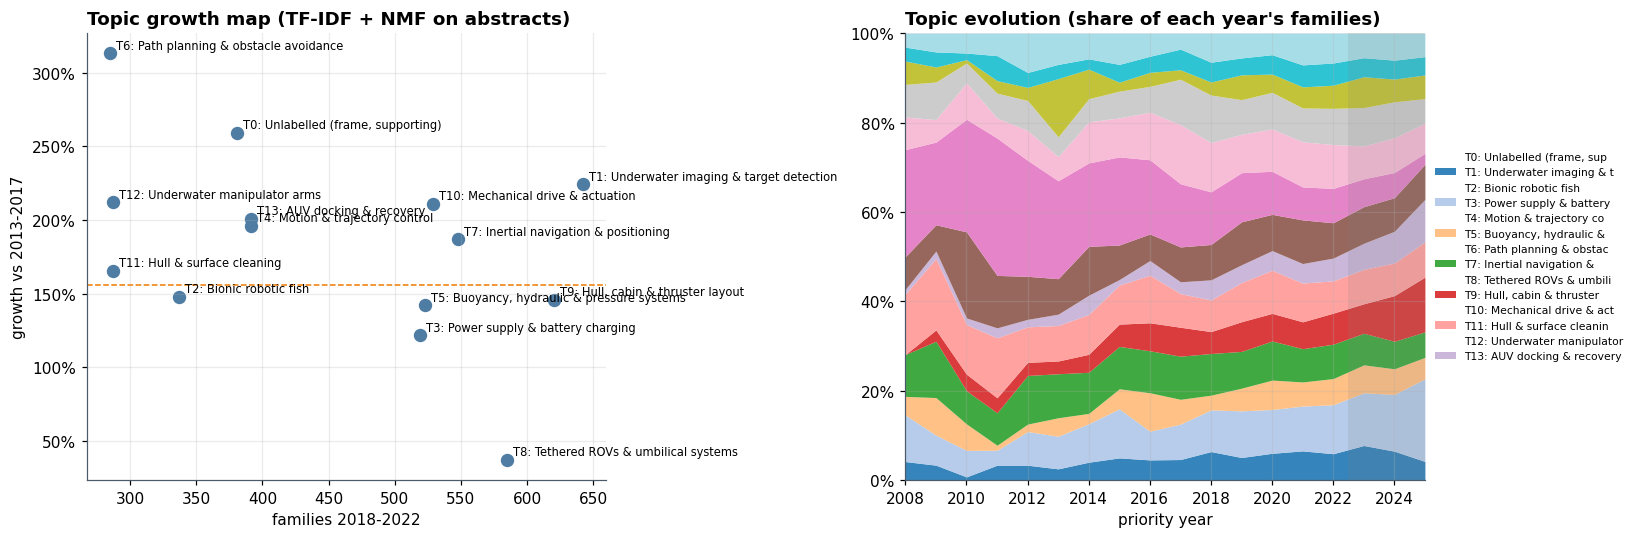

,topic label (draft),families past,families recent,growth (%),relative recency,international share,China share (first filing),top words
6,Path planning & obstacle avoidance,69,285,+313%,1.07,3%,95%,"path, planning, path planning, obstacle, algorithm, avoidance, environment, optimization, obstacle avoidance"
0,"Unlabelled (frame, supporting)",106,381,+259%,1.04,2%,95%,"frame, supporting, fixing, mounting, upper, guide, assembly, lower, structure"
1,Underwater imaging & target detection,198,642,+224%,1.03,6%,86%,"image, data, detection, target, processing, sonar, information, network, feature"
12,Underwater manipulator arms,92,287,+212%,1.03,7%,87%,"arm, mechanical, mechanical arm, operation, joint, grabbing, arms, manipulator, freedom"
10,Mechanical drive & actuation,170,529,+211%,1.03,6%,88%,"driving, motor, shaft, mechanism, rotating, gear, rotate, drive, driving mechanism"
13,AUV docking & recovery,130,391,+201%,1.02,10%,82%,"auv, autonomous, docking, recovery, auv autonomous, auvs, station, autonomous auv, butt joint"
4,Motion & trajectory control,132,391,+196%,1.05,3%,96%,"control, tracking, controller, trajectory, state, error, motion, trajectory tracking, disturbance"
7,Inertial navigation & positioning,191,548,+187%,1.00,6%,82%,"navigation, positioning, position, information, measurement, inertial, acoustic, inertial navigation, precision"
11,Hull & surface cleaning,108,287,+166%,1.02,7%,79%,"cleaning, surface, cleaning cleaning, water, ship, cleaned, brush, hull, frame"
2,Bionic robotic fish,136,337,+148%,1.04,5%,91%,"fish, robotic, robotic fish, bionic, fin, tail, bionic robotic, tail fin, head"


In [37]:
tp = docs[docs["topic"] >= 0]
tpast = tp[tp["family_year"].between(*PAST)].groupby("topic").size()
trec = tp[tp["family_year"].between(*RECENT)].groupby("topic").size()
tg = pd.DataFrame({"topic label (draft)": topic_labels, "families past": tpast, "families recent": trec}).fillna({"families past": 0, "families recent": 0})
tg["growth (%)"] = (tg["families recent"] / tg["families past"].replace(0, np.nan) - 1) * 100
tg["relative recency"] = tp[tp["family_year"] <= LAST].groupby("topic").apply(lambda d: recency(d.groupby("family_year").size())) / R_sector
tg["international share"] = tp.groupby("topic")["is_international"].mean()
tg["China share (first filing)"] = tp.groupby("topic")["first_office"].apply(lambda s: (s == "CN").mean())
tg["top words"] = tg.index.map(topic_words)
topic_share = tp[tp["family_year"].between(2008, YEAR_MAX)].pipe(lambda d: pd.crosstab(d["family_year"], d["topic"], normalize="index")) * 100
save_table(tg, "subfields_topics")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.scatter(tg["families recent"], tg["growth (%)"], s=60, color=BLUE)
for k, r in tg.iterrows():
    ax.annotate(f"T{k}: {topic_labels[k]}", (r["families recent"], r["growth (%)"]), xytext=(4, 3), textcoords="offset points", fontsize=7.5)
ax.axhline(sector_growth, color=ORANGE, ls="--", lw=1)
ax.set(title="Topic growth map (TF-IDF + NMF on abstracts)", xlabel="families 2018-2022", ylabel="growth vs 2013-2017")
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax = axes[1]
topic_share.plot.area(ax=ax, cmap="tab20", alpha=0.9, lw=0, legend=False)
shade(ax)
ax.set(title="Topic evolution (share of each year's families)", xlabel="priority year", ylim=(0, 100), xlim=(2008, YEAR_MAX))
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.legend([f"T{k}: {topic_labels[k][:22]}" for k in topic_share.columns], ncol=1, fontsize=7, frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
save(fig, "s2_topics")
plt.show()
display(tg.sort_values("growth (%)", ascending=False).style.format({
    "families past": "{:,.0f}", "families recent": "{:,.0f}", "growth (%)": "{:+.0f}%",
    "relative recency": "{:.2f}", "international share": "{:.0%}", "China share (first filing)": "{:.0%}"
}))

**Do CPC and text agree?** Cross-tabulate the topics with the largest CPC subclasses: a topic that spreads over many
CPC subclasses is a *cross-cutting* subfield the classification does not see (e.g. path planning: G05D, G01C, G06N).

In [38]:
top10_sub = share_by(sub_c, "subclass", top=10).index.drop("Other")
ct = tp[["docdb_family_id", "topic"]].merge(fsub[fsub.subclass.isin(top10_sub)], on="docdb_family_id")
ct = ct.pivot_table(index="topic", columns="subclass", values="weight", aggfunc="sum", fill_value=0)
ct = ct.div(ct.sum(axis=1), axis=0)[list(top10_sub)]
ct.index = [f"T{k}: {topic_words[k][:40]}" for k in ct.index]
ct.style.format("{:.0%}").background_gradient(cmap="Blues", axis=None)

subclass,B63G,B63C,G05D,B63B,B63H,G01S,G01C,B25J,G05B,G06F
"T0: frame, supporting, fixing, mounting, upp",23%,46%,0%,22%,2%,1%,0%,5%,1%,0%
"T1: image, data, detection, target, processi",12%,14%,16%,3%,1%,19%,8%,2%,6%,19%
"T2: fish, robotic, robotic fish, bionic, fin",18%,25%,4%,3%,34%,1%,1%,6%,5%,3%
"T3: power, supply, power supply, communicati",28%,25%,8%,7%,7%,6%,1%,5%,9%,3%
"T4: control, tracking, controller, trajector",5%,3%,50%,1%,1%,1%,1%,2%,31%,6%
"T5: pressure, valve, oil, water, pump, air,",45%,27%,2%,13%,6%,1%,1%,3%,1%,2%
"T6: path, planning, path planning, obstacle,",3%,2%,53%,1%,0%,3%,21%,2%,4%,11%
"T7: navigation, positioning, position, infor",7%,5%,8%,3%,0%,29%,40%,1%,1%,6%
"T8: cable, rov, operated, remotely, remotely",35%,24%,6%,23%,2%,4%,1%,4%,1%,1%
"T9: cabin, main, propeller, adjusting, buoya",44%,27%,4%,8%,10%,1%,1%,3%,0%,1%


In [39]:
if RUN_PATSTAT:   # TIP only (or any machine with the models): Patent SBERT + BERTopic, Tutorial 2 nb 21 §9.3
    from bertopic import BERTopic
    from hdbscan import HDBSCAN
    from sentence_transformers import SentenceTransformer
    from sklearn.feature_extraction.text import CountVectorizer
    from umap import UMAP
    en = fam.loc[fam.abstract_en.notna()].copy()
    sbert = SentenceTransformer(C.SBERT_MODEL)
    E = sbert.encode(en.abstract_en.tolist(), batch_size=64, show_progress_bar=True, normalize_embeddings=True)
    bt = BERTopic(embedding_model=sbert, umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=42),
                  hdbscan_model=HDBSCAN(min_cluster_size=60, metric="euclidean", prediction_data=True),
                  vectorizer_model=CountVectorizer(stop_words=list(ENGLISH_STOP_WORDS | SECTOR_WORDS | PATENT_STOP), ngram_range=(1, 2)))
    en["bertopic"], _ = bt.fit_transform(en.abstract_en.tolist(), embeddings=E)
    display(bt.get_topic_info().head(25))
    en[["docdb_family_id", "bertopic"]].to_csv(OUT / "bertopic_assignments.csv", index=False)
    # agreement with the NMF topics (adjusted Rand index): low values = the two definitions disagree, discuss them
    from sklearn.metrics import adjusted_rand_score
    both_ = en.merge(docs[["docdb_family_id", "topic"]], on="docdb_family_id").query("bertopic >= 0 and topic >= 0")
    print("ARI NMF vs BERTopic:", round(adjusted_rand_score(both_.topic, both_.bertopic), 3))
else:
    print("RUN_PATSTAT = False: BERTopic not run (needs sentence-transformers, umap, hdbscan, bertopic)")

RUN_PATSTAT = False: BERTopic not run (needs sentence-transformers, umap, hdbscan, bertopic)


## 2.5 Who leads where? Specialisation of players and countries

**Revealed Technological Advantage** (RTA, Patel & Pavitt, 1997; the Balassa index on patents):
$RTA_{i,s}=\dfrac{F_{i,s}/\sum_s F_{i,s}}{\sum_i F_{i,s}/\sum_{i,s}F_{i,s}}$, where $F_{i,s}$ are the families of actor
$i$ in subfield $s$. RTA > 1: the actor is specialised in that subfield relative to the sector. It tells *where* each
competitor is strong (a niche player can lead a subfield while being small overall), and later, in Step 6, whether
a target complements or duplicates the client (Teece, 1986). Read RTA only for actors with enough families: with 3
families (the client) one family moves the index a lot.

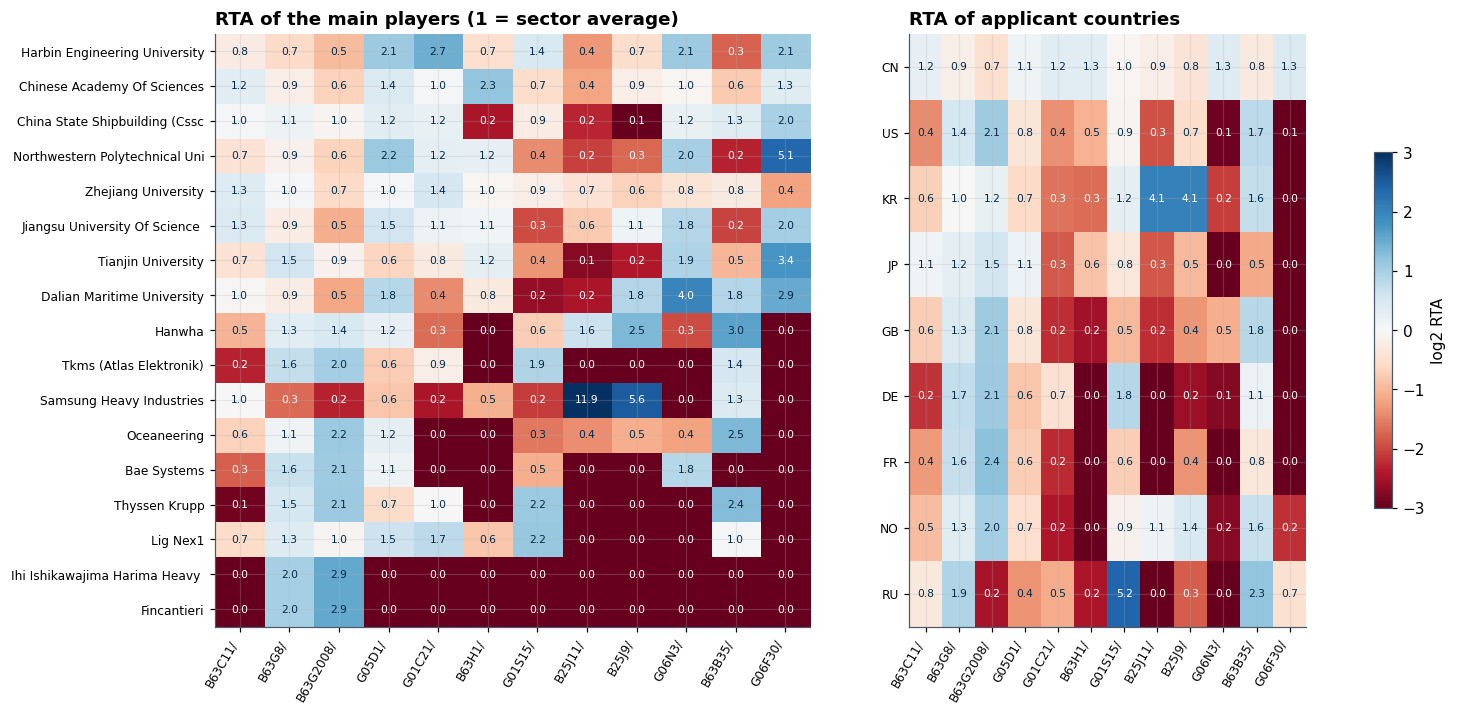

main_group,B63C11/,B63G8/,B63G2008/,G05D1/,G01C21/,B63H1/,G01S15/,B25J11/,B25J9/,G06N3/,B63B35/,G06F30/
country,,,,,,,,,,,,
CN,1.18,0.88,0.72,1.10,1.25,1.25,0.95,0.86,0.77,1.31,0.81,1.34
US,0.38,1.43,2.08,0.78,0.39,0.49,0.94,0.27,0.69,0.13,1.72,0.12
KR,0.61,1.00,1.16,0.68,0.32,0.31,1.21,4.06,4.08,0.24,1.63,0.00
JP,1.07,1.20,1.48,1.13,0.28,0.56,0.78,0.28,0.51,0.00,0.46,0.00
GB,0.60,1.35,2.11,0.77,0.22,0.17,0.51,0.22,0.40,0.47,1.77,0.00
DE,0.22,1.66,2.14,0.56,0.73,0.00,1.81,0.00,0.17,0.15,1.13,0.00
FR,0.41,1.61,2.36,0.60,0.21,0.00,0.60,0.00,0.39,0.00,0.79,0.00
NO,0.53,1.29,2.02,0.71,0.18,0.00,0.92,1.11,1.36,0.15,1.59,0.22
RU,0.81,1.87,0.18,0.39,0.46,0.18,5.20,0.00,0.28,0.00,2.26,0.73


In [40]:
key_sf = mapped.head(12).index.tolist()
mga = mg[mg.main_group.isin(key_sf)].merge(links[["docdb_family_id", "applicant", "country"]], on="docdb_family_id")
def rta_table(df, actor, actors):
    F = df.pivot_table(index=actor, columns="main_group", values="docdb_family_id", aggfunc="nunique", fill_value=0)
    rta = (F.div(F.sum(axis=1), axis=0)) / (F.sum(axis=0) / F.values.sum())
    return F.reindex(actors), rta.reindex(actors)[key_sf]

actors = list(players.index[:8]) + list(firms[firms.country != "CN"].index[:8]) + ([CLIENT] if CLIENT in players.index else [])
actors = list(dict.fromkeys(actors))
F_a, rta_a = rta_table(mga, "applicant", actors)
ctry_list = ["CN", "US", "KR", "JP", "GB", "DE", "FR", "NO", "RU"]
F_c, rta_c = rta_table(mga.drop_duplicates(["docdb_family_id", "main_group", "country"]), "country", ctry_list)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1.5, 1]})
for ax, rta, title in [(axes[0], rta_a, "RTA of the main players (1 = sector average)"), (axes[1], rta_c, "RTA of applicant countries")]:
    im = ax.imshow(np.log2(rta.astype(float).clip(lower=0.125, upper=8)), cmap="RdBu", vmin=-3, vmax=3, aspect="auto")
    ax.set_xticks(range(len(key_sf)), key_sf, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(rta)), [str(i) if len(str(i)) <= 3 else str(i)[:30].title() for i in rta.index], fontsize=8)
    for i in range(rta.shape[0]):
        for j in range(rta.shape[1]):
            v = rta.iat[i, j]
            if pd.notna(v): ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7, color="white" if abs(np.log2(max(v, .125))) > 1.6 else NAVY)
    ax.set_title(title)
plt.colorbar(im, ax=axes, shrink=0.6, label="log2 RTA"); save(fig, "s2_rta_heatmaps"); plt.show()
save_table(rta_a.round(3), "rta_players")
save_table(rta_c.round(3), "rta_countries")
rta_c.round(2)

## 2.6 Collaboration: who works with whom?

Co-applications (a family filed by two or more applicant groups) are a trace of R&D alliances, of firm–university
collaboration and of public programmes (IM_Theory_2: universities transfer knowledge through licences, spin-offs
and industry partners). The network of co-applicants among the 60 largest applicants shows the alliances; node size
= families, colour = type. Betweenness centrality identifies the *brokers* (IM_Theory_2, intermediation), which are
natural partners for an entrant such as the client.

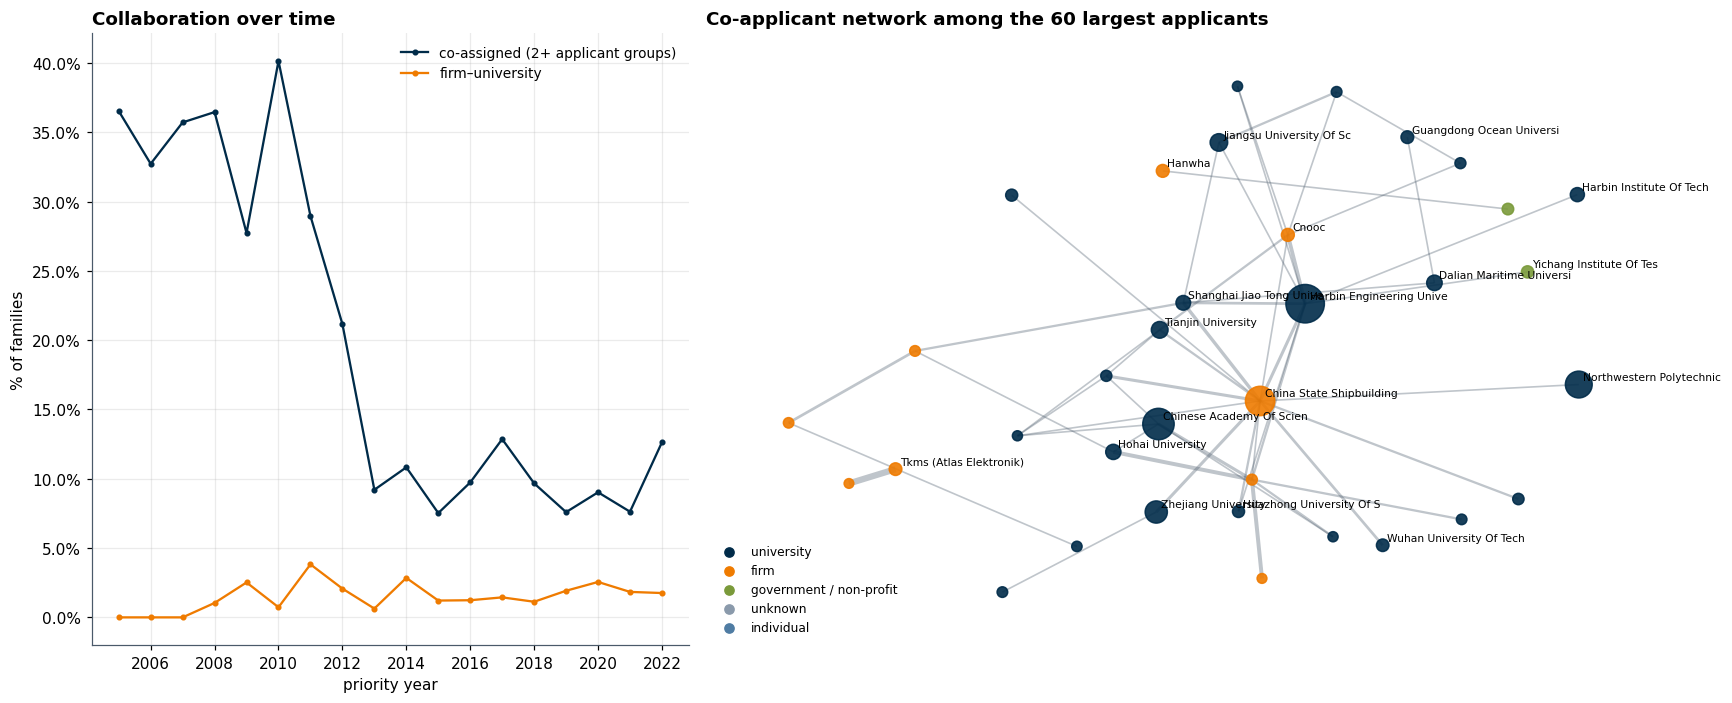

,partners (degree),betweenness,families,type
CHINA STATE SHIPBUILDING (CSSC),31,0.011,697,firm
SHANGHAI JIAO TONG UNIVERSITY,25,0.006,144,university
ZHEJIANG UNIVERSITY,29,0.005,381,university
HARBIN ENGINEERING UNIVERSITY,29,0.004,1226,university
CHINA THREE GORGES,15,0.004,60,firm
CNOOC,26,0.003,102,firm
CHINESE ACADEMY OF SCIENCES,28,0.003,804,university
CHINA HUANENG GROUP,11,0.003,57,firm
JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY,21,0.002,223,university
NANJING HYDRAULIC RESEARCH INSTITUTE,9,0.002,15,government / non-profit


In [41]:
co = fam[fam.family_year.between(2005, LAST)].groupby("family_year")[["co_assigned", "firm_univ_collab"]].agg(lambda s: s.astype(str).str.lower().eq("true").mean()) * 100
multi = links.groupby("docdb_family_id").filter(lambda d: len(d) > 1)
edges = (multi.merge(multi, on="docdb_family_id").query("applicant_x < applicant_y")
              .groupby(["applicant_x", "applicant_y"]).size().rename("weight").reset_index())
G = nx.Graph(); G.add_weighted_edges_from(edges.itertuples(index=False, name=None))
TOPNET = list(players.index[:60])
H = G.subgraph([n for n in TOPNET if n in G]).copy()
H.remove_nodes_from([n for n in list(H) if H.degree(n) == 0])
btw = pd.Series(nx.betweenness_centrality(G, weight=None, k=min(500, len(G)), seed=42)).sort_values(ascending=False)
deg = pd.Series(dict(G.degree())).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.6]})
co.plot(ax=axes[0], marker="o", ms=3, color=[NAVY, ORANGE]); axes[0].yaxis.set_major_formatter(PercentFormatter(100))
axes[0].xaxis.set_major_locator(plt.MaxNLocator(integer=True)); axes[0].set(title="Collaboration over time", xlabel="priority year", ylabel="% of families"); axes[0].legend(["co-assigned (2+ applicant groups)", "firm–university"], frameon=False, fontsize=9)
pos = nx.spring_layout(H, seed=3, k=0.9, weight="weight")
tcol = {"university": NAVY, "firm": ORANGE, "government / non-profit": GREEN, "unknown": MID, "individual": BLUE}
nx.draw_networkx_edges(H, pos, ax=axes[1], width=[0.4 + np.log1p(H[u][v]["weight"]) for u, v in H.edges], alpha=0.35, edge_color=GREY)
nx.draw_networkx_nodes(H, pos, ax=axes[1], node_size=[20 + players.loc[n, "families"] / 2 for n in H], node_color=[tcol.get(players.loc[n, "type"], MID) for n in H], alpha=0.9)
for n in sorted(H, key=lambda n: -players.loc[n, "families"])[:18]:
    axes[1].annotate(n.title()[:24], pos[n], fontsize=7, xytext=(3, 3), textcoords="offset points")
for t, c in tcol.items(): axes[1].scatter([], [], color=c, label=t)
axes[1].legend(frameon=False, fontsize=8, loc="lower left"); axes[1].axis("off"); axes[1].set_title("Co-applicant network among the 60 largest applicants")
plt.tight_layout(); save(fig, "s2_collaboration"); plt.show()
short(pd.DataFrame({"partners (degree)": deg, "betweenness": btw, "families": players["families"], "type": players["type"]}).dropna(subset=["partners (degree)"]).sort_values("betweenness", ascending=False).head(12)).style.format({"betweenness": "{:.3f}", "partners (degree)": "{:.0f}", "families": "{:.0f}"})

## 2.7 Where does the client stand?

Fincantieri (with WASS, Graal Tech, WSense, NextGeo, Defcomm: `GROUP_ALIASES`) against the sector: its families,
their subfields and what they look like. A tiny portfolio is itself the finding: the client has the
complementary assets (shipyards, naval programmes, customers) but not the technology portfolio, which is the
classic setting for an acquisition or a partnership (Teece, 1986): Step 6.

In [42]:
cl_ids = set(appl.loc[appl.applicant == CLIENT, "docdb_family_id"])
cl = fam[fam.docdb_family_id.isin(cl_ids)][["docdb_family_id", "family_year", "first_office", "offices", "granted_any", "fwd_cits_5y", "title_en"]]
cl_sub = mg[mg.docdb_family_id.isin(cl_ids)].groupby("main_group")["docdb_family_id"].nunique().sort_values(ascending=False)
KEY["client_families"] = int(len(cl_ids))
print(f"{CLIENT}: {len(cl_ids)} families; subfields: {cl_sub.to_dict()}")
cl.sort_values("family_year")

FINCANTIERI: 3 families; subfields: {'F42B19/': 2, 'H01M10/': 2, 'H01M50/': 2, 'B63G2008/': 1, 'B63H21/': 1, 'B63G8/': 1, 'G01S5/': 1, 'H01M6/': 1}


,docdb_family_id,family_year,first_office,offices,granted_any,fwd_cits_5y,title_en
364,40433835,2008,EP,EP,True,3,System and method for acoustic tracking an underwater ve...
1206,50513984,2014,US,EP US,True,1,Underwater vehicle provided with heat exchanger
4530,66867675,2019,IT,EP FI IT US,True,0,"Valve system for an electrochemical power supply source,..."


**Who is strong where the client is (or wants to be)?** For the subfields of the client's families, and for the
fastest-growing large subfields, the top non-university owners: the first list of *partners or targets* to score in
Steps 3–5.

In [43]:
cl_main = [s for s in cl_sub.index if mg[mg.main_group == s].docdb_family_id.nunique() >= 15]   # client subfields large enough to read
focus = list(dict.fromkeys(cl_main + list(mapped.sort_values("growth vs sector (pp)", ascending=False).head(4).index)))
rows = []
for s in focus:
    d = mg[(mg.main_group == s) & mg.family_year.between(2013, LAST)].merge(links[["docdb_family_id", "applicant", "type", "country"]], on="docdb_family_id")
    d = d[d.type.isin(["firm", "unknown", "government / non-profit"])]
    top = d.groupby("applicant")["docdb_family_id"].nunique().sort_values(ascending=False).head(5)
    rows.append({"subfield": s, "title (verify)": MAIN_GROUP_TITLES.get(s, ""), "families 2013-2022": mg[(mg.main_group == s) & mg.family_year.between(2013, LAST)].docdb_family_id.nunique(),
                 "top non-university owners (families)": "; ".join(f"{a.title()[:28]} ({n})" for a, n in top.items())})
pd.DataFrame(rows).style.hide(axis="index")

subfield,title (verify),families 2013-2022,top non-university owners (families)
F42B19/,"Marine torpedoes, e.g. launched by surface vessels or submarines",37,Hamilton Sundstrand (5); Tkms (Atlas Elektronik) (4); Hanwha (3); Boeing (2); Agency For Defense Developme (2)
H01M10/,Secondary cells; manufacture thereof,28,Hanwha (2); Fincantieri (2); 7Th O 5 Research Institute O (1); Aktsionernoe Obshchestvo Tse (1); Federalnoe Gosudarstvennoe U (1)
H01M50/,Constructional details or processes of manufacture of non-active parts of batteries,23,Fincantieri (2); Bae Systems (1); Agency For Defense Developme (1); China State Shipbuilding (Cs (1); Eelume (1)
B63G2008/,Unmanned underwater vessels [UUV] (indexing scheme),1709,China State Shipbuilding (Cs (46); United States Of America As (37); Tkms (Atlas Elektronik) (25); Oceaneering (23); Hanwha (23)
B63H21/,Use of propulsion power plant or units on vessels,184,China State Shipbuilding (Cs (5); Suzhou Yijijie Electronic Te (4); Mitsubishi Heavy Industries (4); Suzhou Huibei Electronic Tec (3); Shenzhen Kuang Chi Spatial T (2)
B63G8/,"Underwater vessels, e.g. submarines",2502,China State Shipbuilding (Cs (82); United States Of America As (33); Hanwha (28); Tkms (Atlas Elektronik) (25); Hangzhou Changdong Intellige (20)
G01S5/,Position-fixing by coordinating two or more direction or position-line determinations,133,China State Shipbuilding (Cs (7); Electronic Science Research (3); First Institute Of Oceanogra (2); Kawasaki Heavy Industries (2); Hunan Puli Ocean Science And (2)
G06F17/,"Digital computing or data processing equipment or methods, specially adapted for specific functions",62,Peoples Liberation Army 6154 (2); Xian Aerospace Tianhui Data (2); China Construction Third Eng (1); Hangzhou Duyuan Information (1); Hunan Aerospace Electromecha (1)
G06F18/,Pattern recognition,77,Qingdao Pengpai Ocean Explor (4); Xian Aerospace Tianhui Data (2); China Institute Of Water Res (1); Defense Technology Innovatio (1); Guangzhou Huitong Technology (1)
G06N3/,"Computing arrangements based on biological models, e.g. neural networks",173,Qingdao Pengpai Ocean Explor (4); Bae Systems (3); China State Shipbuilding (Cs (3); Hunan Guotian Electronic Tec (2); Bhatnagar Priya (1)


## 2.8 PEST analysis (mandatory table)

Patent data say *who, what, where*; not *why*. The PEST table needs sources outside PATSTAT (Tutorial 1 nb 11
§5.4): identify the factors, analyse their effects, classify them as opportunities or threats, prioritise, derive
strategic actions. Below, the factors we expect, each paired with the **patent evidence from this notebook** that
supports or questions it. Every factor must be backed by a cited source before it goes in the deck (defence
budgets, NATO / EU seabed-infrastructure plans, export controls, offshore-energy investment, etc.): the bracketed
items are *to verify*, not facts.

In [44]:
sub_tech = sub.dropna(subset=["weight_tech"])
ai_share = (sub_tech[sub_tech["subclass"].isin(["G06N", "G06V", "G06T", "G06F"])].groupby("family_year")["weight_tech"].sum()
            / sub_tech.groupby("family_year")["weight_tech"].sum()).fillna(0)
y02e = (sub[sub["subclass"].eq("Y02E")].groupby("family_year")["weight"].sum()
        / sub.groupby("family_year")["weight"].sum()).fillna(0)

_diversifiers = (', '.join(a.title()[:28] for a in players[(players['status'] == 'entrant') & players.index.str.contains('GRID|CNOOC|ARAMCO|THREE GORGES|HUANENG')].index[:5])) or 'none flagged'


def _growth(key):
    """growth (%) of a CPC main group between the two windows, from the table of 2.4.1 (or 'n/a')."""
    try:
        v = mapped.loc[key, "growth (%)"]
        return f"{v:+.0f}%" if pd.notna(v) else "n/a (no family in the past window)"
    except KeyError:
        return "n/a"


def _topic_growth(label_part):
    """growth (%) of the topic whose draft label contains label_part (from the topic table of 2.4.2), or 'n/a'."""
    try:
        k = next(i for i, name in topic_labels.items() if label_part.lower() in name.lower())
        v = tg.loc[k, "growth (%)"]
        return f"{topic_labels[k]}: {v:+.0f}%" if pd.notna(v) else "n/a"
    except (StopIteration, KeyError, NameError):
        return "n/a"


ev_signal = {
    "AI / vision / computing share of the CPC mix (non-Y), 2013-17 → 2018-22":
        f"{ai_share.loc[PAST[0]:PAST[1]].mean():.1%} → {ai_share.loc[RECENT[0]:RECENT[1]].mean():.1%}",
    "Energy (Y02E) tagging share, 2013-17 → 2018-22":
        f"{y02e.loc[PAST[0]:PAST[1]].mean():.1%} → {y02e.loc[RECENT[0]:RECENT[1]].mean():.1%}",
    "Families first filed in China (complete years)": pct(KEY["share_first_filed_CN"]),
    "Share owned by universities (fractional, complete years)": pct(KEY["share_university"]),
    "US Navy / defence bodies among top owners":
        ", ".join([a.title()[:40] for a in players.index[:40] if re.search("NAVY|DEFEN|MILITARY|VOENN|DIRECTION GENERALE DE L ARMEMENT", a)]),
}
pest = pd.DataFrame([
    ("Political", "Defence and naval spending; seabed-warfare and critical-infrastructure protection programmes [source]", "opportunity", "US Navy / Russian military bodies among owners; secrecy limits patent visibility (Step 1 §7)"),
    ("Political", "Chinese industrial policy and patent subsidies [Dang & Motohashi 2015]", "threat (competition) / bias (data)", "share first filed in China; low internationalisation of CN families (Step 1 §6.2)"),
    ("Political", "Export controls and dual-use rules on UUVs [source]", "threat", "few cross-bloc filings in the origin × destination matrix (Step 1 §6.2)"),
    ("Economic", "Offshore energy (oil & gas decommissioning, offshore wind O&M) demand for inspection [source]", "opportunity", f"Y02E share; diversifying energy entrants in 2.2: {_diversifiers}"),
    ("Economic", "Consolidation of the market: acquisitions of UUV makers by defence primes [source: e.g. Fincantieri–WASS 2025]", "opportunity / threat", "group aliases in config; concentration trend (2.1.1)"),
    ("Social", "Safety: replacing divers in hazardous subsea work; ocean science and environmental monitoring [source]", "opportunity", "B63C11/ underwater work growth and monitoring topics (2.4)"),
    ("Technological", "Autonomy and AI (navigation, path planning, perception) [source]", "opportunity", f"growth of G05D1/ ({_growth('G05D1/')}), G06N3/ ({_growth('G06N3/')}); topic {_topic_growth('path planning')} (2.4)"),
    ("Technological", "Underwater communication and energy (docking, charging, batteries) as bottlenecks [source]", "opportunity", f"H02J7/ ({_growth('H02J7/')}); topic {_topic_growth('docking')} (2.4)"),
], columns=["factor", "change (to verify with a source)", "opportunity / threat", "patent evidence in this notebook"])
save_table(pest, "pest", index=False)
display(pd.Series(ev_signal, name="patent signals for the PEST").to_frame())
display(pest.style.hide(axis="index"))

,patent signals for the PEST
"AI / vision / computing share of the CPC mix (non-Y), 2013-17 → 2018-22",2.4% → 6.1%
"Energy (Y02E) tagging share, 2013-17 → 2018-22",1.0% → 1.2%
Families first filed in China (complete years),73.1%
"Share owned by universities (fractional, complete years)",48.0%
US Navy / defence bodies among top owners,United States Of America As Represented


factor,change (to verify with a source),opportunity / threat,patent evidence in this notebook
Political,Defence and naval spending; seabed-warfare and critical-infrastructure protection programmes [source],opportunity,US Navy / Russian military bodies among owners; secrecy limits patent visibility (Step 1 §7)
Political,Chinese industrial policy and patent subsidies [Dang & Motohashi 2015],threat (competition) / bias (data),share first filed in China; low internationalisation of CN families (Step 1 §6.2)
Political,Export controls and dual-use rules on UUVs [source],threat,few cross-bloc filings in the origin × destination matrix (Step 1 §6.2)
Economic,"Offshore energy (oil & gas decommissioning, offshore wind O&M) demand for inspection [source]",opportunity,"Y02E share; diversifying energy entrants in 2.2: China Huaneng Group, Sgcc State Grid Corporation , Guangdong Power Grid, Aramco Services, State Grid Hunan Electric Po"
Economic,Consolidation of the market: acquisitions of UUV makers by defence primes [source: e.g. Fincantieri–WASS 2025],opportunity / threat,group aliases in config; concentration trend (2.1.1)
Social,Safety: replacing divers in hazardous subsea work; ocean science and environmental monitoring [source],opportunity,B63C11/ underwater work growth and monitoring topics (2.4)
Technological,"Autonomy and AI (navigation, path planning, perception) [source]",opportunity,"growth of G05D1/ (+210%), G06N3/ (+1722%); topic Path planning & obstacle avoidance: +313% (2.4)"
Technological,"Underwater communication and energy (docking, charging, batteries) as bottlenecks [source]",opportunity,H02J7/ (+281%); topic AUV docking & recovery: +201% (2.4)


## 3 · Robustness summary and exports

Every headline number on the three samples. If a conclusion holds on *all*, *without block-6-only* and
*international*, it does not depend on block 6 nor on domestic Chinese filing; if it changes, say so on the slide.

In [45]:
def logistic(t, K, r, t0):
    return K / (1 + np.exp(-r * (t - t0)))


def s_curve_inflection(yearly, last=LAST):
    s = yearly.loc[:last].cumsum()
    t, y = s.index.values.astype(float), s.values.astype(float)
    try:
        p, _ = curve_fit(logistic, t, y, p0=[y[-1] * 2, 0.3, t[-1]],
                         bounds=([y[-1], 0.01, t[0]], [y[-1] * 50, 2.0, t[-1] + 30]), maxfev=20000)
        return float(p[2])
    except Exception:
        return np.nan


def headline(name, ids):
    f = fam[fam["docdb_family_id"].isin(ids)]
    fc = f[f["family_year"] <= LAST]
    y = fc.groupby("family_year").size().reindex(range(YEAR_MIN, LAST + 1), fill_value=0)
    l = links_c[links_c["docdb_family_id"].isin(ids)]
    x = l.groupby("applicant")["docdb_family_id"].nunique()
    top = x.sort_values(ascending=False)
    t = l.groupby("type")["weight"].sum() / l["weight"].sum()
    return pd.Series({
        "families (<=2022)": len(fc),
        f"CAGR 2012-{LAST}": cagr(y.get(2012, np.nan), y.get(LAST, np.nan), LAST - 2012),
        "first filed in CN": (fc["first_office"].astype(str).str.strip() == "CN").mean(),
        "university share": t.get("university", 0),
        "firm share (incl. unclassified)": t.get("firm", 0) + t.get("unknown", 0),
        "HH": herfindahl(x),
        "CR4": concentration_ratio(x, 4),
        "top applicant": top.index[0].title() if len(top) else "–",
        "top non-CN firm": next((a.title() for a in top.index if a in firms.index and firms.loc[a, "country"] != "CN"), "–"),
        "S-curve inflection": s_curve_inflection(y),
    })


robust = pd.DataFrame({name: headline(name, ids) for name, ids in SAMPLES.items()}).T
save_table(robust, "robustness_summary")
display(robust.style.format({
    "families (<=2022)": "{:,.0f}", f"CAGR 2012-{LAST}": "{:.1%}",
    "first filed in CN": "{:.0%}", "university share": "{:.0%}",
    "firm share (incl. unclassified)": "{:.0%}", "HH": "{:.4f}",
    "CR4": "{:.1%}", "S-curve inflection": "{:.1f}"
}))

,families (<=2022),CAGR 2012-2022,first filed in CN,university share,firm share (incl. unclassified),HH,CR4,top applicant,top non-CN firm,S-curve inflection
all,"9,991",19.9%,73%,48%,37%,0.0099,16.9%,Harbin Engineering University,Hanwha,2024.3
without block-6-only,"7,776",20.0%,72%,49%,37%,0.0106,17.3%,Harbin Engineering University,Hanwha,2023.5
international,"1,107",8.4%,17%,15%,65%,0.0034,7.2%,Tkms (Atlas Elektronik),Tkms (Atlas Elektronik),2021.1


In [46]:
for k, v in list(KEY.items()):
    KEY[k] = float(v) if isinstance(v, (np.floating, np.integer)) else v
(OUT / "key_numbers.json").write_text(json.dumps(KEY, indent=2))
print(f"Saved {len(list(TAB.glob('*.csv')))} tables in {TAB} and {len(list(FIG.glob('*.png')))} figures in {FIG}")
display(pd.Series(KEY).to_frame("value"))

Saved 20 tables in outputs/prod/step2_Landscape/tables and 7 figures in outputs/prod/step2_Landscape/figures


,value
families_total,15755
families_complete_years,9991
share_first_filed_CN,0.731058
share_international,0.1108
share_university,0.48031
share_firm,0.314082
HH_all,0.009852
CR4_all,0.16916
one_over_HH_all,101.497642
HH_first_window,0.01185


## 4 · Consistency checks and archive export

In [47]:
checks = {
    "one row per family in fam": fam["docdb_family_id"].is_unique,
    "HH in (0, 1]": 0 < KEY["HH_all"] <= 1,
    "CR4 in (0, 1]": 0 < KEY["CR4_all"] <= 1,
    "shortlist includes client": CLIENT in shortlist.index,
    "all shortlist firms meet volume gate (or client)": bool(((shortlist["families"] >= MIN_FAMILIES_SCORE) | shortlist["is client"]).all()),
    "applicant weights sum to 1 per family": bool(np.allclose(appl.groupby("docdb_family_id")["weight"].sum(), 1)),
    "one row per applicant group in players": bool(players.index.is_unique),
    "all concentration windows are full": bool(cons["window"].map(lambda w: int(w.split("-")[1]) - int(w.split("-")[0]) + 1).eq(WINDOW).all()),
    "entrants share in [0, 100]": bool(ee["entrants' share of families (%)"].dropna().between(0, 100).all()) if "entrants' share of families (%)" in ee else True,
    "sample sizes are nested": SAMPLES["without block-6-only"] <= SAMPLES["all"] and SAMPLES["international"] <= SAMPLES["all"],
}
display(pd.Series(checks, name="ok").to_frame())
assert all(checks.values()), "a check failed: see the table above"



,ok
one row per family in fam,True
"HH in (0, 1]",True
"CR4 in (0, 1]",True
shortlist includes client,True
all shortlist firms meet volume gate (or client),True
applicant weights sum to 1 per family,True
one row per applicant group in players,True
all concentration windows are full,True
"entrants share in [0, 100]",True
sample sizes are nested,True


### Which figures go in the deck (≤ 10 figures and tables in the whole main deck, Steps 1-6)

Steps 1-2 should use **at most 7**, so that three remain for Steps 3-6 (the Magic Quadrant, the score table, the recommendation).
Everything else goes in the technical appendix.

| Slot | Figure / table | File |
|---|---|---|
| Step 1 · size and growth | families per year (truncated years shaded) + growth index vs all patents and B63, one panel | `fig_deck_volume_growth.png` (Step 1 notebook) |
| Step 1 · technology | CPC mix over time (the table with the official titles goes in the appendix) | `fig_cpc_mix.png`, `tab_cpc_subclasses.csv` |
| Step 1 · geography and protection | origin and internationalisation, with the argued paragraph on patents vs secrecy | `fig_origin.png`, `tab_market_vs_patent_leaders.csv` |
| Step 2 · competition | table of the top players (firms outside China + universities), with HH and CR4 in the text | `players_all.csv` |
| Step 2 · entry | entry and exit of applicants over time | `s2_entry_exit.png` |
| Step 2 · subfields | growth map / maturity matrix (borderline subfields marked) | `s2_subfield_growth_maturity.png` |
| Step 2 · PEST | the PEST table (mandatory) | `pest.csv` |

That is 7 items for Steps 1-2 if the CPC table stays in the appendix. The concentration figure (`s2_concentration_over_time.png`) goes in the appendix.
